In [52]:
# ============================================================
# EXPERIMENT 6
# End-to-End Study of RNN, LSTM and GRU
# ============================================================

!pip -q install tensorflow scikit-learn pandas matplotlib seaborn requests

import os
import sys
import time
import zipfile
import shutil
import random
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices('GPU'))

SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

# Reproducibility
os.environ["PYTHONHASHSEED"] = str(SEED)

# Create folders
BASE_DIR = Path("/content/experiment6")
GRAPH_DIR = BASE_DIR / "graphs_eps"
RESULT_DIR = BASE_DIR / "results"
MODEL_DIR = BASE_DIR / "models"
VIDEO_DIR = BASE_DIR / "video_data"

for d in [GRAPH_DIR, RESULT_DIR, MODEL_DIR, VIDEO_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("Experiment directory:", BASE_DIR)

TensorFlow: 2.20.0
GPU devices: []
Experiment directory: /content/experiment6


In [53]:
# ============================================================
# GPU CONFIGURATION
# ============================================================

gpus = tf.config.list_physical_devices("GPU")

if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU enabled:", gpus)
    except RuntimeError as e:
        print(e)
else:
    print("WARNING: No GPU detected.")
    print("In Colab use:")
    print("Runtime -> Change runtime type -> T4 GPU")

In Colab use:
Runtime -> Change runtime type -> T4 GPU


In [54]:
# ============================================================
# GRAPH SAVING
# ============================================================

GRAPH_FILES = []

def save_eps(fig, filename):
    """
    Save matplotlib figure as 600 DPI EPS.
    """
    path = GRAPH_DIR / filename

    fig.savefig(
        path,
        format="eps",
        dpi=600,
        bbox_inches="tight"
    )

    GRAPH_FILES.append(path)
    print("Saved:", path)

    return path


def save_and_show(fig, filename):
    save_eps(fig, filename)
    plt.show()
    plt.close(fig)

In [55]:
# ============================================================
# DOWNLOAD UCI HAR DATASET
# ============================================================

UCI_URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"

UCI_ZIP = BASE_DIR / "UCI_HAR.zip"
UCI_EXTRACT = BASE_DIR / "UCI_HAR"

if not UCI_EXTRACT.exists():

    print("Downloading UCI HAR dataset...")

    urllib.request.urlretrieve(
        UCI_URL,
        UCI_ZIP
    )

    print("Download complete.")

    with zipfile.ZipFile(UCI_ZIP, "r") as zip_ref:
        zip_ref.extractall(UCI_EXTRACT)

    print("Dataset extracted.")

else:
    print("Dataset already exists.")

print(list(UCI_EXTRACT.rglob("*"))[:10])

Dataset already exists.
[PosixPath('/content/experiment6/UCI_HAR/UCI HAR Dataset'), PosixPath('/content/experiment6/UCI_HAR/UCI HAR Dataset.names'), PosixPath('/content/experiment6/UCI_HAR/UCI HAR Dataset.zip'), PosixPath('/content/experiment6/UCI_HAR/__MACOSX'), PosixPath('/content/experiment6/UCI_HAR/UCI HAR Dataset/README.txt'), PosixPath('/content/experiment6/UCI_HAR/UCI HAR Dataset/test'), PosixPath('/content/experiment6/UCI_HAR/UCI HAR Dataset/train'), PosixPath('/content/experiment6/UCI_HAR/UCI HAR Dataset/.DS_Store'), PosixPath('/content/experiment6/UCI_HAR/UCI HAR Dataset/features.txt'), PosixPath('/content/experiment6/UCI_HAR/UCI HAR Dataset/activity_labels.txt')]


In [56]:
# ============================================================
# EXTRACT THE ALREADY DOWNLOADED UCI HAR DATASET
# ============================================================

from pathlib import Path
import zipfile

# Your actual folder shown in Colab
UCI_BASE = Path("/content/experiment6/UCI_HAR")

# Find the ZIP file
zip_files = list(UCI_BASE.glob("*.zip"))

print("ZIP files found:")
for z in zip_files:
    print(z)

if len(zip_files) == 0:
    raise FileNotFoundError("No UCI HAR ZIP file found.")

UCI_ZIP = zip_files[0]

print("\nUsing ZIP:")
print(UCI_ZIP)

# Extract
print("\nExtracting dataset...")

with zipfile.ZipFile(UCI_ZIP, "r") as zip_ref:
    zip_ref.extractall(UCI_BASE)

print("Extraction completed!")

ZIP files found:
/content/experiment6/UCI_HAR/UCI HAR Dataset.zip

Using ZIP:
/content/experiment6/UCI_HAR/UCI HAR Dataset.zip

Extracting dataset...
Extraction completed!


In [57]:
# ============================================================
# FIND UCI HAR ROOT AUTOMATICALLY
# ============================================================

# Search recursively for y_train.txt
train_label_files = list(UCI_BASE.rglob("y_train.txt"))

print("y_train.txt files found:")

for f in train_label_files:
    print(f)

if len(train_label_files) == 0:
    raise FileNotFoundError(
        "y_train.txt still not found. Check the ZIP contents."
    )

# y_train.txt is:
# UCI HAR Dataset/train/y_train.txt
#
# Therefore:
# y_train.txt -> parent = train
# train -> parent = UCI HAR Dataset

UCI_ROOT = train_label_files[0].parent.parent

print("\n========================================")
print("       UCI HAR DATASET FOUND")
print("========================================")
print("UCI_ROOT:", UCI_ROOT)
print("Train:", UCI_ROOT / "train")
print("Test :", UCI_ROOT / "test")

y_train.txt files found:
/content/experiment6/UCI_HAR/UCI HAR Dataset/train/y_train.txt

       UCI HAR DATASET FOUND
UCI_ROOT: /content/experiment6/UCI_HAR/UCI HAR Dataset
Train: /content/experiment6/UCI_HAR/UCI HAR Dataset/train
Test : /content/experiment6/UCI_HAR/UCI HAR Dataset/test


In [58]:
# ============================================================
# VERIFY ALL REQUIRED FILES
# ============================================================

required_files = [
    UCI_ROOT / "train" / "y_train.txt",
    UCI_ROOT / "train" / "X_train.txt",
    UCI_ROOT / "train" / "subject_train.txt",

    UCI_ROOT / "test" / "y_test.txt",
    UCI_ROOT / "test" / "X_test.txt",
    UCI_ROOT / "test" / "subject_test.txt",

    UCI_ROOT / "train" / "Inertial Signals" / "body_acc_x_train.txt",
    UCI_ROOT / "train" / "Inertial Signals" / "body_acc_y_train.txt",
    UCI_ROOT / "train" / "Inertial Signals" / "body_acc_z_train.txt",

    UCI_ROOT / "train" / "Inertial Signals" / "body_gyro_x_train.txt",
    UCI_ROOT / "train" / "Inertial Signals" / "body_gyro_y_train.txt",
    UCI_ROOT / "train" / "Inertial Signals" / "body_gyro_z_train.txt",

    UCI_ROOT / "train" / "Inertial Signals" / "total_acc_x_train.txt",
    UCI_ROOT / "train" / "Inertial Signals" / "total_acc_y_train.txt",
    UCI_ROOT / "train" / "Inertial Signals" / "total_acc_z_train.txt",
]

print("Checking required files...\n")

all_found = True

for f in required_files:
    if f.exists():
        print("✓", f.name)
    else:
        print("✗ MISSING:", f)
        all_found = False

print("\n----------------------------------------")

if all_found:
    print("✅ ALL REQUIRED FILES FOUND")
else:
    print("❌ SOME FILES ARE MISSING")

Checking required files...

✓ y_train.txt
✓ X_train.txt
✓ subject_train.txt
✓ y_test.txt
✓ X_test.txt
✓ subject_test.txt
✓ body_acc_x_train.txt
✓ body_acc_y_train.txt
✓ body_acc_z_train.txt
✓ body_gyro_x_train.txt
✓ body_gyro_y_train.txt
✓ body_gyro_z_train.txt
✓ total_acc_x_train.txt
✓ total_acc_y_train.txt
✓ total_acc_z_train.txt

----------------------------------------
✅ ALL REQUIRED FILES FOUND


In [59]:
# # ============================================================
# # ROBUSTLY FIND UCI HAR DATASET
# # ============================================================

# from pathlib import Path

# # Search for the actual y_train.txt file
# train_label_files = list(UCI_EXTRACT.rglob("y_train.txt"))

# print("Files matching y_train.txt:")

# for f in train_label_files:
#     print(f)

# if len(train_label_files) == 0:
#     print("\nDataset was NOT extracted correctly.")
#     print("\nContents of extraction directory:")

#     for item in UCI_EXTRACT.rglob("*"):
#         print(item)

#     raise FileNotFoundError(
#         "Could not find y_train.txt. Dataset download/extraction needs to be repeated."
#     )

# # y_train.txt is inside:
# # UCI HAR Dataset/train/y_train.txt
# #
# # Therefore:
# # y_train.txt parent = train
# # train parent = dataset root

# UCI_ROOT = train_label_files[0].parent.parent

# print("\n======================================")
# print("UCI HAR DATASET FOUND")
# print("======================================")
# print("UCI root:", UCI_ROOT)

# print("\nTrain folder:", UCI_ROOT / "train")
# print("Test folder :", UCI_ROOT / "test")

In [60]:
# ============================================================
# CHECK DATASET
# ============================================================

import numpy as np

y_train = np.loadtxt(
    UCI_ROOT / "train" / "y_train.txt",
    dtype=int
)

y_test = np.loadtxt(
    UCI_ROOT / "test" / "y_test.txt",
    dtype=int
)

print("Number of training samples:", len(y_train))
print("Number of testing samples :", len(y_test))

print("\nUnique training labels:")
print(np.unique(y_train))

print("\nUnique testing labels:")
print(np.unique(y_test))

Number of training samples: 7352
Number of testing samples : 2947

Unique training labels:
[1 2 3 4 5 6]

Unique testing labels:
[1 2 3 4 5 6]


In [61]:
# ============================================================
# VERIFY DATASET STRUCTURE
# ============================================================

required_files = [
    UCI_ROOT / "train" / "y_train.txt",
    UCI_ROOT / "test" / "y_test.txt",
    UCI_ROOT / "train" / "Inertial Signals" / "body_acc_x_train.txt",
    UCI_ROOT / "train" / "Inertial Signals" / "body_gyro_x_train.txt",
    UCI_ROOT / "train" / "Inertial Signals" / "total_acc_x_train.txt"
]

for f in required_files:
    print(
        "✓" if f.exists() else "✗",
        f
    )

if all(f.exists() for f in required_files):
    print("\n✅ UCI HAR dataset is correctly located.")
else:
    print("\n❌ Some required files are missing.")

✓ /content/experiment6/UCI_HAR/UCI HAR Dataset/train/y_train.txt
✓ /content/experiment6/UCI_HAR/UCI HAR Dataset/test/y_test.txt
✓ /content/experiment6/UCI_HAR/UCI HAR Dataset/train/Inertial Signals/body_acc_x_train.txt
✓ /content/experiment6/UCI_HAR/UCI HAR Dataset/train/Inertial Signals/body_gyro_x_train.txt
✓ /content/experiment6/UCI_HAR/UCI HAR Dataset/train/Inertial Signals/total_acc_x_train.txt

✅ UCI HAR dataset is correctly located.


In [62]:
# # ============================================================
# # FIND UCI HAR ROOT
# # ============================================================

# possible_roots = list(UCI_EXTRACT.rglob("UCI HAR Dataset"))

# if len(possible_roots) == 0:
#     raise FileNotFoundError("UCI HAR Dataset folder not found.")

# UCI_ROOT = possible_roots[0]

# print("UCI root:", UCI_ROOT)

In [63]:
# ============================================================
# LOAD RAW INERTIAL SIGNALS
# ============================================================

SIGNAL_NAMES = [
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",

    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",

    "total_acc_x",
    "total_acc_y",
    "total_acc_z"
]

def load_signal_file(path):
    return np.loadtxt(path)


def load_partition(partition):

    signal_dir = UCI_ROOT / partition / "Inertial Signals"

    signals = []

    for signal_name in SIGNAL_NAMES:

        filename = f"{signal_name}_{partition}.txt"

        path = signal_dir / filename

        data = load_signal_file(path)

        signals.append(data)

    # Each signal:
    # (N,128)

    X = np.stack(signals, axis=-1)

    # Result:
    # (N,128,9)

    y_path = UCI_ROOT / partition / f"y_{partition}.txt"

    y = np.loadtxt(y_path).astype(int) - 1

    return X.astype(np.float32), y.astype(np.int64)


X_train_full, y_train_full = load_partition("train")
X_test, y_test = load_partition("test")

print("Full train shape:", X_train_full.shape)
print("Full test shape:", X_test.shape)
print("Train labels:", y_train_full.shape)
print("Test labels:", y_test.shape)

Full train shape: (7352, 128, 9)
Full test shape: (2947, 128, 9)
Train labels: (7352,)
Test labels: (2947,)


In [64]:
# ============================================================
# BALANCED TRAINING SUBSET
# ============================================================

SAMPLES_PER_CLASS = 400

selected_indices = []

for cls in range(6):

    cls_indices = np.where(y_train_full == cls)[0]

    rng = np.random.default_rng(SEED)

    chosen = rng.choice(
        cls_indices,
        size=min(SAMPLES_PER_CLASS, len(cls_indices)),
        replace=False
    )

    selected_indices.extend(chosen)

selected_indices = np.array(selected_indices)

X_selected = X_train_full[selected_indices]
y_selected = y_train_full[selected_indices]

# Shuffle
shuffle_idx = np.random.permutation(len(X_selected))

X_selected = X_selected[shuffle_idx]
y_selected = y_selected[shuffle_idx]

print("Selected training samples:", len(X_selected))
print("Shape:", X_selected.shape)

Selected training samples: 2400
Shape: (2400, 128, 9)


In [65]:
# ============================================================
# TRAIN / VALIDATION SPLIT
# ============================================================

X_train, X_val, y_train, y_val = train_test_split(
    X_selected,
    y_selected,
    test_size=0.17647,  # gives approximately 15% overall
    random_state=SEED,
    stratify=y_selected
)

print("Training :", X_train.shape)
print("Validation:", X_val.shape)
print("Testing  :", X_test.shape)

print("\nNumber of classes:", len(np.unique(y_train)))
print("Features per timestep:", X_train.shape[-1])
print("Sequence length:", X_train.shape[1])

Training : (1976, 128, 9)
Validation: (424, 128, 9)
Testing  : (2947, 128, 9)

Number of classes: 6
Features per timestep: 9
Sequence length: 128


In [66]:
# ============================================================
# NORMALIZATION
# ============================================================

train_mean = X_train.mean(axis=(0, 1), keepdims=True)
train_std = X_train.std(axis=(0, 1), keepdims=True)

train_std = np.where(train_std == 0, 1, train_std)

X_train_norm = (X_train - train_mean) / train_std
X_val_norm = (X_val - train_mean) / train_std
X_test_norm = (X_test - train_mean) / train_std

print("Normalization complete.")

print("Training mean shape:", train_mean.shape)
print("Training std shape:", train_std.shape)

print("Train:", X_train_norm.shape)
print("Validation:", X_val_norm.shape)
print("Test:", X_test_norm.shape)

Normalization complete.
Training mean shape: (1, 1, 9)
Training std shape: (1, 1, 9)
Train: (1976, 128, 9)
Validation: (424, 128, 9)
Test: (2947, 128, 9)


In [67]:
# ============================================================
# CLASS DISTRIBUTION
# ============================================================

CLASS_NAMES = [
    "WALKING",
    "WALKING UPSTAIRS",
    "WALKING DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]

def class_distribution(y, name):

    counts = np.bincount(
        y,
        minlength=6
    )

    return pd.DataFrame({
        "Activity": CLASS_NAMES,
        name: counts
    })


distribution = class_distribution(y_train, "Train")

distribution["Validation"] = np.bincount(
    y_val,
    minlength=6
)

distribution["Test"] = np.bincount(
    y_test,
    minlength=6
)

print(distribution.to_string(index=False))

distribution.to_csv(
    RESULT_DIR / "class_distribution.csv",
    index=False
)

          Activity  Train  Validation  Test
           WALKING    330          70   496
  WALKING UPSTAIRS    330          70   471
WALKING DOWNSTAIRS    329          71   420
           SITTING    329          71   491
          STANDING    329          71   532
            LAYING    329          71   537


Saved: /content/experiment6/graphs_eps/plot1_temporal_sensor_signals.eps


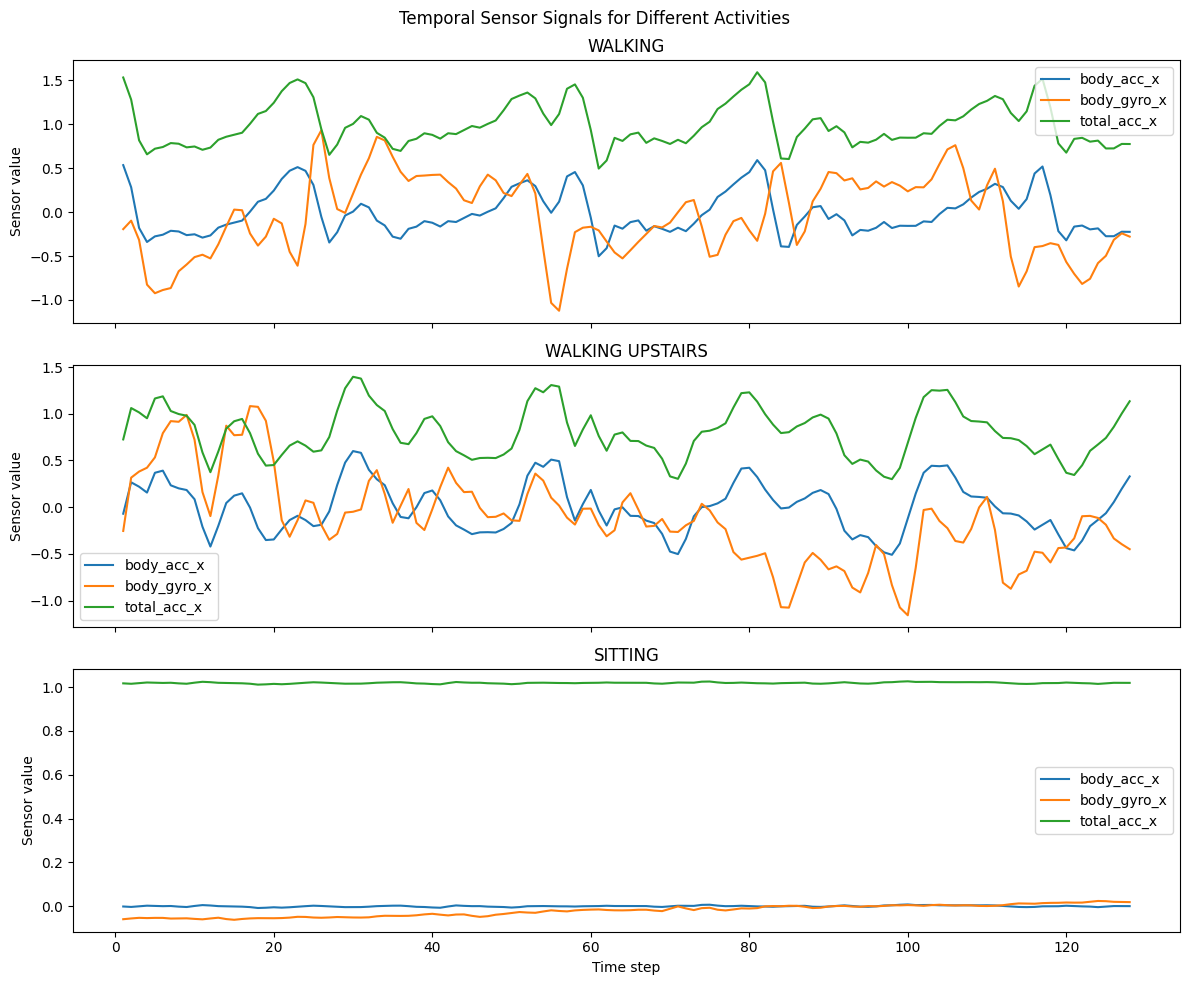

In [68]:
# ============================================================
# PLOT 1 — TEMPORAL SENSOR SIGNALS
# ============================================================

representative_classes = [0, 1, 3]

channels_to_plot = [0, 3, 6]

fig, axes = plt.subplots(
    len(representative_classes),
    1,
    figsize=(12, 10),
    sharex=True
)

for row, cls in enumerate(representative_classes):

    idx = np.where(y_train == cls)[0][0]

    for ch in channels_to_plot:

        axes[row].plot(
            range(1, 129),
            X_train[idx, :, ch],
            label=SIGNAL_NAMES[ch]
        )

    axes[row].set_title(
        CLASS_NAMES[cls]
    )

    axes[row].set_ylabel("Sensor value")
    axes[row].legend()

axes[-1].set_xlabel("Time step")

fig.suptitle(
    "Temporal Sensor Signals for Different Activities"
)

fig.tight_layout()

save_and_show(
    fig,
    "plot1_temporal_sensor_signals.eps"
)

In [69]:
# ============================================================
# MODEL BUILDERS
# ============================================================

NUM_CLASSES = 6
RECURRENT_UNITS = 32
DROPOUT = 0.2
LEARNING_RATE = 1e-3
BATCH_SIZE = 32
MAX_EPOCHS = 30


def build_model(model_type="RNN",
                units=32,
                sequence_length=128,
                second_layer=False,
                bidirectional=False):

    inputs = layers.Input(
        shape=(sequence_length, 9)
    )

    if model_type == "RNN":

        recurrent = layers.SimpleRNN(
            units,
            return_sequences=second_layer
        )

    elif model_type == "LSTM":

        recurrent = layers.LSTM(
            units,
            return_sequences=second_layer
        )

    elif model_type == "GRU":

        recurrent = layers.GRU(
            units,
            return_sequences=second_layer
        )

    else:
        raise ValueError("Unknown model type")

    if bidirectional:

        x = layers.Bidirectional(
            recurrent
        )(inputs)

    else:

        x = recurrent(inputs)

    if second_layer:

        if model_type == "RNN":
            second = layers.SimpleRNN(units)

        elif model_type == "LSTM":
            second = layers.LSTM(units)

        else:
            second = layers.GRU(units)

        x = second(x)

    x = layers.Dropout(DROPOUT)(x)

    x = layers.Dense(
        16,
        activation="relu"
    )(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    model = models.Model(
        inputs,
        outputs
    )

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    )

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [70]:
# ============================================================
# TRAINING FUNCTION
# ============================================================

def train_model(
    model_type,
    Xtr,
    ytr,
    Xv,
    yv,
    units=32,
    sequence_length=128,
    second_layer=False,
    bidirectional=False
):

    model = build_model(
        model_type=model_type,
        units=units,
        sequence_length=sequence_length,
        second_layer=second_layer,
        bidirectional=bidirectional
    )

    callbacks = [

        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
            verbose=1
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-5,
            verbose=1
        )
    ]

    start = time.time()

    history = model.fit(
        Xtr,
        ytr,
        validation_data=(Xv, yv),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=callbacks,
        verbose=1
    )

    training_time = time.time() - start

    return model, history, training_time

In [71]:
# ============================================================
# EVALUATION
# ============================================================

def evaluate_model(
    model,
    Xtest,
    ytest,
    training_time
):

    probabilities = model.predict(
        Xtest,
        batch_size=128,
        verbose=0
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    accuracy = accuracy_score(
        ytest,
        predictions
    )

    precision = precision_score(
        ytest,
        predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        ytest,
        predictions,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        ytest,
        predictions,
        average="macro",
        zero_division=0
    )

    cm = confusion_matrix(
        ytest,
        predictions
    )

    parameters = model.count_params()

    result = {
        "Accuracy (%)": accuracy * 100,
        "Macro Precision (%)": precision * 100,
        "Macro Recall (%)": recall * 100,
        "Macro F1 (%)": f1 * 100,
        "Parameters": parameters,
        "Training Time (s)": training_time
    }

    return result, predictions, probabilities, cm

In [72]:
# ============================================================
# TRAINING PLOTS
# ============================================================

def plot_training_history(history, model_name):

    epochs = range(
        1,
        len(history.history["loss"]) + 1
    )

    # LOSS

    fig = plt.figure(figsize=(9, 6))

    plt.plot(
        epochs,
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        epochs,
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{model_name} - Training and Validation Loss")
    plt.legend()
    plt.grid(alpha=0.3)

    save_and_show(
        fig,
        f"{model_name.lower()}_loss.eps"
    )

    # ACCURACY

    fig = plt.figure(figsize=(9, 6))

    plt.plot(
        epochs,
        np.array(history.history["accuracy"]) * 100,
        label="Training Accuracy"
    )

    plt.plot(
        epochs,
        np.array(history.history["val_accuracy"]) * 100,
        label="Validation Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.title(f"{model_name} - Training and Validation Accuracy")
    plt.legend()
    plt.grid(alpha=0.3)

    save_and_show(
        fig,
        f"{model_name.lower()}_accuracy.eps"
    )

TRAINING VANILLA RNN
Epoch 1/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 74ms/step - accuracy: 0.3750 - loss: 1.6171 - val_accuracy: 0.4646 - val_loss: 1.4032 - learning_rate: 0.0010
Epoch 2/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.4686 - loss: 1.3545 - val_accuracy: 0.4835 - val_loss: 1.2412 - learning_rate: 0.0010
Epoch 3/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.4084 - loss: 1.3325 - val_accuracy: 0.3750 - val_loss: 1.3425 - learning_rate: 0.0010
Epoch 4/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.4241 - loss: 1.2611 - val_accuracy: 0.5283 - val_loss: 1.1118 - learning_rate: 0.0010
Epoch 5/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.5349 - loss: 1.0681 - val_accuracy: 0.5896 - val_loss: 1.0614 - learning_rate: 0.0010
Epoch 6/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.5911 - loss: 0.9539 - val_accuracy: 0.5259 - val_loss: 1.0436 - learning_rate: 0.0010
Epoch 7/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.5815 - 


RNN RESULTS
Accuracy (%)             70.580251
Macro Precision (%)      70.134146
Macro Recall (%)         69.471826
Macro F1 (%)             69.472526
Parameters             1974.000000
Training Time (s)        57.541115
dtype: float64
Saved: /content/experiment6/graphs_eps/rnn_loss.eps


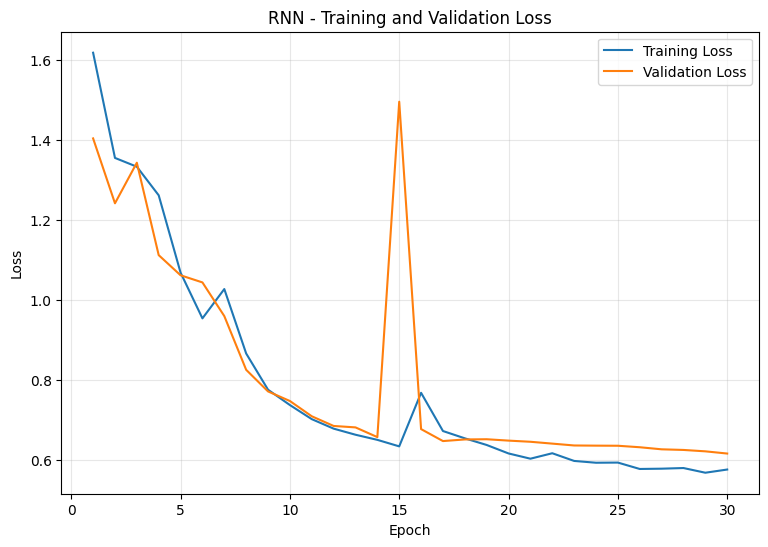

Saved: /content/experiment6/graphs_eps/rnn_accuracy.eps


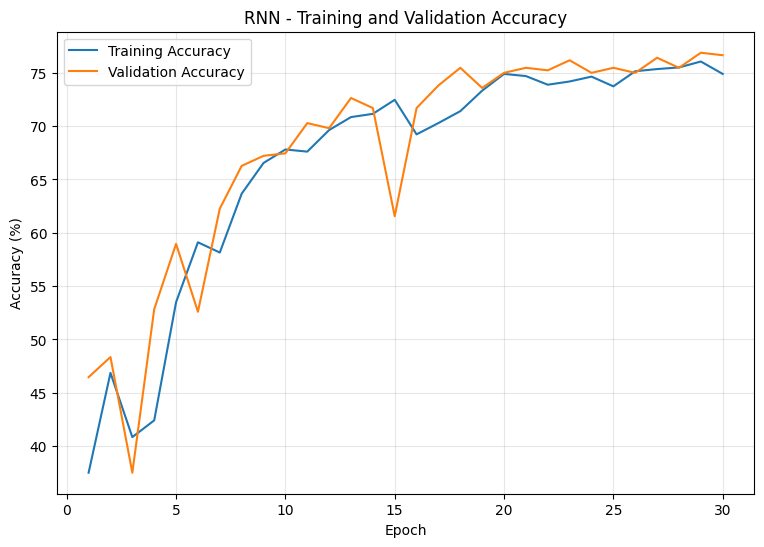

In [73]:
# ============================================================
# RNN
# ============================================================

print("=" * 60)
print("TRAINING VANILLA RNN")
print("=" * 60)

rnn_model, rnn_history, rnn_time = train_model(
    "RNN",
    X_train_norm,
    y_train,
    X_val_norm,
    y_val,
    units=32,
    sequence_length=128
)

rnn_result, rnn_pred, rnn_prob, rnn_cm = evaluate_model(
    rnn_model,
    X_test_norm,
    y_test,
    rnn_time
)

print("\nRNN RESULTS")
print(pd.Series(rnn_result))

plot_training_history(
    rnn_history,
    "RNN"
)

Saved: /content/experiment6/graphs_eps/rnn_confusion_matrix.eps


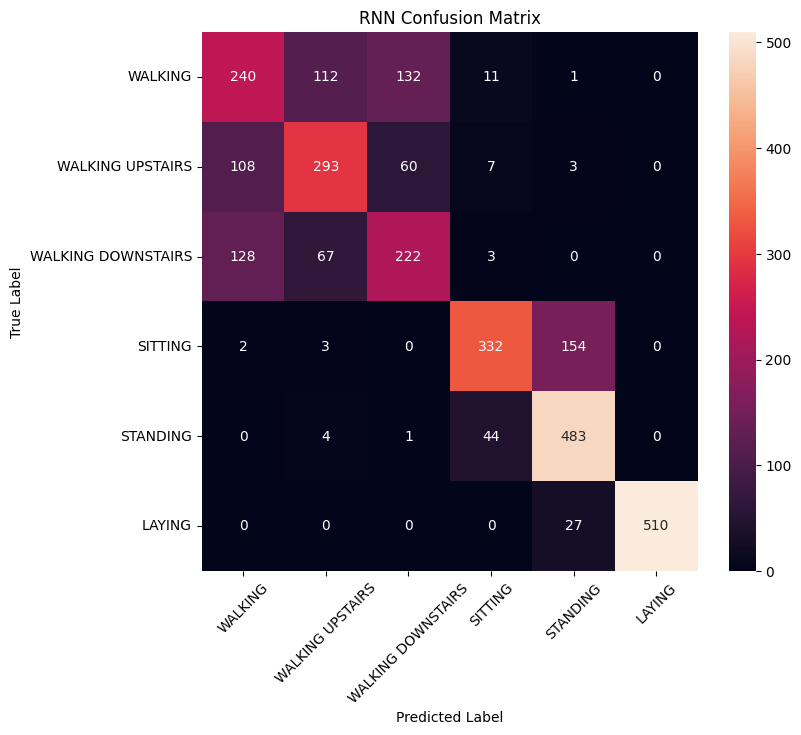

In [74]:
# ============================================================
# RNN CONFUSION MATRIX
# ============================================================

def plot_confusion(
    cm,
    model_name
):

    fig = plt.figure(figsize=(8, 7))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )

    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title(f"{model_name} Confusion Matrix")

    plt.xticks(rotation=45)
    plt.yticks(rotation=0)

    save_and_show(
        fig,
        f"{model_name.lower()}_confusion_matrix.eps"
    )


plot_confusion(
    rnn_cm,
    "RNN"
)

TRAINING LSTM
Epoch 1/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - accuracy: 0.4003 - loss: 1.5697 - val_accuracy: 0.5566 - val_loss: 1.1978 - learning_rate: 0.0010
Epoch 2/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.5810 - loss: 1.0237 - val_accuracy: 0.6486 - val_loss: 0.8678 - learning_rate: 0.0010
Epoch 3/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.6624 - loss: 0.7879 - val_accuracy: 0.7052 - val_loss: 0.7430 - learning_rate: 0.0010
Epoch 4/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.7110 - loss: 0.7270 - val_accuracy: 0.7406 - val_loss: 0.6804 - learning_rate: 0.0010
Epoch 5/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - accuracy: 0.7525 - loss: 0.6036 - val_accuracy: 0.8019 - val_loss: 0.5580 - learning_rate: 0.0010
Epoch 6/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.7930 - loss: 0.4854 - val_accuracy: 0.8090 - val_loss: 0.4585 - learning_rate: 0.0010
Epoch 7/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.7900 - loss: 0.


LSTM RESULTS
Accuracy (%)             87.512725
Macro Precision (%)      87.558690
Macro Recall (%)         87.574577
Macro F1 (%)             87.507996
Parameters             6006.000000
Training Time (s)        83.989423
dtype: float64
Saved: /content/experiment6/graphs_eps/lstm_loss.eps


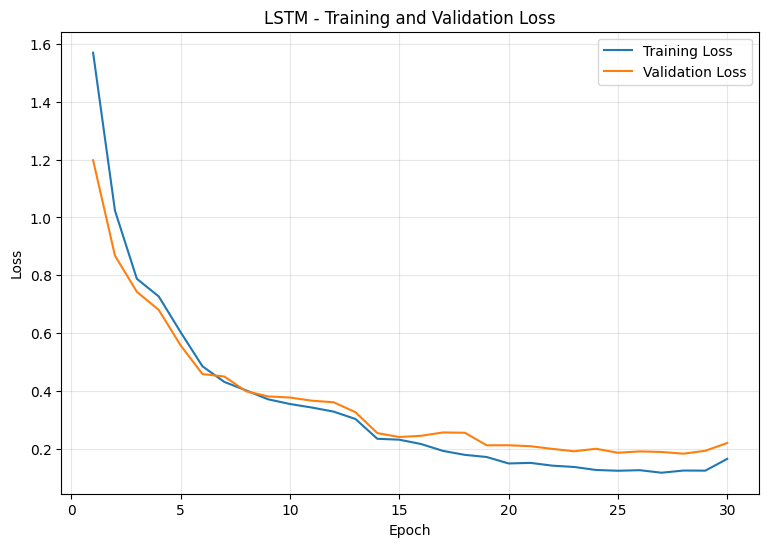

Saved: /content/experiment6/graphs_eps/lstm_accuracy.eps


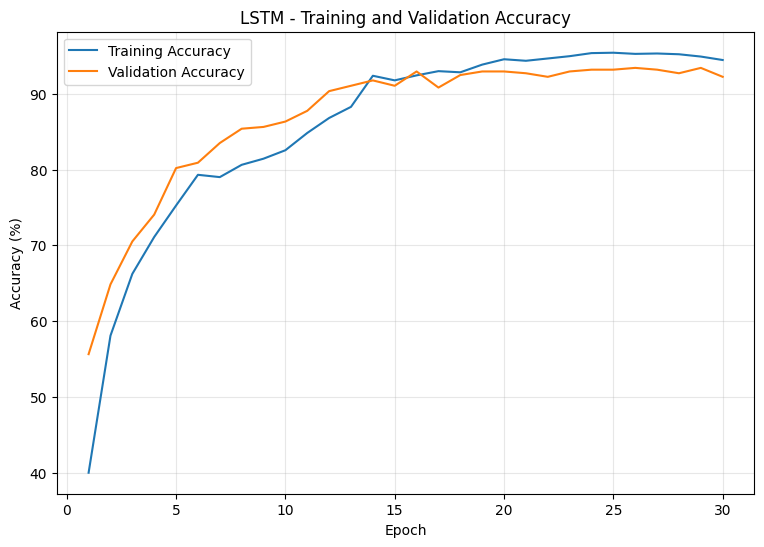

Saved: /content/experiment6/graphs_eps/lstm_confusion_matrix.eps


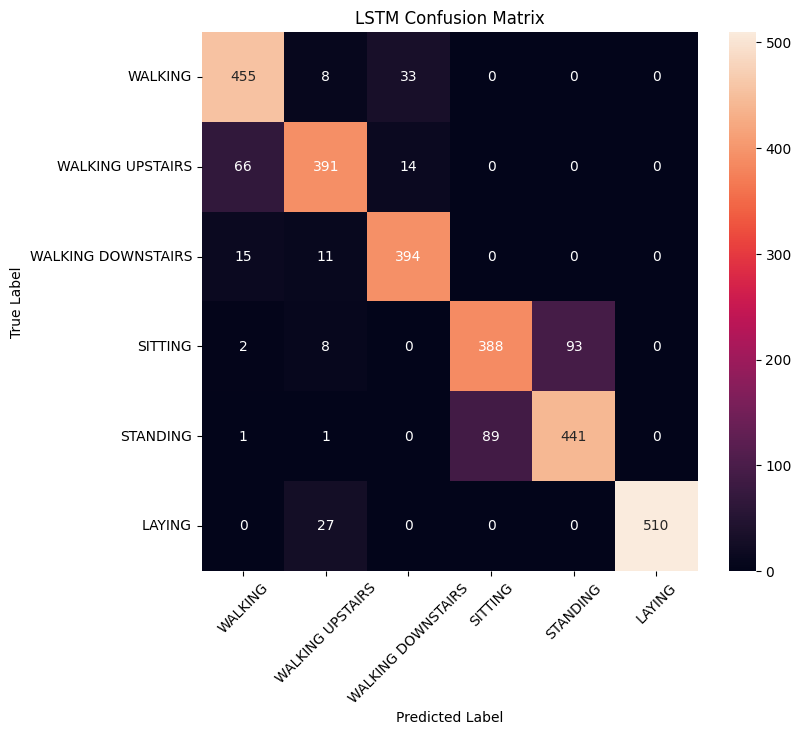

In [75]:
# ============================================================
# LSTM
# ============================================================

print("=" * 60)
print("TRAINING LSTM")
print("=" * 60)

lstm_model, lstm_history, lstm_time = train_model(
    "LSTM",
    X_train_norm,
    y_train,
    X_val_norm,
    y_val,
    units=32,
    sequence_length=128
)

lstm_result, lstm_pred, lstm_prob, lstm_cm = evaluate_model(
    lstm_model,
    X_test_norm,
    y_test,
    lstm_time
)

print("\nLSTM RESULTS")
print(pd.Series(lstm_result))

plot_training_history(
    lstm_history,
    "LSTM"
)

plot_confusion(
    lstm_cm,
    "LSTM"
)

TRAINING GRU
Epoch 1/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 6s 61ms/step - accuracy: 0.4307 - loss: 1.5426 - val_accuracy: 0.4741 - val_loss: 1.3295 - learning_rate: 0.0010
Epoch 2/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 74ms/step - accuracy: 0.5430 - loss: 1.1792 - val_accuracy: 0.5755 - val_loss: 0.9984 - learning_rate: 0.0010
Epoch 3/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.6473 - loss: 0.8439 - val_accuracy: 0.6604 - val_loss: 0.7518 - learning_rate: 0.0010
Epoch 4/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - accuracy: 0.7151 - loss: 0.6775 - val_accuracy: 0.7193 - val_loss: 0.6620 - learning_rate: 0.0010
Epoch 5/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step - accuracy: 0.7530 - loss: 0.5795 - val_accuracy: 0.7736 - val_loss: 0.5640 - learning_rate: 0.0010
Epoch 6/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.8052 - loss: 0.4756 - val_accuracy: 0.8491 - val_loss: 0.4384 - learning_rate: 0.0010
Epoch 7/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.8725 - loss: 0.3


GRU RESULTS
Accuracy (%)             88.870037
Macro Precision (%)      88.678732
Macro Recall (%)         88.977253
Macro F1 (%)             88.794690
Parameters             4758.000000
Training Time (s)       120.980859
dtype: float64
Saved: /content/experiment6/graphs_eps/gru_loss.eps


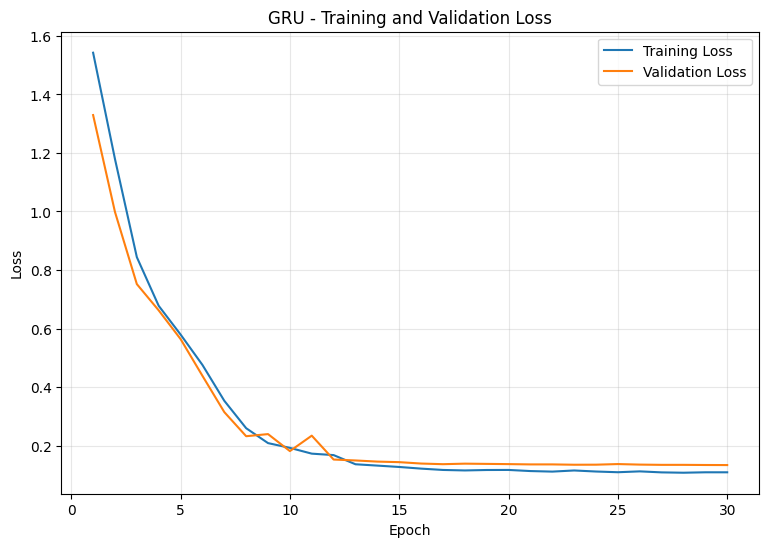

Saved: /content/experiment6/graphs_eps/gru_accuracy.eps


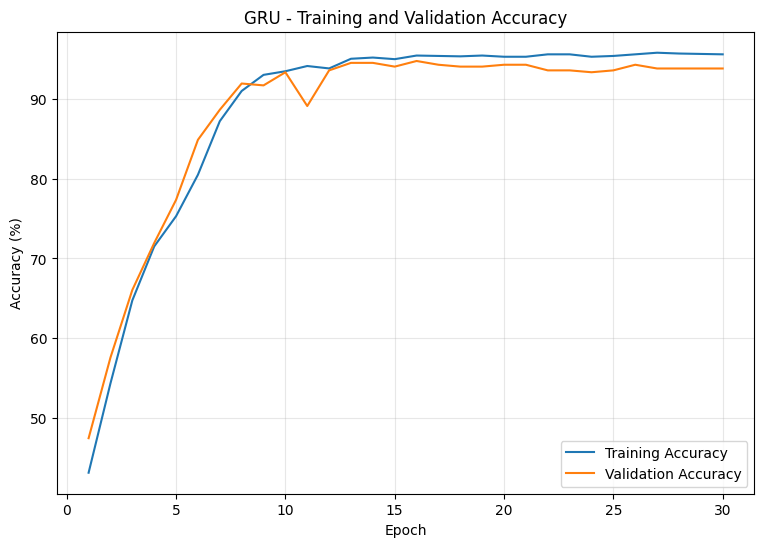

Saved: /content/experiment6/graphs_eps/gru_confusion_matrix.eps


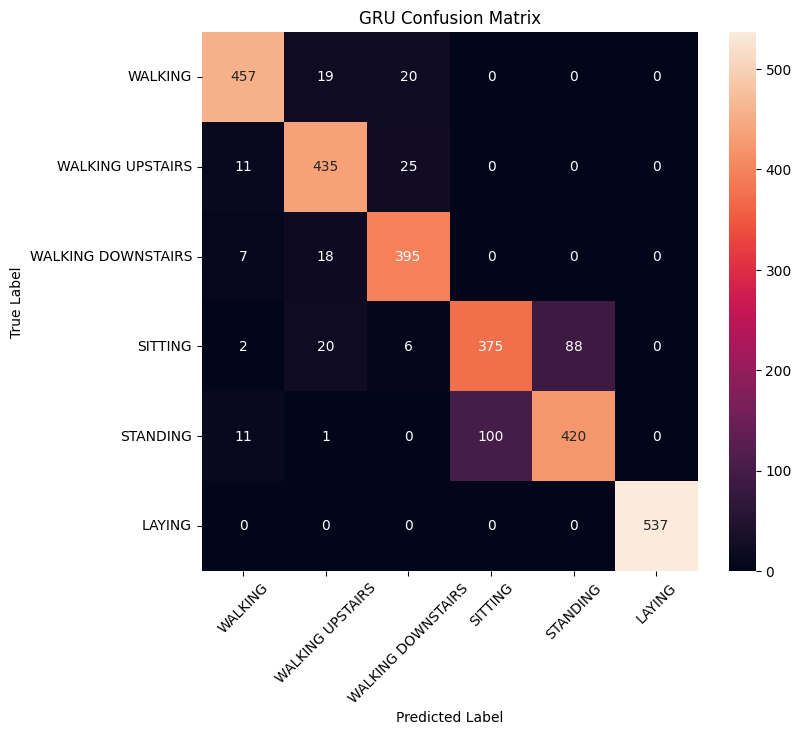

In [76]:
# ============================================================
# GRU
# ============================================================

print("=" * 60)
print("TRAINING GRU")
print("=" * 60)

gru_model, gru_history, gru_time = train_model(
    "GRU",
    X_train_norm,
    y_train,
    X_val_norm,
    y_val,
    units=32,
    sequence_length=128
)

gru_result, gru_pred, gru_prob, gru_cm = evaluate_model(
    gru_model,
    X_test_norm,
    y_test,
    gru_time
)

print("\nGRU RESULTS")
print(pd.Series(gru_result))

plot_training_history(
    gru_history,
    "GRU"
)

plot_confusion(
    gru_cm,
    "GRU"
)

In [77]:
# ============================================================
# MAIN RESULTS TABLE
# ============================================================

main_results = pd.DataFrame(
    [rnn_result, lstm_result, gru_result],
    index=["RNN", "LSTM", "GRU"]
)

main_results = main_results.round(4)

print("\n")
print("=" * 80)
print("RNN vs LSTM vs GRU RESULTS")
print("=" * 80)

display(main_results)

main_results.to_csv(
    RESULT_DIR / "main_rnn_lstm_gru_results.csv"
)



RNN vs LSTM vs GRU RESULTS


,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Parameters,Training Time (s)
RNN,70.5803,70.1341,69.4718,69.4725,1974,57.5411
LSTM,87.5127,87.5587,87.5746,87.5080,6006,83.9894
GRU,88.8700,88.6787,88.9773,88.7947,4758,120.9809


In [78]:
# ============================================================
# ARCHITECTURE COMPARISON
# ============================================================

architecture_table = pd.DataFrame({

    "Property": [
        "Hidden state",
        "Cell state",
        "Forget gate",
        "Input gate",
        "Output gate",
        "Update gate",
        "Reset gate",
        "Parameters",
        "Training time (s)",
        "Test F1-score (%)"
    ],

    "RNN": [
        "Yes",
        "No",
        "No",
        "No",
        "No",
        "No",
        "No",
        rnn_result["Parameters"],
        rnn_result["Training Time (s)"],
        rnn_result["Macro F1 (%)"]
    ],

    "LSTM": [
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "No",
        "No",
        lstm_result["Parameters"],
        lstm_result["Training Time (s)"],
        lstm_result["Macro F1 (%)"]
    ],

    "GRU": [
        "Yes",
        "No",
        "No",
        "No",
        "No",
        "Yes",
        "Yes",
        gru_result["Parameters"],
        gru_result["Training Time (s)"],
        gru_result["Macro F1 (%)"]
    ]
})

display(architecture_table)

architecture_table.to_csv(
    RESULT_DIR / "architecture_comparison.csv",
    index=False
)

,Property,RNN,LSTM,GRU
0,Hidden state,Yes,Yes,Yes
1,Cell state,No,Yes,No
2,Forget gate,No,Yes,No
3,Input gate,No,Yes,No
4,Output gate,No,Yes,No
5,Update gate,No,No,Yes
6,Reset gate,No,No,Yes
7,Parameters,1974,6006,4758
8,Training time (s),57.541115,83.989423,120.980859
9,Test F1-score (%),69.472526,87.507996,88.79469


Saved: /content/experiment6/graphs_eps/plot5_model_performance_comparison.eps


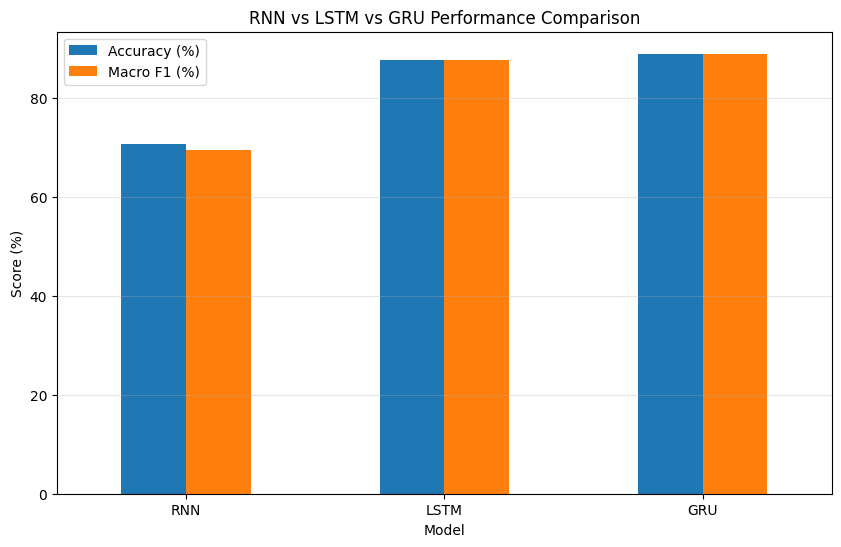

In [79]:
# ============================================================
# PLOT 5 — MODEL PERFORMANCE COMPARISON
# ============================================================

comparison_plot = main_results[
    [
        "Accuracy (%)",
        "Macro F1 (%)"
    ]
]

fig = comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
).get_figure()

plt.xlabel("Model")
plt.ylabel("Score (%)")
plt.title("RNN vs LSTM vs GRU Performance Comparison")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y", alpha=0.3)

save_and_show(
    fig,
    "plot5_model_performance_comparison.eps"
)

In [80]:
# ============================================================
# CONFUSION MATRIX ANALYSIS
# ============================================================

def analyze_confusion(cm, model_name):

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    # Recognition rate per class
    recognition_rates = []

    for i in range(len(CLASS_NAMES)):

        total_actual = cm[i].sum()

        if total_actual > 0:
            rate = cm[i, i] / total_actual
        else:
            rate = 0

        recognition_rates.append(rate)

    recognition_rates = np.array(recognition_rates)

    best_idx = np.argmax(recognition_rates)

    print(
        "Highest recognition rate:",
        CLASS_NAMES[best_idx],
        f"({recognition_rates[best_idx]*100:.2f}%)"
    )

    # Most misclassified class
    errors_per_class = cm.sum(axis=1) - np.diag(cm)

    worst_idx = np.argmax(errors_per_class)

    print(
        "Largest number of misclassifications:",
        CLASS_NAMES[worst_idx],
        f"({errors_per_class[worst_idx]})"
    )

    # Confused pairs
    pair_list = []

    for i in range(6):
        for j in range(i + 1, 6):

            confusion = cm[i, j] + cm[j, i]

            pair_list.append(
                (
                    confusion,
                    CLASS_NAMES[i],
                    CLASS_NAMES[j]
                )
            )

    pair_list.sort(reverse=True)

    print("\nMost frequently confused pairs:")

    for value, a, b in pair_list[:5]:

        print(
            f"{a} <-> {b}: {value} errors"
        )


analyze_confusion(rnn_cm, "RNN")
analyze_confusion(lstm_cm, "LSTM")
analyze_confusion(gru_cm, "GRU")


RNN
Highest recognition rate: LAYING (94.97%)
Largest number of misclassifications: WALKING (256)

Most frequently confused pairs:
WALKING <-> WALKING DOWNSTAIRS: 260 errors
WALKING <-> WALKING UPSTAIRS: 220 errors
SITTING <-> STANDING: 198 errors
WALKING UPSTAIRS <-> WALKING DOWNSTAIRS: 127 errors
STANDING <-> LAYING: 27 errors

LSTM
Highest recognition rate: LAYING (94.97%)
Largest number of misclassifications: SITTING (103)

Most frequently confused pairs:
SITTING <-> STANDING: 182 errors
WALKING <-> WALKING UPSTAIRS: 74 errors
WALKING <-> WALKING DOWNSTAIRS: 48 errors
WALKING UPSTAIRS <-> LAYING: 27 errors
WALKING UPSTAIRS <-> WALKING DOWNSTAIRS: 25 errors

GRU
Highest recognition rate: LAYING (100.00%)
Largest number of misclassifications: SITTING (116)

Most frequently confused pairs:
SITTING <-> STANDING: 188 errors
WALKING UPSTAIRS <-> WALKING DOWNSTAIRS: 43 errors
WALKING <-> WALKING UPSTAIRS: 30 errors
WALKING <-> WALKING DOWNSTAIRS: 27 errors
WALKING UPSTAIRS <-> SITTING: 2

In [81]:
# ============================================================
# SEQUENCE LENGTH EXPERIMENT
# T = 32, 64, 128
# ============================================================

sequence_lengths = [32, 64, 128]

sequence_results = []

for seq_len in sequence_lengths:

    print("\n" + "=" * 60)
    print("SEQUENCE LENGTH:", seq_len)
    print("=" * 60)

    Xtr = X_train_norm[:, :seq_len, :]
    Xv = X_val_norm[:, :seq_len, :]
    Xt = X_test_norm[:, :seq_len, :]

    for model_type in ["RNN", "LSTM", "GRU"]:

        print("\nModel:", model_type)

        model, history, training_time = train_model(
            model_type,
            Xtr,
            y_train,
            Xv,
            y_val,
            units=32,
            sequence_length=seq_len
        )

        result, _, _, _ = evaluate_model(
            model,
            Xt,
            y_test,
            training_time
        )

        sequence_results.append({
            "Sequence Length": seq_len,
            "Model": model_type,
            "Accuracy (%)": result["Accuracy (%)"],
            "Macro F1 (%)": result["Macro F1 (%)"],
            "Parameters": result["Parameters"],
            "Training Time (s)": result["Training Time (s)"]
        })

        del model
        tf.keras.backend.clear_session()


sequence_results_df = pd.DataFrame(
    sequence_results
)

display(sequence_results_df)

sequence_results_df.to_csv(
    RESULT_DIR / "sequence_length_results.csv",
    index=False
)


SEQUENCE LENGTH: 32

Model: RNN
Epoch 1/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.3790 - loss: 1.5728 - val_accuracy: 0.5118 - val_loss: 1.3159 - learning_rate: 0.0010
Epoch 2/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.5359 - loss: 1.2212 - val_accuracy: 0.5613 - val_loss: 1.1316 - learning_rate: 0.0010
Epoch 3/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.6037 - loss: 1.0641 - val_accuracy: 0.5943 - val_loss: 1.0215 - learning_rate: 0.0010
Epoch 4/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.6331 - loss: 0.9739 - val_accuracy: 0.6274 - val_loss: 0.9504 - learning_rate: 0.0010
Epoch 5/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6746 - loss: 0.8892 - val_accuracy: 0.6698 - val_loss: 0.8684 - learning_rate: 0.0010
Epoch 6/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6503 - loss: 0.8671 - val_accuracy: 0.6934 - val_loss: 0.8209 - learning_rate: 0.0010
Epoch 7/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0

,Sequence Length,Model,Accuracy (%),Macro F1 (%),Parameters,Training Time (s)
0,32,RNN,66.474381,65.424240,1974,11.882969
1,32,LSTM,85.273159,85.292527,6006,22.594607
2,32,GRU,86.223278,86.054447,4758,37.128321
3,64,RNN,72.242959,71.307030,1974,25.550988
4,64,LSTM,88.225314,88.139967,6006,42.545156
5,64,GRU,88.903970,88.877210,4758,54.826815
6,128,RNN,70.817781,69.901093,1974,23.652446
7,128,LSTM,88.802172,88.887386,6006,87.566092
8,128,GRU,89.345097,89.402945,4758,117.894551


Saved: /content/experiment6/graphs_eps/plot6_sequence_length_vs_f1.eps


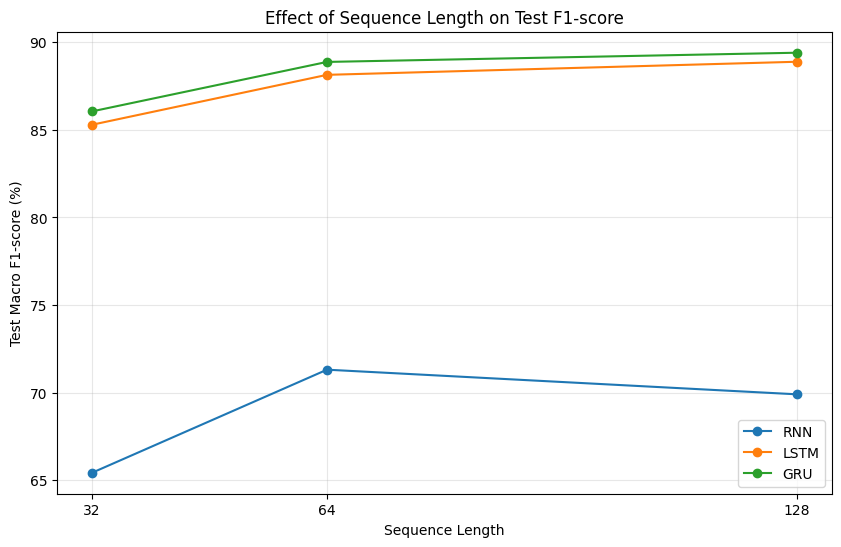

In [82]:
# ============================================================
# PLOT 6 — SEQUENCE LENGTH vs TEST F1
# ============================================================

fig = plt.figure(figsize=(10, 6))

for model_type in ["RNN", "LSTM", "GRU"]:

    subset = sequence_results_df[
        sequence_results_df["Model"] == model_type
    ]

    plt.plot(
        subset["Sequence Length"],
        subset["Macro F1 (%)"],
        marker="o",
        label=model_type
    )

plt.xlabel("Sequence Length")
plt.ylabel("Test Macro F1-score (%)")
plt.title("Effect of Sequence Length on Test F1-score")
plt.xticks(sequence_lengths)
plt.legend()
plt.grid(alpha=0.3)

save_and_show(
    fig,
    "plot6_sequence_length_vs_f1.eps"
)

In [83]:
# ============================================================
# ADDITIONAL EXERCISE 1
# 16 vs 32 vs 64 UNITS
# ============================================================

unit_results = []

for units in [16, 32, 64]:

    for model_type in ["RNN", "LSTM", "GRU"]:

        print(
            f"\nTraining {model_type} with {units} units"
        )

        model, history, training_time = train_model(
            model_type,
            X_train_norm,
            y_train,
            X_val_norm,
            y_val,
            units=units,
            sequence_length=128
        )

        result, _, _, _ = evaluate_model(
            model,
            X_test_norm,
            y_test,
            training_time
        )

        unit_results.append({
            "Model": model_type,
            "Units": units,
            "Accuracy (%)": result["Accuracy (%)"],
            "Macro F1 (%)": result["Macro F1 (%)"],
            "Parameters": result["Parameters"],
            "Training Time (s)": result["Training Time (s)"]
        })

        del model
        tf.keras.backend.clear_session()


unit_results_df = pd.DataFrame(unit_results)

display(unit_results_df)

unit_results_df.to_csv(
    RESULT_DIR / "additional_experiment_units.csv",
    index=False
)


Training RNN with 16 units
Epoch 1/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.2794 - loss: 1.6670 - val_accuracy: 0.5236 - val_loss: 1.4531 - learning_rate: 0.0010
Epoch 2/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.5051 - loss: 1.3488 - val_accuracy: 0.5708 - val_loss: 1.1689 - learning_rate: 0.0010
Epoch 3/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.5683 - loss: 1.1197 - val_accuracy: 0.6085 - val_loss: 1.0098 - learning_rate: 0.0010
Epoch 4/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.5926 - loss: 0.9838 - val_accuracy: 0.6038 - val_loss: 0.9249 - learning_rate: 0.0010
Epoch 5/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.6164 - loss: 0.9064 - val_accuracy: 0.5896 - val_loss: 0.9961 - learning_rate: 0.0010
Epoch 6/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.6371 - loss: 0.8750 - val_accuracy: 0.6297 - val_loss: 0.8401 - learning_rate: 0.0010
Epoch 7/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.6

,Model,Units,Accuracy (%),Macro F1 (%),Parameters,Training Time (s)
0,RNN,16,69.019342,68.229753,790,43.803937
1,LSTM,16,86.426875,86.421964,2038,64.500206
2,GRU,16,87.139464,87.088908,1670,92.349331
3,RNN,32,74.889718,74.355716,1974,43.428839
4,LSTM,32,88.191381,88.185008,6006,48.448380
5,GRU,32,89.514761,89.482990,4758,81.757744
6,RNN,64,68.204954,67.332540,5878,25.339242
7,LSTM,64,88.836105,88.962380,20086,75.634489
8,GRU,64,89.277231,89.298935,15542,102.838016


In [84]:
# ============================================================
# ADDITIONAL EXERCISE 2
# GRU vs LSTM — SAME NUMBER OF UNITS
# ============================================================

gru_lstm_comparison = main_results.loc[
    ["LSTM", "GRU"],
    [
        "Accuracy (%)",
        "Macro Precision (%)",
        "Macro Recall (%)",
        "Macro F1 (%)",
        "Parameters",
        "Training Time (s)"
    ]
]

display(gru_lstm_comparison)

gru_lstm_comparison.to_csv(
    RESULT_DIR / "additional_gru_vs_lstm.csv"
)

,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Parameters,Training Time (s)
LSTM,87.5127,87.5587,87.5746,87.5080,6006,83.9894
GRU,88.8700,88.6787,88.9773,88.7947,4758,120.9809


In [85]:
# ============================================================
# ADDITIONAL EXERCISE 3
# SECOND RECURRENT LAYER
# ============================================================

two_layer_results = []

for model_type in ["RNN", "LSTM", "GRU"]:

    print(
        "\nTwo-layer model:",
        model_type
    )

    model, history, training_time = train_model(
        model_type,
        X_train_norm,
        y_train,
        X_val_norm,
        y_val,
        units=32,
        sequence_length=128,
        second_layer=True
    )

    result, _, _, _ = evaluate_model(
        model,
        X_test_norm,
        y_test,
        training_time
    )

    two_layer_results.append({
        "Model": model_type,
        "Layers": 2,
        "Accuracy (%)": result["Accuracy (%)"],
        "Macro F1 (%)": result["Macro F1 (%)"],
        "Parameters": result["Parameters"],
        "Training Time (s)": result["Training Time (s)"]
    })

    del model
    tf.keras.backend.clear_session()


two_layer_df = pd.DataFrame(
    two_layer_results
)

display(two_layer_df)

two_layer_df.to_csv(
    RESULT_DIR / "additional_two_layer_results.csv",
    index=False
)


Two-layer model: RNN
Epoch 1/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - accuracy: 0.4109 - loss: 1.4558 - val_accuracy: 0.5967 - val_loss: 1.2022 - learning_rate: 0.0010
Epoch 2/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.6032 - loss: 1.0829 - val_accuracy: 0.6321 - val_loss: 1.0216 - learning_rate: 0.0010
Epoch 3/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.6366 - loss: 0.9245 - val_accuracy: 0.7217 - val_loss: 0.7855 - learning_rate: 0.0010
Epoch 4/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.7222 - loss: 0.7793 - val_accuracy: 0.7099 - val_loss: 0.8144 - learning_rate: 0.0010
Epoch 5/30
61/62 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.6938 - loss: 0.8623
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.6711 - loss: 0.9155 - val_accuracy: 0.6415 - val_loss: 0.9188 - learning_rate: 0.0010
Epoch 6/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.7039 - l

,Model,Layers,Accuracy (%),Macro F1 (%),Parameters,Training Time (s)
0,RNN,2,80.386834,79.890795,4054,72.045961
1,LSTM,2,89.888022,89.956093,14326,154.326881
2,GRU,2,89.888022,89.885882,11094,160.195785


Training Bidirectional LSTM...
Epoch 1/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 7s 66ms/step - accuracy: 0.5182 - loss: 1.3549 - val_accuracy: 0.6533 - val_loss: 0.9297 - learning_rate: 0.0010
Epoch 2/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 87ms/step - accuracy: 0.6786 - loss: 0.8063 - val_accuracy: 0.7075 - val_loss: 0.7049 - learning_rate: 0.0010
Epoch 3/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - accuracy: 0.7424 - loss: 0.6188 - val_accuracy: 0.7642 - val_loss: 0.5761 - learning_rate: 0.0010
Epoch 4/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.7910 - loss: 0.5009 - val_accuracy: 0.8019 - val_loss: 0.4774 - learning_rate: 0.0010
Epoch 5/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 6s 79ms/step - accuracy: 0.8386 - loss: 0.3954 - val_accuracy: 0.8915 - val_loss: 0.3408 - learning_rate: 0.0010
Epoch 6/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - accuracy: 0.8993 - loss: 0.2882 - val_accuracy: 0.8892 - val_loss: 0.3178 - learning_rate: 0.0010
Epoch 7/30
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 58ms/step - accuracy: 

,Model,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Parameters,Training Time (s)
0,LSTM,87.512725,87.55869,87.574577,87.507996,6006,83.989423
1,Bidirectional LSTM,90.600611,90.58390,90.689137,90.600813,11894,158.741052


Saved: /content/experiment6/graphs_eps/bidirectional_lstm_confusion_matrix.eps


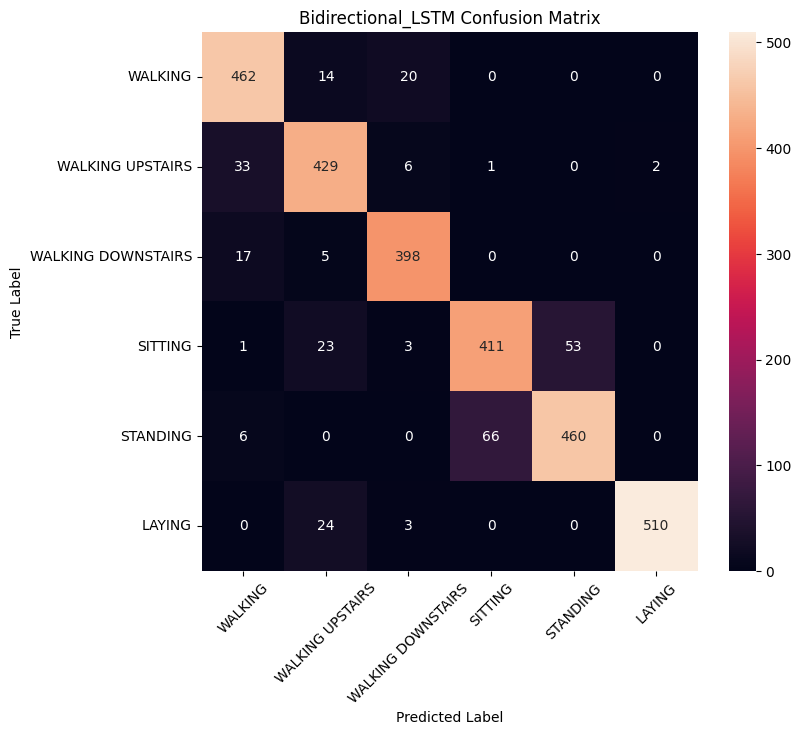

In [86]:
# ============================================================
# ADDITIONAL EXERCISE 4
# BIDIRECTIONAL LSTM vs UNIDIRECTIONAL LSTM
# ============================================================

print("Training Bidirectional LSTM...")

bi_lstm_model, bi_lstm_history, bi_lstm_time = train_model(
    "LSTM",
    X_train_norm,
    y_train,
    X_val_norm,
    y_val,
    units=32,
    sequence_length=128,
    bidirectional=True
)

bi_lstm_result, bi_lstm_pred, bi_lstm_prob, bi_lstm_cm = evaluate_model(
    bi_lstm_model,
    X_test_norm,
    y_test,
    bi_lstm_time
)

bidirectional_comparison = pd.DataFrame([
    {
        "Model": "LSTM",
        **lstm_result
    },
    {
        "Model": "Bidirectional LSTM",
        **bi_lstm_result
    }
])

display(
    bidirectional_comparison
)

bidirectional_comparison.to_csv(
    RESULT_DIR / "additional_bidirectional_lstm.csv",
    index=False
)

plot_confusion(
    bi_lstm_cm,
    "Bidirectional_LSTM"
)

In [87]:
# ============================================================
# ADDITIONAL EXERCISE 5
# SEQUENCE LENGTH vs COMPUTATIONAL COST
# ============================================================

cost_table = sequence_results_df[
    [
        "Sequence Length",
        "Model",
        "Parameters",
        "Training Time (s)",
        "Macro F1 (%)"
    ]
].sort_values(
    ["Model", "Sequence Length"]
)

display(cost_table)

cost_table.to_csv(
    RESULT_DIR / "additional_sequence_computational_cost.csv",
    index=False
)

,Sequence Length,Model,Parameters,Training Time (s),Macro F1 (%)
2,32,GRU,4758,37.128321,86.054447
5,64,GRU,4758,54.826815,88.877210
8,128,GRU,4758,117.894551,89.402945
1,32,LSTM,6006,22.594607,85.292527
4,64,LSTM,6006,42.545156,88.139967
7,128,LSTM,6006,87.566092,88.887386
0,32,RNN,1974,11.882969,65.424240
3,64,RNN,1974,25.550988,71.307030
6,128,RNN,1974,23.652446,69.901093


In [88]:
# ============================================================
# LOAD UCI HAR RAW INERTIAL SIGNALS
# ============================================================

import numpy as np
from pathlib import Path

SIGNAL_NAMES = [
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",
    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",
    "total_acc_x",
    "total_acc_y",
    "total_acc_z"
]

def load_partition(partition):
    signal_dir = UCI_ROOT / partition / "Inertial Signals"

    signals = []

    for name in SIGNAL_NAMES:
        file_path = signal_dir / f"{name}_{partition}.txt"

        data = np.loadtxt(file_path)

        signals.append(data)

    # Each signal: (N, 128)
    # Stack → (N, 128, 9)
    X = np.stack(signals, axis=-1)

    y = np.loadtxt(
        UCI_ROOT / partition / f"y_{partition}.txt",
        dtype=int
    ) - 1

    return X.astype(np.float32), y.astype(np.int64)


X_train_full, y_train_full = load_partition("train")
X_test, y_test = load_partition("test")

print("Full training data :", X_train_full.shape)
print("Full testing data  :", X_test.shape)
print("Training labels    :", y_train_full.shape)
print("Testing labels     :", y_test.shape)

print("\nNumber of classes:", len(np.unique(y_train_full)))
print("Sequence length:", X_train_full.shape[1])
print("Features/time step:", X_train_full.shape[2])

Full training data : (7352, 128, 9)
Full testing data  : (2947, 128, 9)
Training labels    : (7352,)
Testing labels     : (2947,)

Number of classes: 6
Sequence length: 128
Features/time step: 9


In [89]:
# ============================================================
# PREPROCESSING: 70 / 15 / 15 SPLIT + NORMALIZATION
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

# ------------------------------------------------------------
# 1. Combine the original train and test data
# ------------------------------------------------------------
X_all = np.concatenate([X_train_full, X_test], axis=0)
y_all = np.concatenate([y_train_full, y_test], axis=0)

print("Combined data:", X_all.shape)
print("Combined labels:", y_all.shape)

# ------------------------------------------------------------
# 2. First split: 70% train, 30% temporary
# ------------------------------------------------------------
X_train, X_temp, y_train, y_temp = train_test_split(
    X_all,
    y_all,
    test_size=0.30,
    random_state=42,
    stratify=y_all
)

# ------------------------------------------------------------
# 3. Split temporary data equally:
#    15% validation + 15% test
# ------------------------------------------------------------
X_val, X_test_final, y_val, y_test_final = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("\nBefore normalization:")
print("Train      :", X_train.shape)
print("Validation :", X_val.shape)
print("Test       :", X_test_final.shape)

# ------------------------------------------------------------
# 4. Normalize using TRAINING statistics only
# ------------------------------------------------------------

n_train, seq_len, n_features = X_train.shape

scaler = StandardScaler()

# Fit only on training data
X_train_2d = X_train.reshape(-1, n_features)
scaler.fit(X_train_2d)

# Transform all three sets
X_train = scaler.transform(
    X_train.reshape(-1, n_features)
).reshape(X_train.shape)

X_val = scaler.transform(
    X_val.reshape(-1, n_features)
).reshape(X_val.shape)

X_test_final = scaler.transform(
    X_test_final.reshape(-1, n_features)
).reshape(X_test_final.shape)

print("\nAfter normalization:")
print("Train      :", X_train.shape)
print("Validation :", X_val.shape)
print("Test       :", X_test_final.shape)

print("\nMean of normalized training data:",
      X_train.mean())

print("Std of normalized training data:",
      X_train.std())

Combined data: (10299, 128, 9)
Combined labels: (10299,)

Before normalization:
Train      : (7209, 128, 9)
Validation : (1545, 128, 9)
Test       : (1545, 128, 9)

After normalization:
Train      : (7209, 128, 9)
Validation : (1545, 128, 9)
Test       : (1545, 128, 9)

Mean of normalized training data: 4.8359126e-09
Std of normalized training data: 1.0000001


CLASS DISTRIBUTION


,Activity,Train,Validation,Test,Total
0,WALKING,1205,258,259,1722
1,WALKING_UPSTAIRS,1081,232,231,1544
2,WALKING_DOWNSTAIRS,984,211,211,1406
3,SITTING,1244,266,267,1777
4,STANDING,1334,286,286,1906
5,LAYING,1361,292,291,1944


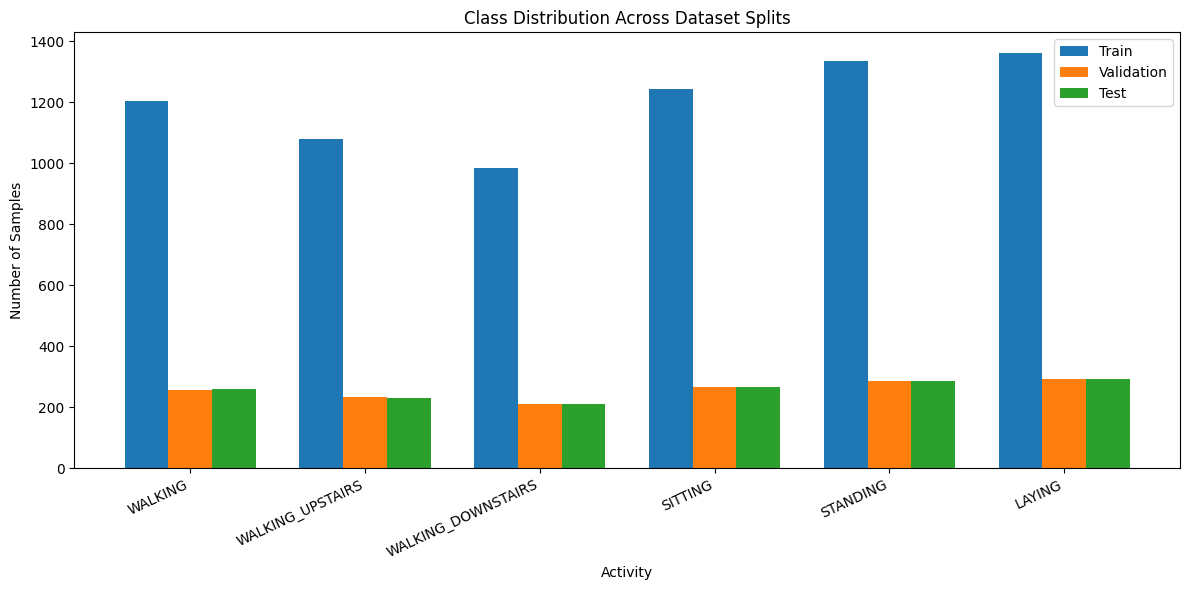

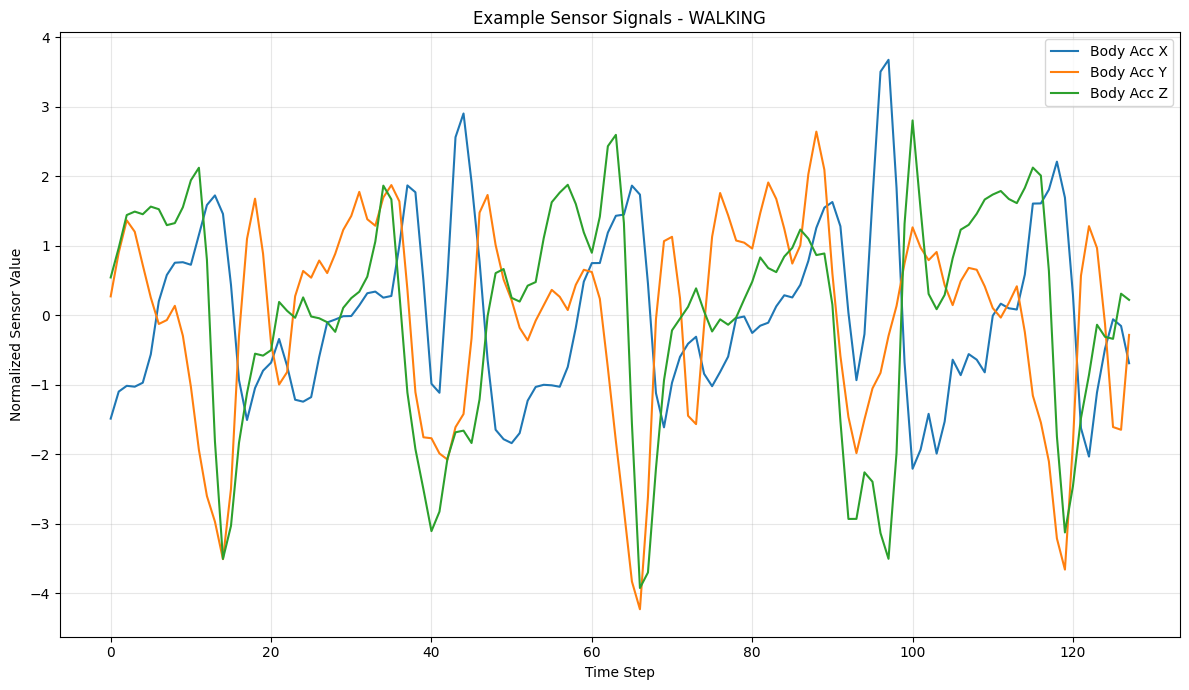


Graphs saved in:
/content/experiment6_graphs

Files currently saved:
✓ 01_class_distribution.eps
✓ 02_sensor_signals.eps
✓ 03_RNN_loss_curve.eps
✓ 04_RNN_accuracy_curve.eps
✓ 05_RNN_confusion_matrix.eps
✓ 06_LSTM_loss_curve.eps
✓ 07_LSTM_accuracy_curve.eps
✓ 08_LSTM_confusion_matrix.eps


In [90]:
# ============================================================
# CLASS DISTRIBUTION + SENSOR SIGNAL VISUALIZATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# Output directory for ALL experiment graphs
# ------------------------------------------------------------

GRAPH_DIR = Path("/content/experiment6_graphs")
GRAPH_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Activity names
# UCI HAR labels:
# 1 = WALKING
# 2 = WALKING_UPSTAIRS
# 3 = WALKING_DOWNSTAIRS
# 4 = SITTING
# 5 = STANDING
# 6 = LAYING
# ------------------------------------------------------------

activity_names = [
    "WALKING",
    "WALKING_UPSTAIRS",
    "WALKING_DOWNSTAIRS",
    "SITTING",
    "STANDING",
    "LAYING"
]

# ------------------------------------------------------------
# CLASS DISTRIBUTION TABLE
# ------------------------------------------------------------

train_counts = np.bincount(
    y_train,
    minlength=6
)

val_counts = np.bincount(
    y_val,
    minlength=6
)

test_counts = np.bincount(
    y_test_final,
    minlength=6
)

class_distribution = pd.DataFrame({
    "Activity": activity_names,
    "Train": train_counts,
    "Validation": val_counts,
    "Test": test_counts,
    "Total": train_counts + val_counts + test_counts
})

print("============================================================")
print("CLASS DISTRIBUTION")
print("============================================================")
display(class_distribution)

# Save table as CSV
class_distribution.to_csv(
    "/content/class_distribution.csv",
    index=False
)

# ------------------------------------------------------------
# PLOT: CLASS DISTRIBUTION
# ------------------------------------------------------------

x = np.arange(len(activity_names))
width = 0.25

plt.figure(figsize=(12, 6))

plt.bar(
    x - width,
    train_counts,
    width,
    label="Train"
)

plt.bar(
    x,
    val_counts,
    width,
    label="Validation"
)

plt.bar(
    x + width,
    test_counts,
    width,
    label="Test"
)

plt.xticks(
    x,
    activity_names,
    rotation=25,
    ha="right"
)

plt.xlabel("Activity")
plt.ylabel("Number of Samples")
plt.title("Class Distribution Across Dataset Splits")
plt.legend()
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "01_class_distribution.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# SENSOR SIGNAL VISUALIZATION
# ------------------------------------------------------------

# Select one training sample
sample_index = 0
sample = X_train[sample_index]

time_steps = np.arange(128)

sensor_names = [
    "Body Acc X",
    "Body Acc Y",
    "Body Acc Z",
    "Body Gyro X",
    "Body Gyro Y",
    "Body Gyro Z",
    "Total Acc X",
    "Total Acc Y",
    "Total Acc Z"
]

# Plot first 3 signals as required for readability
plt.figure(figsize=(12, 7))

plt.plot(
    time_steps,
    sample[:, 0],
    label="Body Acc X"
)

plt.plot(
    time_steps,
    sample[:, 1],
    label="Body Acc Y"
)

plt.plot(
    time_steps,
    sample[:, 2],
    label="Body Acc Z"
)

plt.xlabel("Time Step")
plt.ylabel("Normalized Sensor Value")
plt.title(
    f"Example Sensor Signals - "
    f"{activity_names[y_train[sample_index]]}"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "02_sensor_signals.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Print graph directory
# ------------------------------------------------------------

print("\nGraphs saved in:")
print(GRAPH_DIR)

print("\nFiles currently saved:")

for f in sorted(GRAPH_DIR.glob("*.eps")):
    print("✓", f.name)

In [91]:
# ============================================================
# CREATE BALANCED TRAINING SUBSET
# ============================================================

import numpy as np

MAX_TRAIN_SAMPLES = 3000
RANDOM_STATE = 42

rng = np.random.default_rng(RANDOM_STATE)

samples_per_class = MAX_TRAIN_SAMPLES // 6

selected_indices = []

for cls in range(6):

    class_indices = np.where(y_train == cls)[0]

    # Randomly select 500 samples from this class
    selected = rng.choice(
        class_indices,
        size=samples_per_class,
        replace=False
    )

    selected_indices.extend(selected)

# Convert to array and shuffle
selected_indices = np.array(selected_indices)
selected_indices = rng.permutation(selected_indices)

# Create experimental training set
X_train_exp = X_train[selected_indices]
y_train_exp = y_train[selected_indices]

print("============================================================")
print("EXPERIMENTAL TRAINING SUBSET")
print("============================================================")

print("X_train_exp shape:", X_train_exp.shape)
print("y_train_exp shape:", y_train_exp.shape)

print("\nClass distribution:")

for cls in range(6):
    print(
        f"{activity_names[cls]:20s}: "
        f"{np.sum(y_train_exp == cls)}"
    )

print("\nValidation shape:", X_val.shape)
print("Test shape:", X_test_final.shape)

EXPERIMENTAL TRAINING SUBSET
X_train_exp shape: (3000, 128, 9)
y_train_exp shape: (3000,)

Class distribution:
WALKING             : 500
WALKING_UPSTAIRS    : 500
WALKING_DOWNSTAIRS  : 500
SITTING             : 500
STANDING            : 500
LAYING              : 500

Validation shape: (1545, 128, 9)
Test shape: (1545, 128, 9)


In [92]:
# ============================================================
# TRAIN RNN
# ============================================================

import time

EPOCHS = 30
BATCH_SIZE = 32

print("Training RNN...")

rnn_start = time.time()

rnn_history = rnn_model.fit(
    X_train_exp,
    y_train_exp,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=EPOCHS,
    batch_size=BATCH_SIZE,

    verbose=1
)

rnn_time = time.time() - rnn_start

print("\n========================================")
print("RNN TRAINING COMPLETE")
print("========================================")
print(f"Training time: {rnn_time:.2f} seconds")
print(f"Training time: {rnn_time/60:.2f} minutes")

Training RNN...
Epoch 1/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.7183 - loss: 0.6421 - val_accuracy: 0.7689 - val_loss: 0.5528
Epoch 2/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.7153 - loss: 0.6391 - val_accuracy: 0.7715 - val_loss: 0.5471
Epoch 3/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.7120 - loss: 0.6376 - val_accuracy: 0.7709 - val_loss: 0.5422
Epoch 4/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.7117 - loss: 0.6200 - val_accuracy: 0.7761 - val_loss: 0.5428
Epoch 5/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.7200 - loss: 0.6192 - val_accuracy: 0.7819 - val_loss: 0.5267
Epoch 6/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.7383 - loss: 0.6131 - val_accuracy: 0.7858 - val_loss: 0.5344
Epoch 7/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.7313 - loss: 0.6066 - val_accuracy: 0.7780 - val_loss: 0.5276
Epoch 8/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - accuracy: 0.7327 - loss: 0.5986 - val_accu

Generating RNN predictions...



RNN TEST RESULTS
Accuracy          : 0.7987
Macro Precision   : 0.7889
Macro Recall      : 0.7897
Macro F1          : 0.7891
Trainable Params  : 1,974
Training Time     : 69.77 seconds
Training Time     : 1.16 minutes

RNN CLASSIFICATION REPORT
                    precision    recall  f1-score   support

           WALKING     0.6508    0.6332    0.6419       259
  WALKING_UPSTAIRS     0.7629    0.7662    0.7646       231
WALKING_DOWNSTAIRS     0.6400    0.6825    0.6606       211
           SITTING     0.8333    0.8240    0.8286       267
          STANDING     0.8566    0.8357    0.8460       286
            LAYING     0.9898    0.9966    0.9932       291

          accuracy                         0.7987      1545
         macro avg     0.7889    0.7897    0.7891      1545
      weighted avg     0.7996    0.7987    0.7990      1545



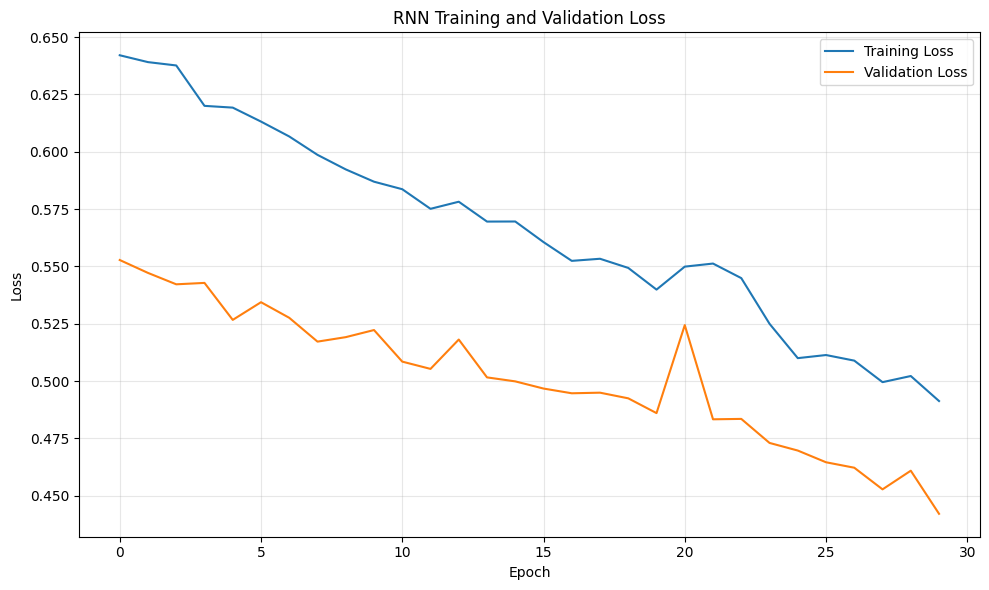

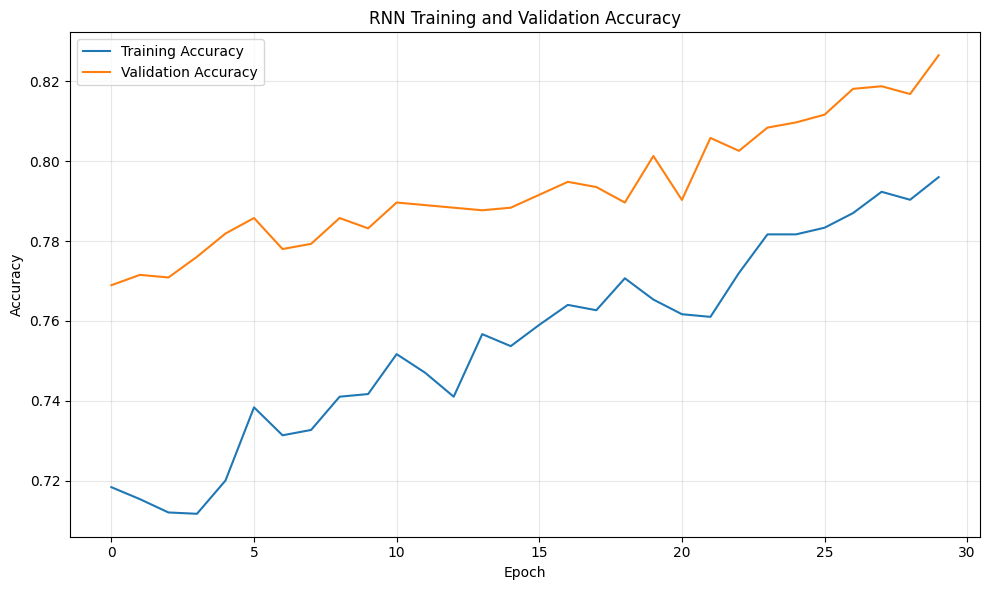

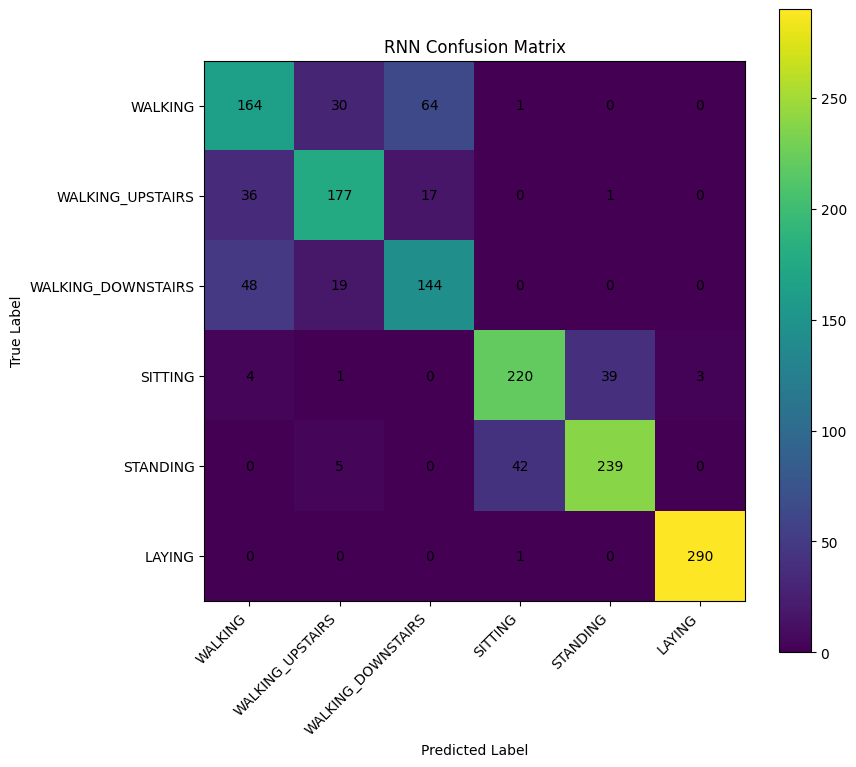


RNN RESULT RECORD


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Parameters,Training Time (s),Training Time (min)
0,RNN,0.798706,0.788908,0.789683,0.789134,1974,69.770638,1.162844



SAVED GRAPHS
✓ 01_class_distribution.eps
✓ 02_sensor_signals.eps
✓ 03_RNN_loss_curve.eps
✓ 04_RNN_accuracy_curve.eps
✓ 05_RNN_confusion_matrix.eps
✓ 06_LSTM_loss_curve.eps
✓ 07_LSTM_accuracy_curve.eps
✓ 08_LSTM_confusion_matrix.eps


In [93]:
# ============================================================
# RNN — RESULTS, METRICS, CURVES AND CONFUSION MATRIX
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. Predictions
# ------------------------------------------------------------

print("Generating RNN predictions...")

rnn_prob = rnn_model.predict(
    X_test_final,
    batch_size=64,
    verbose=0
)

rnn_pred = np.argmax(
    rnn_prob,
    axis=1
)

# ------------------------------------------------------------
# 2. Metrics
# ------------------------------------------------------------

rnn_accuracy = accuracy_score(
    y_test_final,
    rnn_pred
)

rnn_precision = precision_score(
    y_test_final,
    rnn_pred,
    average="macro",
    zero_division=0
)

rnn_recall = recall_score(
    y_test_final,
    rnn_pred,
    average="macro",
    zero_division=0
)

rnn_f1 = f1_score(
    y_test_final,
    rnn_pred,
    average="macro",
    zero_division=0
)

rnn_params = rnn_model.count_params()

# ------------------------------------------------------------
# 3. Print results
# ------------------------------------------------------------

print("\n============================================================")
print("RNN TEST RESULTS")
print("============================================================")

print(f"Accuracy          : {rnn_accuracy:.4f}")
print(f"Macro Precision   : {rnn_precision:.4f}")
print(f"Macro Recall      : {rnn_recall:.4f}")
print(f"Macro F1          : {rnn_f1:.4f}")
print(f"Trainable Params  : {rnn_params:,}")
print(f"Training Time     : {rnn_time:.2f} seconds")
print(f"Training Time     : {rnn_time/60:.2f} minutes")

# ------------------------------------------------------------
# 4. Classification report
# ------------------------------------------------------------

print("\n============================================================")
print("RNN CLASSIFICATION REPORT")
print("============================================================")

print(
    classification_report(
        y_test_final,
        rnn_pred,
        target_names=activity_names,
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------------------------
# 5. RNN LOSS CURVE
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    rnn_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    rnn_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("RNN Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "03_RNN_loss_curve.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 6. RNN ACCURACY CURVE
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    rnn_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    rnn_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("RNN Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "04_RNN_accuracy_curve.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 7. CONFUSION MATRIX
# ------------------------------------------------------------

cm_rnn = confusion_matrix(
    y_test_final,
    rnn_pred
)

plt.figure(figsize=(9, 8))

plt.imshow(
    cm_rnn,
    interpolation="nearest"
)

plt.title("RNN Confusion Matrix")
plt.colorbar()

tick_marks = np.arange(len(activity_names))

plt.xticks(
    tick_marks,
    activity_names,
    rotation=45,
    ha="right"
)

plt.yticks(
    tick_marks,
    activity_names
)

# Add values inside cells
threshold = cm_rnn.max() / 2

for i in range(cm_rnn.shape[0]):
    for j in range(cm_rnn.shape[1]):

        plt.text(
            j,
            i,
            str(cm_rnn[i, j]),
            horizontalalignment="center",
            verticalalignment="center"
        )

plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "05_RNN_confusion_matrix.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 8. Store RNN results in dictionary
# ------------------------------------------------------------

rnn_results = {
    "Model": "RNN",
    "Accuracy": rnn_accuracy,
    "Macro Precision": rnn_precision,
    "Macro Recall": rnn_recall,
    "Macro F1": rnn_f1,
    "Parameters": rnn_params,
    "Training Time (s)": rnn_time,
    "Training Time (min)": rnn_time / 60
}

print("\n============================================================")
print("RNN RESULT RECORD")
print("============================================================")

display(
    pd.DataFrame([rnn_results])
)

# ------------------------------------------------------------
# 9. List saved graphs
# ------------------------------------------------------------

print("\n============================================================")
print("SAVED GRAPHS")
print("============================================================")

for f in sorted(GRAPH_DIR.glob("*.eps")):
    print("✓", f.name)

In [94]:
# ============================================================
# SAVE RNN RESULTS
# ============================================================

rnn_results_df = pd.DataFrame([rnn_results])

rnn_results_df.to_csv(
    "/content/RNN_results.csv",
    index=False
)

print("RNN results saved to:")
print("/content/RNN_results.csv")

RNN results saved to:
/content/RNN_results.csv


In [95]:
# ============================================================
# LSTM MODEL
# ============================================================

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam

tf.random.set_seed(42)

lstm_model = Sequential([
    LSTM(
        32,
        input_shape=(128, 9)
    ),

    Dropout(0.2),

    Dense(
        16,
        activation="relu"
    ),

    Dense(
        6,
        activation="softmax"
    )
])

lstm_model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("LSTM MODEL")
lstm_model.summary()

print("\nTotal parameters:", lstm_model.count_params())

LSTM MODEL


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 32)             │         5,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,006 (23.46 KB)

 Trainable params: 6,006 (23.46 KB)

 Non-trainable params: 0 (0.00 B)


Total parameters: 6006


In [96]:
# ============================================================
# TRAIN LSTM
# ============================================================

import time

EPOCHS = 30
BATCH_SIZE = 32

print("Training LSTM...")

lstm_start = time.time()

lstm_history = lstm_model.fit(
    X_train_exp,
    y_train_exp,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=EPOCHS,
    batch_size=BATCH_SIZE,

    verbose=1
)

lstm_time = time.time() - lstm_start

print("\n========================================")
print("LSTM TRAINING COMPLETE")
print("========================================")

print(f"Training time: {lstm_time:.2f} seconds")
print(f"Training time: {lstm_time/60:.2f} minutes")

Training LSTM...
Epoch 1/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 6s 43ms/step - accuracy: 0.4587 - loss: 1.4536 - val_accuracy: 0.6401 - val_loss: 1.0109
Epoch 2/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 6s 51ms/step - accuracy: 0.6400 - loss: 0.8191 - val_accuracy: 0.6964 - val_loss: 0.6633
Epoch 3/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.6753 - loss: 0.6898 - val_accuracy: 0.7210 - val_loss: 0.6011
Epoch 4/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 38ms/step - accuracy: 0.7120 - loss: 0.6394 - val_accuracy: 0.7638 - val_loss: 0.5682
Epoch 5/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.7637 - loss: 0.5625 - val_accuracy: 0.8117 - val_loss: 0.4628
Epoch 6/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.7967 - loss: 0.4654 - val_accuracy: 0.8298 - val_loss: 0.4092
Epoch 7/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step - accuracy: 0.8247 - loss: 0.4218 - val_accuracy: 0.8589 - val_loss: 0.3793
Epoch 8/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 6s 53ms/step - accuracy: 0.8623 - loss: 0.3671 - val_acc

Generating LSTM predictions...



LSTM TEST RESULTS
Accuracy          : 0.9282
Macro Precision   : 0.9320
Macro Recall      : 0.9324
Macro F1          : 0.9317
Trainable Params  : 6,006
Training Time     : 133.65 seconds
Training Time     : 2.23 minutes

LSTM CLASSIFICATION REPORT
                    precision    recall  f1-score   support

           WALKING     0.9885    0.9923    0.9904       259
  WALKING_UPSTAIRS     0.9870    0.9827    0.9848       231
WALKING_DOWNSTAIRS     0.9765    0.9858    0.9811       211
           SITTING     0.7882    0.8502    0.8180       267
          STANDING     0.8517    0.7832    0.8160       286
            LAYING     1.0000    1.0000    1.0000       291

          accuracy                         0.9282      1545
         macro avg     0.9320    0.9324    0.9317      1545
      weighted avg     0.9289    0.9282    0.9280      1545



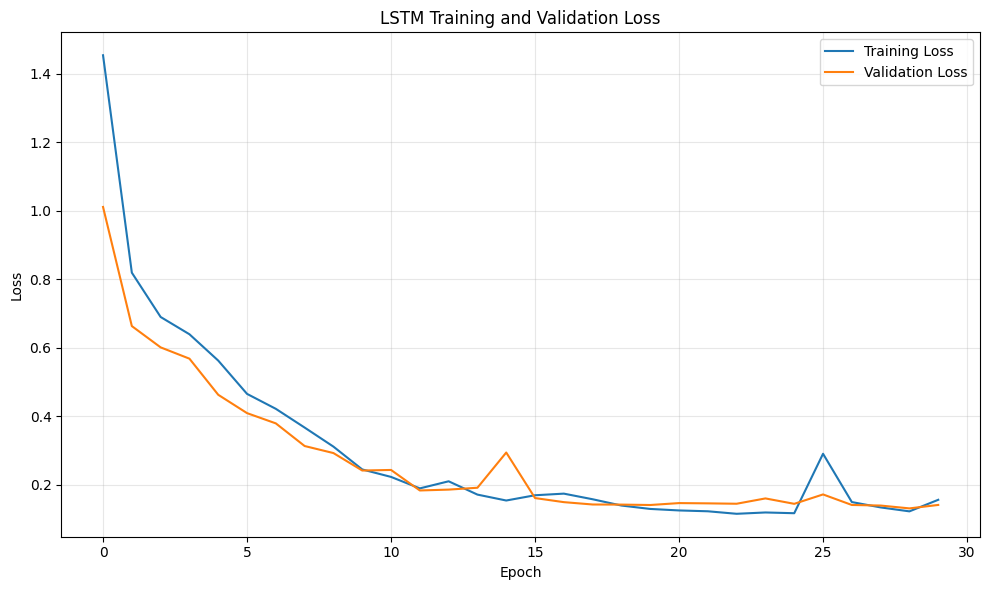

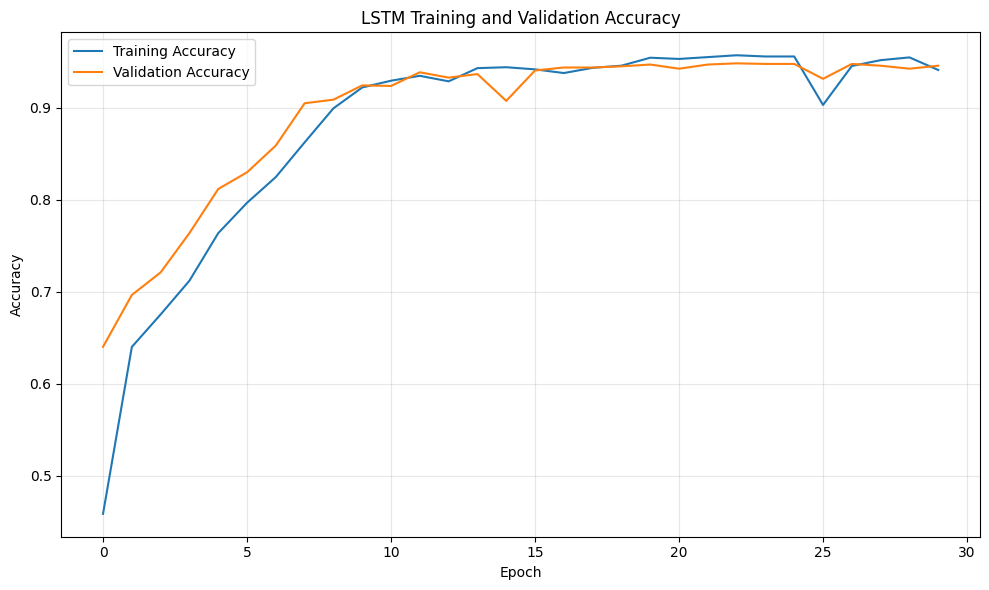

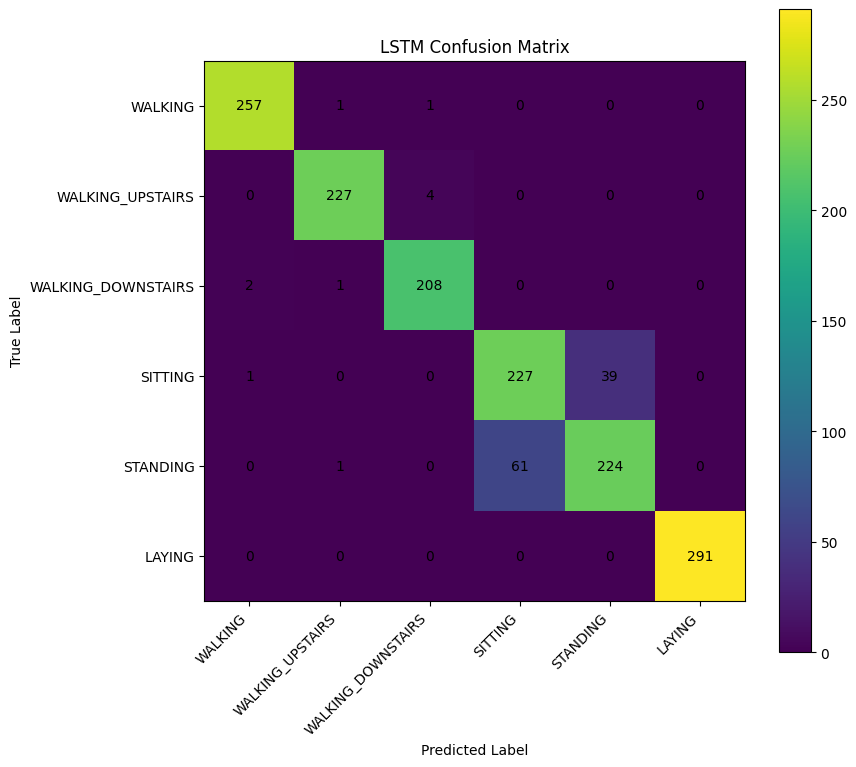


LSTM RESULT RECORD


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Parameters,Training Time (s),Training Time (min)
0,LSTM,0.928155,0.931975,0.932358,0.931727,6006,133.64729,2.227455


In [97]:
# ============================================================
# LSTM — RESULTS, METRICS AND GRAPHS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

print("Generating LSTM predictions...")

lstm_prob = lstm_model.predict(
    X_test_final,
    batch_size=64,
    verbose=0
)

lstm_pred = np.argmax(
    lstm_prob,
    axis=1
)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

lstm_accuracy = accuracy_score(
    y_test_final,
    lstm_pred
)

lstm_precision = precision_score(
    y_test_final,
    lstm_pred,
    average="macro",
    zero_division=0
)

lstm_recall = recall_score(
    y_test_final,
    lstm_pred,
    average="macro",
    zero_division=0
)

lstm_f1 = f1_score(
    y_test_final,
    lstm_pred,
    average="macro",
    zero_division=0
)

lstm_params = lstm_model.count_params()

# ------------------------------------------------------------
# Print metrics
# ------------------------------------------------------------

print("\n============================================================")
print("LSTM TEST RESULTS")
print("============================================================")

print(f"Accuracy          : {lstm_accuracy:.4f}")
print(f"Macro Precision   : {lstm_precision:.4f}")
print(f"Macro Recall      : {lstm_recall:.4f}")
print(f"Macro F1          : {lstm_f1:.4f}")
print(f"Trainable Params  : {lstm_params:,}")
print(f"Training Time     : {lstm_time:.2f} seconds")
print(f"Training Time     : {lstm_time/60:.2f} minutes")

# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\n============================================================")
print("LSTM CLASSIFICATION REPORT")
print("============================================================")

print(
    classification_report(
        y_test_final,
        lstm_pred,
        target_names=activity_names,
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------------------------
# Loss curve
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    lstm_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    lstm_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "06_LSTM_loss_curve.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Accuracy curve
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    lstm_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    lstm_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "07_LSTM_accuracy_curve.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

cm_lstm = confusion_matrix(
    y_test_final,
    lstm_pred
)

plt.figure(figsize=(9, 8))

plt.imshow(
    cm_lstm,
    interpolation="nearest"
)

plt.title("LSTM Confusion Matrix")
plt.colorbar()

tick_marks = np.arange(len(activity_names))

plt.xticks(
    tick_marks,
    activity_names,
    rotation=45,
    ha="right"
)

plt.yticks(
    tick_marks,
    activity_names
)

for i in range(cm_lstm.shape[0]):
    for j in range(cm_lstm.shape[1]):

        plt.text(
            j,
            i,
            str(cm_lstm[i, j]),
            horizontalalignment="center",
            verticalalignment="center"
        )

plt.ylabel("True Label")
plt.xlabel("Predicted Label")
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "08_LSTM_confusion_matrix.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Store LSTM results
# ------------------------------------------------------------

lstm_results = {
    "Model": "LSTM",
    "Accuracy": lstm_accuracy,
    "Macro Precision": lstm_precision,
    "Macro Recall": lstm_recall,
    "Macro F1": lstm_f1,
    "Parameters": lstm_params,
    "Training Time (s)": lstm_time,
    "Training Time (min)": lstm_time / 60
}

print("\n============================================================")
print("LSTM RESULT RECORD")
print("============================================================")

display(
    pd.DataFrame([lstm_results])
)

In [98]:
import time
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dropout, Dense
from tensorflow.keras.optimizers import Adam

gru_model = Sequential([
    GRU(32, input_shape=(128, 9)),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(6, activation="softmax")
])

gru_model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

gru_model.summary()

start_time = time.time()

gru_history = gru_model.fit(
    X_train_exp,
    y_train_exp,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    verbose=1
)

gru_time = time.time() - start_time

print(f"\nGRU Training Time: {gru_time:.2f} seconds")
print(f"GRU Parameters: {gru_model.count_params():,}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,758 (18.59 KB)

 Trainable params: 4,758 (18.59 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 9s 70ms/step - accuracy: 0.4280 - loss: 1.4916 - val_accuracy: 0.5262 - val_loss: 1.2499
Epoch 2/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 9s 56ms/step - accuracy: 0.5437 - loss: 1.1320 - val_accuracy: 0.6207 - val_loss: 0.8621
Epoch 3/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.6367 - loss: 0.8181 - val_accuracy: 0.6880 - val_loss: 0.7223
Epoch 4/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 7s 74ms/step - accuracy: 0.7320 - loss: 0.6123 - val_accuracy: 0.7767 - val_loss: 0.4762
Epoch 5/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.7843 - loss: 0.4634 - val_accuracy: 0.8039 - val_loss: 0.3967
Epoch 6/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 6s 68ms/step - accuracy: 0.8143 - loss: 0.4008 - val_accuracy: 0.8214 - val_loss: 0.3666
Epoch 7/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 9s 55ms/step - accuracy: 0.8440 - loss: 0.3566 - val_accuracy: 0.8634 - val_loss: 0.3673
Epoch 8/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 10s 56ms/step - accuracy: 0.8843 - loss: 0.3106 - val_accuracy: 0.9172 -

In [99]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

gru_pred_prob = gru_model.predict(X_test_final, verbose=0)
gru_pred = np.argmax(gru_pred_prob, axis=1)

gru_accuracy = accuracy_score(y_test_final, gru_pred)
gru_precision = precision_score(y_test_final, gru_pred, average="macro", zero_division=0)
gru_recall = recall_score(y_test_final, gru_pred, average="macro", zero_division=0)
gru_f1 = f1_score(y_test_final, gru_pred, average="macro", zero_division=0)

gru_results = {
    "Model": "GRU",
    "Accuracy": gru_accuracy,
    "Macro Precision": gru_precision,
    "Macro Recall": gru_recall,
    "Macro F1": gru_f1,
    "Parameters": gru_model.count_params(),
    "Training Time (s)": gru_time
}

print("GRU Results")
print("-" * 40)
for key, value in gru_results.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print("\nClassification Report:")
print(classification_report(
    y_test_final,
    gru_pred,
    target_names=activity_names,
    zero_division=0
))

GRU Results
----------------------------------------
Model: GRU
Accuracy: 0.9417
Macro Precision: 0.9452
Macro Recall: 0.9447
Macro F1: 0.9449
Parameters: 4758
Training Time (s): 211.5974

Classification Report:
                    precision    recall  f1-score   support

           WALKING       0.99      1.00      0.99       259
  WALKING_UPSTAIRS       0.98      0.99      0.99       231
WALKING_DOWNSTAIRS       1.00      0.99      0.99       211
           SITTING       0.85      0.83      0.84       267
          STANDING       0.85      0.87      0.86       286
            LAYING       1.00      1.00      1.00       291

          accuracy                           0.94      1545
         macro avg       0.95      0.94      0.94      1545
      weighted avg       0.94      0.94      0.94      1545



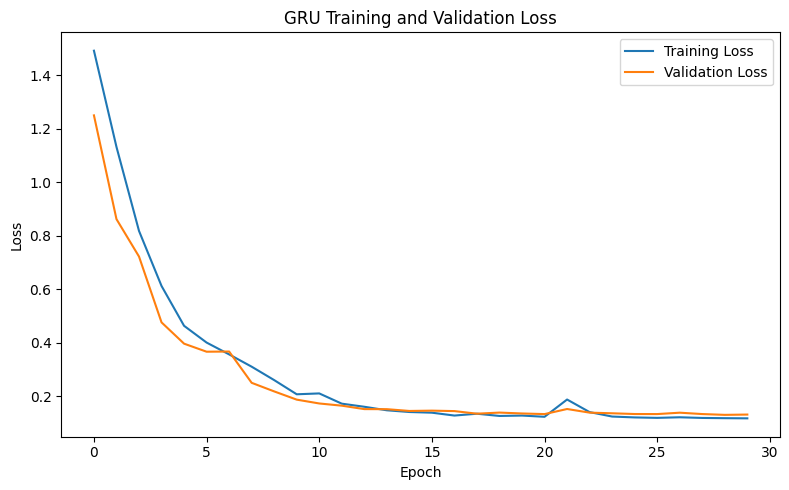

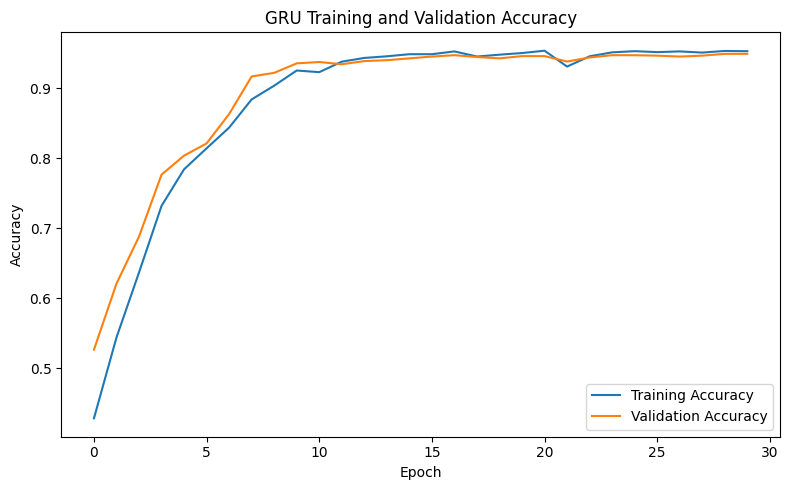

In [100]:
import matplotlib.pyplot as plt

# Loss curve
plt.figure(figsize=(8, 5))
plt.plot(gru_history.history["loss"], label="Training Loss")
plt.plot(gru_history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GRU Training and Validation Loss")
plt.legend()
plt.tight_layout()
plt.savefig(
    GRAPH_DIR / "09_GRU_loss_curve.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)
plt.show()


# Accuracy curve
plt.figure(figsize=(8, 5))
plt.plot(gru_history.history["accuracy"], label="Training Accuracy")
plt.plot(gru_history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("GRU Training and Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig(
    GRAPH_DIR / "10_GRU_accuracy_curve.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)
plt.show()

<Figure size 800x700 with 0 Axes>

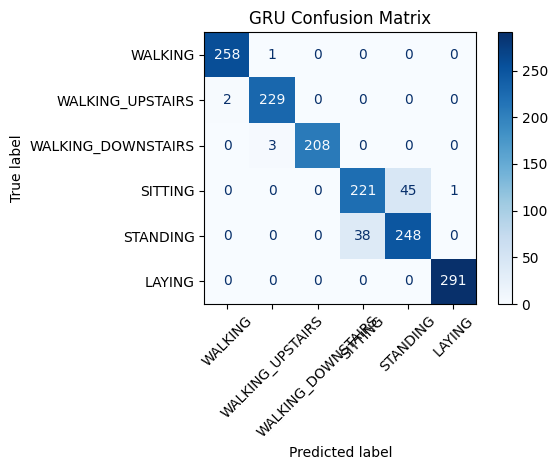

In [101]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_gru = confusion_matrix(y_test_final, gru_pred)

plt.figure(figsize=(8, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_gru,
    display_labels=activity_names
)

disp.plot(
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("GRU Confusion Matrix")
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "11_GRU_confusion_matrix.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [102]:
comparison_df = pd.DataFrame([
    rnn_results,
    lstm_results,
    gru_results
])

print("RNN vs LSTM vs GRU Comparison")
display(comparison_df)

comparison_df.to_csv(
    GRAPH_DIR / "RNN_LSTM_GRU_comparison.csv",
    index=False
)

RNN vs LSTM vs GRU Comparison


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Parameters,Training Time (s),Training Time (min)
0,RNN,0.798706,0.788908,0.789683,0.789134,1974,69.770638,1.162844
1,LSTM,0.928155,0.931975,0.932358,0.931727,6006,133.647290,2.227455
2,GRU,0.941748,0.945236,0.944685,0.944895,4758,211.597408,NaN


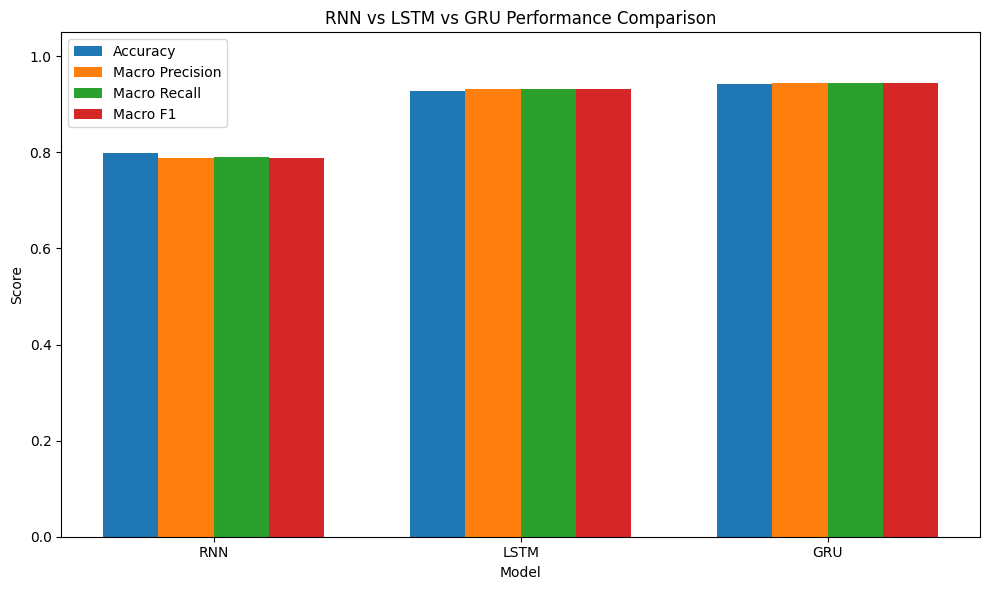

In [103]:
import matplotlib.pyplot as plt
import numpy as np

models = comparison_df["Model"].values

metrics = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

x = np.arange(len(models))
width = 0.18

plt.figure(figsize=(10, 6))

for i, metric in enumerate(metrics):
    plt.bar(
        x + (i - 1.5) * width,
        comparison_df[metric].values,
        width,
        label=metric
    )

plt.xticks(x, models)
plt.ylabel("Score")
plt.xlabel("Model")
plt.title("RNN vs LSTM vs GRU Performance Comparison")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "12_model_performance_comparison.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

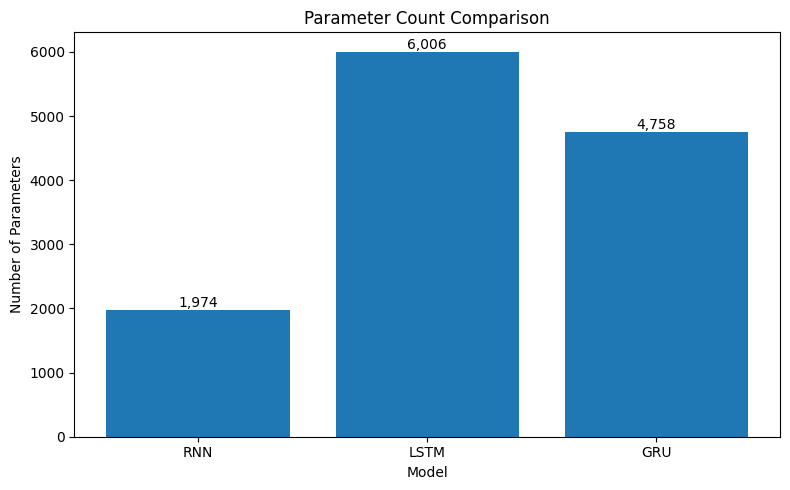

In [104]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Parameters"]
)

plt.xlabel("Model")
plt.ylabel("Number of Parameters")
plt.title("Parameter Count Comparison")

for i, value in enumerate(comparison_df["Parameters"]):
    plt.text(
        i,
        value,
        f"{value:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "13_parameter_comparison.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

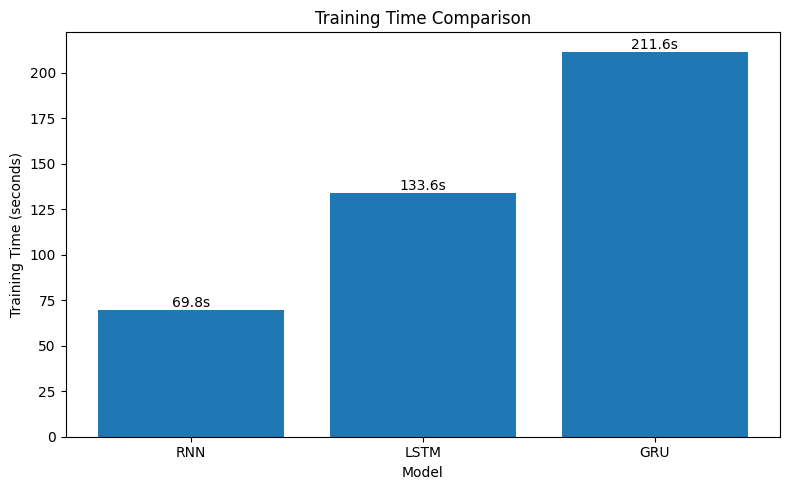

In [105]:
plt.figure(figsize=(8, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Training Time (s)"]
)

plt.xlabel("Model")
plt.ylabel("Training Time (seconds)")
plt.title("Training Time Comparison")

for i, value in enumerate(comparison_df["Training Time (s)"]):
    plt.text(
        i,
        value,
        f"{value:.1f}s",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "14_training_time_comparison.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [106]:
def resize_sequence(X, target_length):
    """
    Convert sequences from 128 time steps to target_length
    using uniformly selected time steps.
    """
    if target_length == X.shape[1]:
        return X.copy()

    indices = np.linspace(
        0,
        X.shape[1] - 1,
        target_length
    ).astype(int)

    return X[:, indices, :]


sequence_lengths = [32, 64, 128]

X_train_seq = {}
X_val_seq = {}
X_test_seq = {}

for seq_len in sequence_lengths:
    X_train_seq[seq_len] = resize_sequence(X_train_exp, seq_len)
    X_val_seq[seq_len] = resize_sequence(X_val, seq_len)
    X_test_seq[seq_len] = resize_sequence(X_test_final, seq_len)

    print(
        f"Sequence length {seq_len}: "
        f"Train {X_train_seq[seq_len].shape}, "
        f"Val {X_val_seq[seq_len].shape}, "
        f"Test {X_test_seq[seq_len].shape}"
    )

Sequence length 32: Train (3000, 32, 9), Val (1545, 32, 9), Test (1545, 32, 9)
Sequence length 64: Train (3000, 64, 9), Val (1545, 64, 9), Test (1545, 64, 9)
Sequence length 128: Train (3000, 128, 9), Val (1545, 128, 9), Test (1545, 128, 9)


In [107]:
from tensorflow.keras.backend import clear_session

sequence_results = []
sequence_histories = {}
sequence_models = {}

SEQ_EPOCHS = 30
SEQ_BATCH_SIZE = 32

for seq_len in sequence_lengths:

    print("\n" + "=" * 60)
    print(f"Training GRU with sequence length = {seq_len}")
    print("=" * 60)

    clear_session()

    model = Sequential([
        GRU(32, input_shape=(seq_len, 9)),
        Dropout(0.2),
        Dense(16, activation="relu"),
        Dense(6, activation="softmax")
    ])

    model.compile(
        optimizer=Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    start = time.time()

    history = model.fit(
        X_train_seq[seq_len],
        y_train_exp,
        validation_data=(
            X_val_seq[seq_len],
            y_val
        ),
        epochs=SEQ_EPOCHS,
        batch_size=SEQ_BATCH_SIZE,
        verbose=1
    )

    training_time = time.time() - start

    # Test prediction
    probabilities = model.predict(
        X_test_seq[seq_len],
        verbose=0
    )

    predictions = np.argmax(probabilities, axis=1)

    accuracy = accuracy_score(
        y_test_final,
        predictions
    )

    precision = precision_score(
        y_test_final,
        predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test_final,
        predictions,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test_final,
        predictions,
        average="macro",
        zero_division=0
    )

    sequence_results.append({
        "Sequence Length": seq_len,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
        "Parameters": model.count_params(),
        "Training Time (s)": training_time
    })

    sequence_histories[seq_len] = history
    sequence_models[seq_len] = model

    print(f"\nSequence Length: {seq_len}")
    print(f"Accuracy:        {accuracy:.4f}")
    print(f"Macro Precision: {precision:.4f}")
    print(f"Macro Recall:    {recall:.4f}")
    print(f"Macro F1:        {f1:.4f}")
    print(f"Parameters:      {model.count_params():,}")
    print(f"Training Time:   {training_time:.2f} seconds")


Training GRU with sequence length = 32
Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 0.4457 - loss: 1.5011 - val_accuracy: 0.5935 - val_loss: 1.1489
Epoch 2/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.6627 - loss: 0.8904 - val_accuracy: 0.8013 - val_loss: 0.5724
Epoch 3/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.8190 - loss: 0.4982 - val_accuracy: 0.8828 - val_loss: 0.3574
Epoch 4/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.9017 - loss: 0.3096 - val_accuracy: 0.9223 - val_loss: 0.2411
Epoch 5/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.9213 - loss: 0.2341 - val_accuracy: 0.9359 - val_loss: 0.1928
Epoch 6/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9323 - loss: 0.1991 - val_accuracy: 0.9424 - val_loss: 0.1664
Epoch 7/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9430 - loss: 0.1648 - val_accuracy: 0.9379 - val_loss: 0.1580
Epoch 8/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9460 - loss: 0.1527 - val_accuracy: 0.9424 - val_loss: 0.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


94/94 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.3737 - loss: 1.4968 - val_accuracy: 0.5605 - val_loss: 1.1331
Epoch 2/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.6363 - loss: 0.9013 - val_accuracy: 0.7560 - val_loss: 0.5934
Epoch 3/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step - accuracy: 0.7643 - loss: 0.5288 - val_accuracy: 0.8058 - val_loss: 0.4029
Epoch 4/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.8150 - loss: 0.4042 - val_accuracy: 0.8343 - val_loss: 0.3610
Epoch 5/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.8443 - loss: 0.3660 - val_accuracy: 0.8505 - val_loss: 0.3302
Epoch 6/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.8773 - loss: 0.3213 - val_accuracy: 0.9003 - val_loss: 0.2995
Epoch 7/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.9110 - loss: 0.2636 - val_accuracy: 0.9217 - val_loss: 0.2278
Epoch 8/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.9010 - loss: 0.2695 - val_accuracy: 0.8958 - val_loss: 0.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


94/94 ━━━━━━━━━━━━━━━━━━━━ 8s 62ms/step - accuracy: 0.3977 - loss: 1.5147 - val_accuracy: 0.5702 - val_loss: 1.2424
Epoch 2/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 6s 68ms/step - accuracy: 0.6003 - loss: 1.1317 - val_accuracy: 0.7191 - val_loss: 0.8789
Epoch 3/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.6990 - loss: 0.8285 - val_accuracy: 0.7547 - val_loss: 0.6664
Epoch 4/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 11s 65ms/step - accuracy: 0.7790 - loss: 0.6261 - val_accuracy: 0.8252 - val_loss: 0.5115
Epoch 5/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 58ms/step - accuracy: 0.8420 - loss: 0.4810 - val_accuracy: 0.8932 - val_loss: 0.3403
Epoch 6/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 7s 71ms/step - accuracy: 0.9043 - loss: 0.3198 - val_accuracy: 0.9346 - val_loss: 0.2245
Epoch 7/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.9317 - loss: 0.2256 - val_accuracy: 0.9430 - val_loss: 0.1734
Epoch 8/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 10s 56ms/step - accuracy: 0.9420 - loss: 0.1810 - val_accuracy: 0.9430 - val_loss: 

In [108]:
sequence_df = pd.DataFrame(sequence_results)

print("Sequence Length Comparison")
display(sequence_df)

sequence_df.to_csv(
    GRAPH_DIR / "sequence_length_comparison.csv",
    index=False
)

Sequence Length Comparison


,Sequence Length,Accuracy,Macro Precision,Macro Recall,Macro F1,Parameters,Training Time (s)
0,32,0.942395,0.945801,0.945136,0.945290,4758,59.930655
1,64,0.942395,0.945791,0.945400,0.945573,4758,106.151561
2,128,0.941748,0.944951,0.945117,0.944813,4758,215.888841


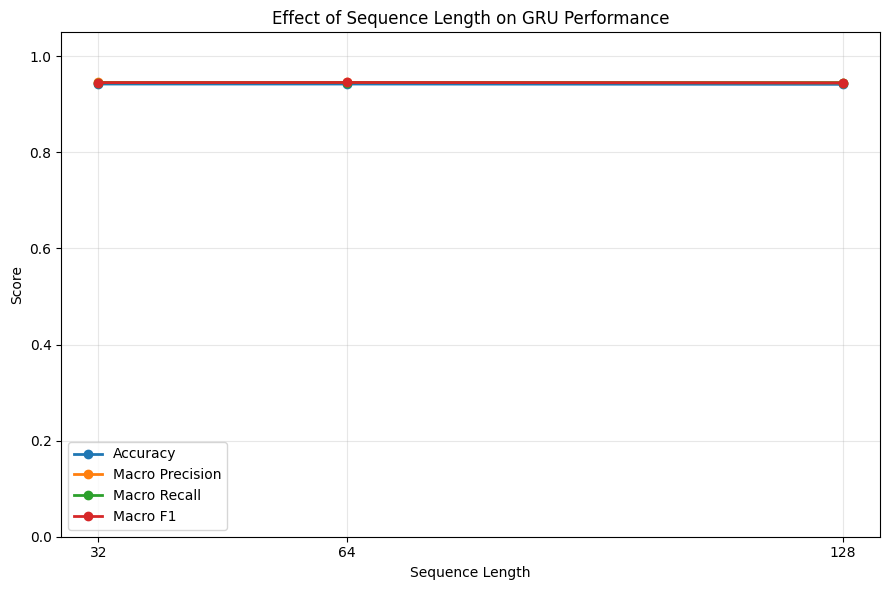

In [109]:
plt.figure(figsize=(9, 6))

for metric in ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]:
    plt.plot(
        sequence_df["Sequence Length"],
        sequence_df[metric],
        marker="o",
        linewidth=2,
        label=metric
    )

plt.xlabel("Sequence Length")
plt.ylabel("Score")
plt.title("Effect of Sequence Length on GRU Performance")
plt.xticks([32, 64, 128])
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "15_sequence_length_performance.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

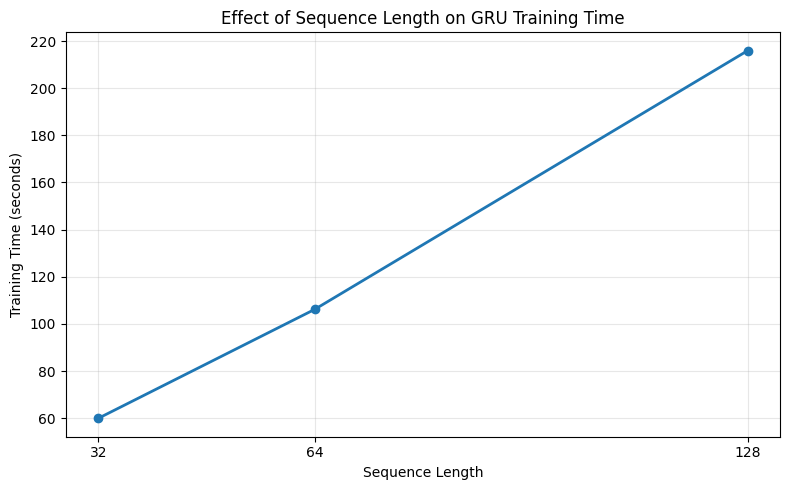

In [110]:
plt.figure(figsize=(8, 5))

plt.plot(
    sequence_df["Sequence Length"],
    sequence_df["Training Time (s)"],
    marker="o",
    linewidth=2
)

plt.xlabel("Sequence Length")
plt.ylabel("Training Time (seconds)")
plt.title("Effect of Sequence Length on GRU Training Time")
plt.xticks([32, 64, 128])
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "16_sequence_length_training_time.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

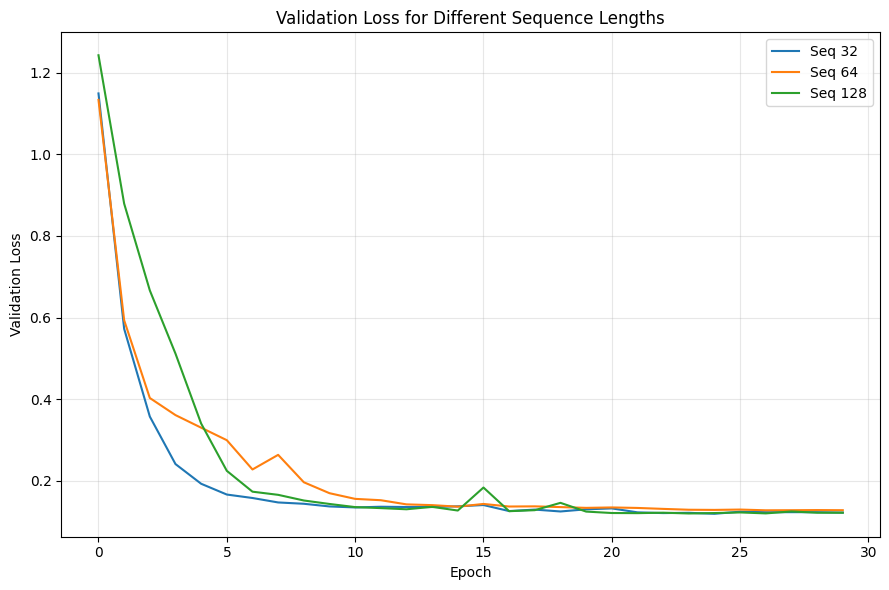

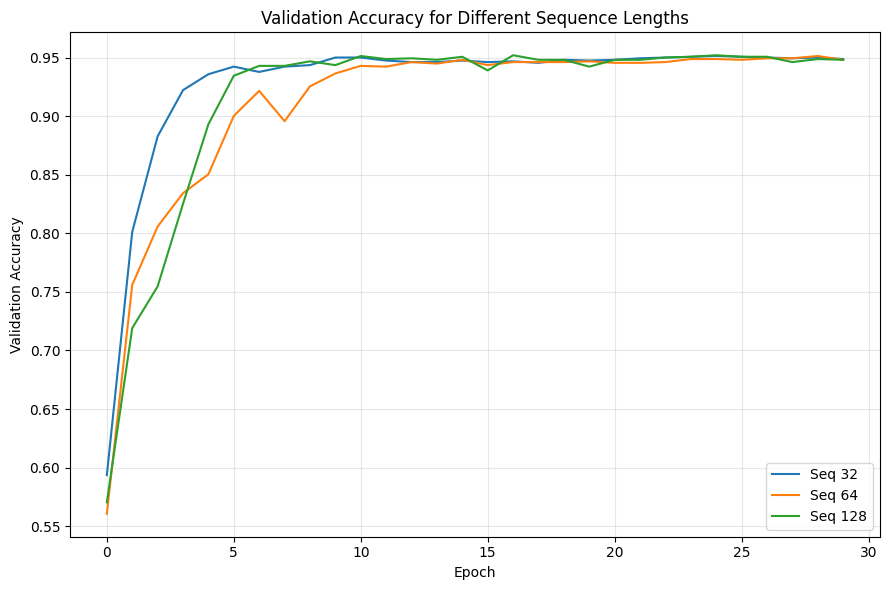

In [111]:
# Loss curves
plt.figure(figsize=(9, 6))

for seq_len in sequence_lengths:
    history = sequence_histories[seq_len]

    plt.plot(
        history.history["val_loss"],
        label=f"Seq {seq_len}"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss for Different Sequence Lengths")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "17_sequence_length_loss_curves.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# Accuracy curves
plt.figure(figsize=(9, 6))

for seq_len in sequence_lengths:
    history = sequence_histories[seq_len]

    plt.plot(
        history.history["val_accuracy"],
        label=f"Seq {seq_len}"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy for Different Sequence Lengths")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "18_sequence_length_accuracy_curves.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

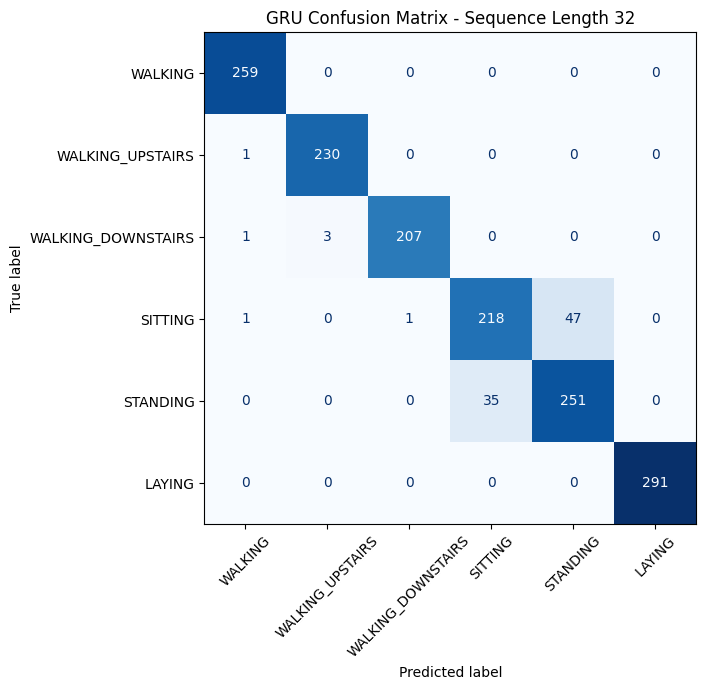

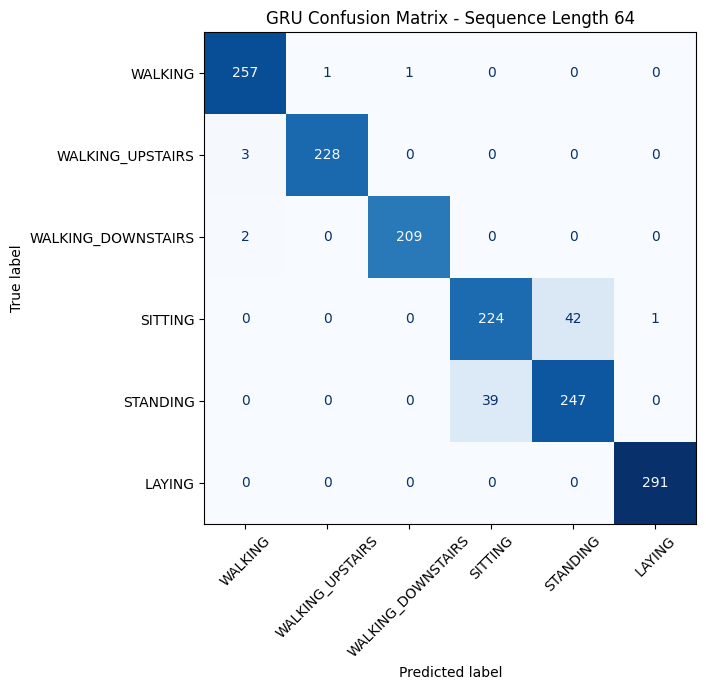

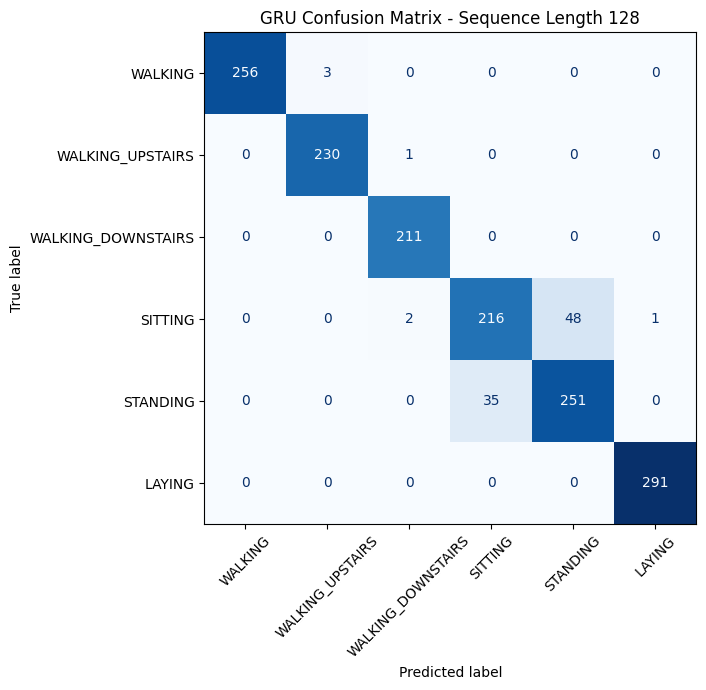

In [112]:
for seq_len in sequence_lengths:

    model = sequence_models[seq_len]

    predictions = np.argmax(
        model.predict(X_test_seq[seq_len], verbose=0),
        axis=1
    )

    cm = confusion_matrix(
        y_test_final,
        predictions
    )

    fig, ax = plt.subplots(figsize=(8, 7))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=activity_names
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=45,
        values_format="d",
        colorbar=False
    )

    ax.set_title(
        f"GRU Confusion Matrix - Sequence Length {seq_len}"
    )

    plt.tight_layout()

    plt.savefig(
        GRAPH_DIR / f"19_confusion_matrix_seq_{seq_len}.eps",
        format="eps",
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()

In [113]:
!pip -q install opencv-python-headless imageio-ffmpeg

In [114]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [115]:
VIDEO_ROOT = Path("/content/experiment6/UCF101_subset")

VIDEO_ROOT.mkdir(parents=True, exist_ok=True)

VIDEO_CLASSES = [
    "BasketballShooting",
    "Biking",
    "GolfSwing"
]

for cls in VIDEO_CLASSES:
    (VIDEO_ROOT / cls).mkdir(parents=True, exist_ok=True)

print("Video dataset directory:")
print(VIDEO_ROOT)

for cls in VIDEO_CLASSES:
    print(cls, "->", VIDEO_ROOT / cls)

Video dataset directory:
/content/experiment6/UCF101_subset
BasketballShooting -> /content/experiment6/UCF101_subset/BasketballShooting
Biking -> /content/experiment6/UCF101_subset/Biking
GolfSwing -> /content/experiment6/UCF101_subset/GolfSwing


In [116]:
VIDEO_EXTENSIONS = {".avi", ".mp4", ".mov", ".mkv"}

video_files = []

for cls in VIDEO_CLASSES:
    class_dir = VIDEO_ROOT / cls

    files = [
        f for f in class_dir.iterdir()
        if f.suffix.lower() in VIDEO_EXTENSIONS
    ]

    print(f"{cls}: {len(files)} videos")

    for f in files:
        video_files.append((str(f), cls))

print("\nTotal videos:", len(video_files))

BasketballShooting: 0 videos
Biking: 0 videos
GolfSwing: 0 videos

Total videos: 0


In [117]:
IMG_SIZE = (224, 224)
NUM_FRAMES = 10

def extract_uniform_frames(video_path, num_frames=10):
    cap = cv2.VideoCapture(video_path)

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        return None

    frame_indices = np.linspace(
        0,
        total_frames - 1,
        num_frames
    ).astype(int)

    frames = []

    for idx in frame_indices:

        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))

        ret, frame = cap.read()

        if not ret:
            continue

        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        frame = cv2.resize(
            frame,
            IMG_SIZE
        )

        frames.append(frame)

    cap.release()

    if len(frames) != num_frames:
        return None

    return np.array(frames, dtype=np.uint8)

In [118]:
video_sequences = []
video_labels = []
video_paths = []

MAX_VIDEOS_PER_CLASS = 10

for class_id, cls in enumerate(VIDEO_CLASSES):

    class_dir = VIDEO_ROOT / cls

    files = sorted([
        f for f in class_dir.iterdir()
        if f.suffix.lower() in VIDEO_EXTENSIONS
    ])[:MAX_VIDEOS_PER_CLASS]

    print(f"\nProcessing {cls}: {len(files)} videos")

    for video_path in files:

        frames = extract_uniform_frames(
            str(video_path),
            NUM_FRAMES
        )

        if frames is None:
            print("Skipped:", video_path.name)
            continue

        video_sequences.append(frames)
        video_labels.append(class_id)
        video_paths.append(str(video_path))

video_sequences = np.array(video_sequences)
video_labels = np.array(video_labels)

print("\nFinal video data:")
print("Shape:", video_sequences.shape)
print("Labels:", video_labels.shape)

print("\nExpected shape:")
print("(number_of_videos, 10, 224, 224, 3)")


Processing BasketballShooting: 0 videos

Processing Biking: 0 videos

Processing GolfSwing: 0 videos

Final video data:
Shape: (0,)
Labels: (0,)

Expected shape:
(number_of_videos, 10, 224, 224, 3)


In [120]:
from pathlib import Path

VIDEO_ROOT = Path("/content/experiment6/UCF101_subset")

print("Exists:", VIDEO_ROOT.exists())

if VIDEO_ROOT.exists():
    print("\nContents:")
    for p in VIDEO_ROOT.rglob("*"):
        if p.is_file():
            print(p)

Exists: True

Contents:


In [121]:
!pip -q install huggingface_hub

In [130]:
# from huggingface_hub import hf_hub_download
# import tarfile
# from pathlib import Path

# print("Downloading small UCF101 subset...")

# file_path = hf_hub_download(
#     repo_id="sayakpaul/ucf101-subset",
#     filename="UCF101_subset.tar.gz",
#     repo_type="dataset"
# )

# print("Downloaded:", file_path)

# extract_dir = Path("/content/experiment6")

# with tarfile.open(file_path, "r:gz") as tar:
#     tar.extractall(extract_dir)

# print("\nExtracted successfully.")

In [123]:
from pathlib import Path
import gzip

file_path = Path("/root/.cache/huggingface/hub/datasets--sayakpaul--ucf101-subset")

# Find the downloaded tar.gz file automatically
tar_files = list(file_path.rglob("UCF101_subset.tar.gz"))

print("Found files:", tar_files)

if tar_files:
    f = tar_files[0]
    print("File:", f)
    print("Size:", round(f.stat().st_size / (1024**2), 2), "MB")

    with open(f, "rb") as file:
        header = file.read(20)

    print("First bytes:", header)

Found files: [PosixPath('/root/.cache/huggingface/hub/datasets--sayakpaul--ucf101-subset/snapshots/b9984b8d2a95e4a1879e1b071e9433858d0bc24a/UCF101_subset.tar.gz')]
File: /root/.cache/huggingface/hub/datasets--sayakpaul--ucf101-subset/snapshots/b9984b8d2a95e4a1879e1b071e9433858d0bc24a/UCF101_subset.tar.gz
Size: 163.45 MB
First bytes: b'UCF101_subset/\x00\x00\x00\x00\x00\x00'


In [124]:
import tarfile
from pathlib import Path

f = tar_files[0]
extract_dir = Path("/content/experiment6")

print("Extracting:", f)

# Check whether it is really gzip
with open(f, "rb") as file:
    header = file.read(2)

print("Header:", header)

if header == b"\x1f\x8b":
    print("Valid gzip file.")

    with tarfile.open(f, "r:gz") as tar:
        tar.extractall(extract_dir, filter="data")

else:
    print("Not gzip. Trying normal TAR format...")

    with tarfile.open(f, "r:") as tar:
        tar.extractall(extract_dir, filter="data")

print("Extraction completed.")

Extracting: /root/.cache/huggingface/hub/datasets--sayakpaul--ucf101-subset/snapshots/b9984b8d2a95e4a1879e1b071e9433858d0bc24a/UCF101_subset.tar.gz
Header: b'UC'
Not gzip. Trying normal TAR format...
Extraction completed.


In [125]:
from pathlib import Path

possible_roots = [
    Path("/content/experiment6/UCF101_subset"),
    Path("/content/UCF101_subset")
]

VIDEO_ROOT = None

for root in possible_roots:
    if root.exists():
        VIDEO_ROOT = root
        break

print("VIDEO_ROOT:", VIDEO_ROOT)

if VIDEO_ROOT:
    for split in ["train", "val", "test"]:
        split_dir = VIDEO_ROOT / split

        print(f"\n{split.upper()}")

        if split_dir.exists():
            classes = sorted([
                p.name for p in split_dir.iterdir()
                if p.is_dir()
            ])

            for cls in classes:
                videos = [
                    p for p in (split_dir / cls).iterdir()
                    if p.is_file()
                ]
                print(f"{cls}: {len(videos)} videos")
        else:
            print("Split not found")

VIDEO_ROOT: /content/experiment6/UCF101_subset

TRAIN
ApplyEyeMakeup: 30 videos
ApplyLipstick: 30 videos
Archery: 30 videos
BabyCrawling: 30 videos
BalanceBeam: 30 videos
BandMarching: 30 videos
BaseballPitch: 30 videos
Basketball: 30 videos
BasketballDunk: 30 videos
BenchPress: 30 videos

VAL
ApplyEyeMakeup: 3 videos
ApplyLipstick: 3 videos
Archery: 3 videos
BabyCrawling: 3 videos
BalanceBeam: 3 videos
BandMarching: 3 videos
BaseballPitch: 3 videos
Basketball: 3 videos
BasketballDunk: 3 videos
BenchPress: 3 videos

TEST
ApplyEyeMakeup: 6 videos
ApplyLipstick: 4 videos
Archery: 7 videos
BabyCrawling: 9 videos
BalanceBeam: 4 videos
BandMarching: 9 videos
BaseballPitch: 10 videos
Basketball: 11 videos
BasketballDunk: 6 videos
BenchPress: 9 videos


In [126]:
from pathlib import Path

VIDEO_ROOT = Path("/content/experiment6/UCF101_subset")

print("Dataset structure:\n")

for split in ["train", "val", "test"]:
    split_dir = VIDEO_ROOT / split

    if split_dir.exists():
        print(f"\n{split.upper()}:")

        classes = [
            p.name
            for p in split_dir.iterdir()
            if p.is_dir()
        ]

        print(classes)

Dataset structure:


TRAIN:
['BalanceBeam', 'BasketballDunk', 'Basketball', 'BenchPress', 'ApplyLipstick', 'Archery', 'BabyCrawling', 'BandMarching', 'ApplyEyeMakeup', 'BaseballPitch']

VAL:
['BalanceBeam', 'BasketballDunk', 'Basketball', 'BenchPress', 'ApplyLipstick', 'Archery', 'BabyCrawling', 'BandMarching', 'ApplyEyeMakeup', 'BaseballPitch']

TEST:
['BalanceBeam', 'BasketballDunk', 'Basketball', 'BenchPress', 'ApplyLipstick', 'Archery', 'BabyCrawling', 'BandMarching', 'ApplyEyeMakeup', 'BaseballPitch']


In [133]:
# ============================================================
# VIDEO DATASET FIX
# ============================================================

from pathlib import Path
import tarfile
import shutil

CACHE_ROOT = Path("/root/.cache/huggingface/hub/datasets--sayakpaul--ucf101-subset")

# Find downloaded archive
tar_files = list(CACHE_ROOT.rglob("UCF101_subset.tar.gz"))

print("Downloaded archive(s):")
for f in tar_files:
    print(f, "->", round(f.stat().st_size / (1024**2), 2), "MB")

if len(tar_files) == 0:
    raise FileNotFoundError("UCF101_subset.tar.gz was not found.")

ARCHIVE = tar_files[0]

# ------------------------------------------------------------
# Extract archive
# ------------------------------------------------------------

EXTRACT_DIR = Path("/content/experiment6")
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

print("\nExtracting dataset...")

try:
    # First try normal TAR because the downloaded file
    # is apparently not gzip-compressed.
    with tarfile.open(ARCHIVE, "r:") as tar:
        tar.extractall(EXTRACT_DIR, filter="data")

    print("Extraction successful using normal TAR format.")

except Exception as e:
    print("Normal TAR extraction failed:", e)

    # Fallback: gzip
    with tarfile.open(ARCHIVE, "r:gz") as tar:
        tar.extractall(EXTRACT_DIR, filter="data")

    print("Extraction successful using GZIP format.")


# ------------------------------------------------------------
# Locate UCF101_subset
# ------------------------------------------------------------

possible_roots = [
    EXTRACT_DIR / "UCF101_subset",
    Path("/content/UCF101_subset")
]

VIDEO_ROOT = None

for root in possible_roots:
    if root.exists() and (root / "train").exists():
        VIDEO_ROOT = root
        break

if VIDEO_ROOT is None:
    # Search automatically
    matches = list(Path("/content").rglob("UCF101_subset"))

    for root in matches:
        if root.is_dir() and (root / "train").exists():
            VIDEO_ROOT = root
            break

if VIDEO_ROOT is None:
    raise FileNotFoundError(
        "UCF101_subset was not found after extraction."
    )

print("\nVIDEO_ROOT:")
print(VIDEO_ROOT)


# ------------------------------------------------------------
# Check dataset
# ------------------------------------------------------------

VIDEO_EXTENSIONS = {".avi", ".mp4", ".mov", ".mkv"}

def get_videos(folder):
    return sorted([
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in VIDEO_EXTENSIONS
    ])


print("\nDataset contents:")

for split in ["train", "val", "test"]:

    split_dir = VIDEO_ROOT / split

    print(f"\n{split.upper()}")

    classes = sorted([
        p.name for p in split_dir.iterdir()
        if p.is_dir()
    ])

    for cls in classes:
        videos = get_videos(split_dir / cls)
        print(f"{cls:25s} : {len(videos)} videos")

Downloaded archive(s):
/root/.cache/huggingface/hub/datasets--sayakpaul--ucf101-subset/snapshots/b9984b8d2a95e4a1879e1b071e9433858d0bc24a/UCF101_subset.tar.gz -> 163.45 MB

Extracting dataset...
Extraction successful using normal TAR format.

VIDEO_ROOT:
/content/experiment6/UCF101_subset

Dataset contents:

TRAIN
ApplyEyeMakeup            : 30 videos
ApplyLipstick             : 30 videos
Archery                   : 30 videos
BabyCrawling              : 30 videos
BalanceBeam               : 30 videos
BandMarching              : 30 videos
BaseballPitch             : 30 videos
Basketball                : 30 videos
BasketballDunk            : 30 videos
BenchPress                : 30 videos

VAL
ApplyEyeMakeup            : 3 videos
ApplyLipstick             : 3 videos
Archery                   : 3 videos
BabyCrawling              : 3 videos
BalanceBeam               : 3 videos
BandMarching              : 3 videos
BaseballPitch             : 3 videos
Basketball                : 3 videos
Bas

In [134]:
# ============================================================
# SELECT 3 CLASSES FOR OUR EXPERIMENT
# ============================================================

from collections import defaultdict

# Get classes present in every split
split_classes = {}

for split in ["train", "val", "test"]:
    split_classes[split] = {
        p.name for p in (VIDEO_ROOT / split).iterdir()
        if p.is_dir()
    }

common_classes = sorted(
    split_classes["train"]
    & split_classes["val"]
    & split_classes["test"]
)

print("Classes available in all splits:")
print(common_classes)


# ------------------------------------------------------------
# Find classes with enough videos
# ------------------------------------------------------------

eligible_classes = []

for cls in common_classes:

    train_count = len(get_videos(VIDEO_ROOT / "train" / cls))
    val_count = len(get_videos(VIDEO_ROOT / "val" / cls))
    test_count = len(get_videos(VIDEO_ROOT / "test" / cls))

    if train_count >= 10 and val_count >= 3 and test_count >= 3:
        eligible_classes.append(cls)

print("\nEligible classes:")
print(eligible_classes)


if len(eligible_classes) < 3:
    raise ValueError(
        f"Only {len(eligible_classes)} classes have enough videos. "
        "Need at least 3."
    )


# Select first 3
VIDEO_CLASSES = eligible_classes[:3]

print("\nSelected classes:")
print(VIDEO_CLASSES)


# ------------------------------------------------------------
# Create label mapping
# ------------------------------------------------------------

VIDEO_LABEL_MAP = {
    cls: i for i, cls in enumerate(VIDEO_CLASSES)
}

print("\nLabel mapping:")
print(VIDEO_LABEL_MAP)


# ------------------------------------------------------------
# Build file lists
# ------------------------------------------------------------

VIDEO_FILES = {}

limits = {
    "train": 10,
    "val": 3,
    "test": 3
}

for split in ["train", "val", "test"]:

    items = []

    for cls in VIDEO_CLASSES:

        videos = get_videos(
            VIDEO_ROOT / split / cls
        )

        # Small subset for faster experiment
        videos = videos[:limits[split]]

        for video_path in videos:
            items.append(
                (video_path, VIDEO_LABEL_MAP[cls])
            )

    VIDEO_FILES[split] = items


# ------------------------------------------------------------
# Print final dataset sizes
# ------------------------------------------------------------

print("\nFINAL VIDEO DATASET")

for split in ["train", "val", "test"]:

    print(
        f"{split.capitalize():10s}: "
        f"{len(VIDEO_FILES[split])} videos"
    )

    for cls in VIDEO_CLASSES:

        count = sum(
            1
            for path, label in VIDEO_FILES[split]
            if label == VIDEO_LABEL_MAP[cls]
        )

        print(f"    {cls:25s}: {count}")

Classes available in all splits:
['ApplyEyeMakeup', 'ApplyLipstick', 'Archery', 'BabyCrawling', 'BalanceBeam', 'BandMarching', 'BaseballPitch', 'Basketball', 'BasketballDunk', 'BenchPress']

Eligible classes:
['ApplyEyeMakeup', 'ApplyLipstick', 'Archery', 'BabyCrawling', 'BalanceBeam', 'BandMarching', 'BaseballPitch', 'Basketball', 'BasketballDunk', 'BenchPress']

Selected classes:
['ApplyEyeMakeup', 'ApplyLipstick', 'Archery']

Label mapping:
{'ApplyEyeMakeup': 0, 'ApplyLipstick': 1, 'Archery': 2}

FINAL VIDEO DATASET
Train     : 30 videos
    ApplyEyeMakeup           : 10
    ApplyLipstick            : 10
    Archery                  : 10
Val       : 9 videos
    ApplyEyeMakeup           : 3
    ApplyLipstick            : 3
    Archery                  : 3
Test      : 9 videos
    ApplyEyeMakeup           : 3
    ApplyLipstick            : 3
    Archery                  : 3


In [135]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

mobilenet = MobileNetV2(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(224, 224, 3)
)

mobilenet.trainable = False

print("MobileNetV2 loaded")
print("Trainable:", mobilenet.trainable)
print("Feature dimension:", mobilenet.output_shape[-1])

MobileNetV2 loaded
Trainable: False
Feature dimension: 1280


In [137]:
# ============================================================
# VIDEO FRAME EXTRACTION + MOBILENETV2 FEATURE EXTRACTION
# ============================================================

import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

IMG_SIZE = 224
NUM_FRAMES = 10

# ------------------------------------------------------------
# Load pretrained MobileNetV2
# ------------------------------------------------------------

cnn = MobileNetV2(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(224, 224, 3)
)

# Freeze CNN
cnn.trainable = False

print("MobileNetV2 loaded.")
print("Feature dimension:", cnn.output_shape[-1])


# ------------------------------------------------------------
# Extract 10 uniformly sampled frames from one video
# ------------------------------------------------------------

def extract_frames(video_path, num_frames=10):

    cap = cv2.VideoCapture(str(video_path))

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        return None

    # Uniformly sample frames
    frame_indices = np.linspace(
        0,
        total_frames - 1,
        num_frames
    ).astype(int)

    frames = []

    for idx in frame_indices:

        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))

        success, frame = cap.read()

        if not success:
            continue

        # OpenCV BGR -> RGB
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        # Resize to MobileNetV2 input size
        frame = cv2.resize(
            frame,
            (IMG_SIZE, IMG_SIZE)
        )

        frames.append(frame)

    cap.release()

    # If fewer than 10 frames were obtained,
    # duplicate the last frame
    if len(frames) == 0:
        return None

    while len(frames) < num_frames:
        frames.append(frames[-1].copy())

    return np.array(frames[:num_frames], dtype=np.float32)


# ------------------------------------------------------------
# Extract CNN features for a dataset split
# ------------------------------------------------------------

def extract_video_features(video_items):

    all_features = []
    all_labels = []

    for i, (video_path, label) in enumerate(video_items):

        frames = extract_frames(
            video_path,
            NUM_FRAMES
        )

        if frames is None:
            print("Skipping:", video_path)
            continue

        # MobileNetV2 preprocessing
        frames_preprocessed = preprocess_input(frames)

        # Extract features for all 10 frames
        features = cnn.predict(
            frames_preprocessed,
            batch_size=10,
            verbose=0
        )

        # Shape: (10, 1280)
        all_features.append(features)
        all_labels.append(label)

        if (i + 1) % 5 == 0:
            print(
                f"Processed {i + 1}/{len(video_items)} videos"
            )

    return (
        np.array(all_features, dtype=np.float32),
        np.array(all_labels, dtype=np.int32)
    )


# ------------------------------------------------------------
# TRAIN
# ------------------------------------------------------------

print("\nExtracting TRAIN features...")

X_video_train_features, y_video_train = extract_video_features(
    VIDEO_FILES["train"]
)

print(
    "Train feature shape:",
    X_video_train_features.shape
)


# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

print("\nExtracting VALIDATION features...")

X_video_val_features, y_video_val = extract_video_features(
    VIDEO_FILES["val"]
)

print(
    "Validation feature shape:",
    X_video_val_features.shape
)


# ------------------------------------------------------------
# TEST
# ------------------------------------------------------------

print("\nExtracting TEST features...")

X_video_test_features, y_video_test = extract_video_features(
    VIDEO_FILES["test"]
)

print(
    "Test feature shape:",
    X_video_test_features.shape
)

MobileNetV2 loaded.
Feature dimension: 1280

Extracting TRAIN features...
Processed 5/30 videos
Processed 10/30 videos
Processed 15/30 videos
Processed 20/30 videos
Processed 25/30 videos
Processed 30/30 videos
Train feature shape: (30, 10, 1280)

Extracting VALIDATION features...
Processed 5/9 videos
Validation feature shape: (9, 10, 1280)

Extracting TEST features...
Processed 5/9 videos
Test feature shape: (9, 10, 1280)


In [138]:
# ============================================================
# CNN + LSTM / GRU VIDEO CLASSIFIERS
# ============================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Dense, Dropout
from tensorflow.keras.optimizers import Adam
import time


NUM_CLASSES = len(VIDEO_CLASSES)


def build_video_model(model_type):

    model = Sequential()

    if model_type == "LSTM":
        model.add(
            LSTM(
                32,
                input_shape=(NUM_FRAMES, 1280)
            )
        )

    elif model_type == "GRU":
        model.add(
            GRU(
                32,
                input_shape=(NUM_FRAMES, 1280)
            )
        )

    model.add(Dropout(0.2))

    model.add(
        Dense(
            16,
            activation="relu"
        )
    )

    model.add(
        Dense(
            NUM_CLASSES,
            activation="softmax"
        )
    )

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


video_models = {}
video_histories = {}
video_results = {}


for model_type in ["LSTM", "GRU"]:

    print("\n" + "=" * 50)
    print(f"Training Video CNN + {model_type}")
    print("=" * 50)

    model = build_video_model(model_type)

    start_time = time.time()

    history = model.fit(
        X_video_train_features,
        y_video_train,
        validation_data=(
            X_video_val_features,
            y_video_val
        ),
        epochs=20,
        batch_size=8,
        verbose=1
    )

    training_time = time.time() - start_time

    # Test
    test_loss, test_accuracy = model.evaluate(
        X_video_test_features,
        y_video_test,
        verbose=0
    )

    video_models[model_type] = model
    video_histories[model_type] = history

    video_results[model_type] = {
        "Model": f"CNN + {model_type}",
        "Accuracy": test_accuracy,
        "Parameters": model.count_params(),
        "Training Time (s)": training_time
    }

    print(
        f"\n{model_type} Test Accuracy: "
        f"{test_accuracy:.4f}"
    )

    print(
        f"Training Time: "
        f"{training_time:.2f} seconds"
    )


Training Video CNN + LSTM
Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 136ms/step - accuracy: 0.4333 - loss: 1.0498 - val_accuracy: 0.6667 - val_loss: 0.9929
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.6667 - loss: 0.7224 - val_accuracy: 0.6667 - val_loss: 0.8249
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.8667 - loss: 0.5700 - val_accuracy: 0.5556 - val_loss: 0.7939
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9667 - loss: 0.3940 - val_accuracy: 0.6667 - val_loss: 0.7627
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 1.0000 - loss: 0.3132 - val_accuracy: 0.6667 - val_loss: 0.8394
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 1.0000 - loss: 0.2247 - val_accuracy: 0.7778 - val_loss: 0.6857
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 1.0000 - loss: 0.1966 - val_accuracy: 0.6667 - val_loss: 0.6198
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9667 - loss: 0.2026 - val_accuracy: 0.8889 - val_loss: 0.4353
Epoch 9/20

In [139]:
# def extract_video_features(video_data, batch_size=16):

#     n_videos, n_frames, h, w, c = video_data.shape

#     # Flatten videos and frames
#     frames = video_data.reshape(
#         n_videos * n_frames,
#         h,
#         w,
#         c
#     ).astype(np.float32)

#     # MobileNetV2 preprocessing
#     frames = preprocess_input(frames)

#     # Extract features
#     features = mobilenet.predict(
#         frames,
#         batch_size=batch_size,
#         verbose=1
#     )

#     # Restore video sequence structure
#     features = features.reshape(
#         n_videos,
#         n_frames,
#         -1
#     )

#     return features


# X_video_train_features = extract_video_features(X_video_train)
# X_video_val_features = extract_video_features(X_video_val)
# X_video_test_features = extract_video_features(X_video_test)

# print("\nFeature shapes:")
# print("Train:", X_video_train_features.shape)
# print("Validation:", X_video_val_features.shape)
# print("Test:", X_video_test_features.shape)

NameError: name 'X_video_train' is not defined

In [140]:
from tensorflow.keras.layers import LSTM

video_lstm = Sequential([
    LSTM(32, input_shape=(10, 1280)),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(len(VIDEO_CLASSES), activation="softmax")
])

video_lstm.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

video_lstm.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 32)             │       168,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 168,643 (658.76 KB)

 Trainable params: 168,643 (658.76 KB)

 Non-trainable params: 0 (0.00 B)

In [141]:
start_time = time.time()

video_lstm_history = video_lstm.fit(
    X_video_train_features,
    y_video_train,
    validation_data=(
        X_video_val_features,
        y_video_val
    ),
    epochs=20,
    batch_size=8,
    verbose=1
)

video_lstm_time = time.time() - start_time

print(
    f"\nVideo CNN + LSTM Training Time: "
    f"{video_lstm_time:.2f} seconds"
)

print(
    f"Parameters: "
    f"{video_lstm.count_params():,}"
)

Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 212ms/step - accuracy: 0.4333 - loss: 1.0983 - val_accuracy: 0.5556 - val_loss: 0.8904
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.8333 - loss: 0.7449 - val_accuracy: 0.7778 - val_loss: 0.6630
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.8333 - loss: 0.5851 - val_accuracy: 0.7778 - val_loss: 0.6167
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.9333 - loss: 0.4423 - val_accuracy: 0.7778 - val_loss: 0.5950
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.9333 - loss: 0.3873 - val_accuracy: 0.7778 - val_loss: 0.5595
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.9667 - loss: 0.3535 - val_accuracy: 0.7778 - val_loss: 0.5186
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 1.0000 - loss: 0.2835 - val_accuracy: 0.7778 - val_loss: 0.4963
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9667 - loss: 0.2522 - val_accuracy: 0.7778 - val_loss: 0.4973

In [142]:
video_lstm_prob = video_lstm.predict(
    X_video_test_features,
    verbose=0
)

video_lstm_pred = np.argmax(
    video_lstm_prob,
    axis=1
)

video_lstm_accuracy = accuracy_score(
    y_video_test,
    video_lstm_pred
)

video_lstm_precision = precision_score(
    y_video_test,
    video_lstm_pred,
    average="macro",
    zero_division=0
)

video_lstm_recall = recall_score(
    y_video_test,
    video_lstm_pred,
    average="macro",
    zero_division=0
)

video_lstm_f1 = f1_score(
    y_video_test,
    video_lstm_pred,
    average="macro",
    zero_division=0
)

video_lstm_results = {
    "Model": "CNN + LSTM",
    "Accuracy": video_lstm_accuracy,
    "Macro Precision": video_lstm_precision,
    "Macro Recall": video_lstm_recall,
    "Macro F1": video_lstm_f1,
    "Parameters": video_lstm.count_params(),
    "Training Time (s)": video_lstm_time
}

print("CNN + LSTM Results")
print("-" * 45)

for key, value in video_lstm_results.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print("\nClassification Report:")
print(
    classification_report(
        y_video_test,
        video_lstm_pred,
        target_names=VIDEO_CLASSES,
        zero_division=0
    )
)

CNN + LSTM Results
---------------------------------------------
Model: CNN + LSTM
Accuracy: 0.6667
Macro Precision: 0.6667
Macro Recall: 0.6667
Macro F1: 0.6571
Parameters: 168643
Training Time (s): 9.1037

Classification Report:
                precision    recall  f1-score   support

ApplyEyeMakeup       0.50      0.67      0.57         3
 ApplyLipstick       0.50      0.33      0.40         3
       Archery       1.00      1.00      1.00         3

      accuracy                           0.67         9
     macro avg       0.67      0.67      0.66         9
  weighted avg       0.67      0.67      0.66         9



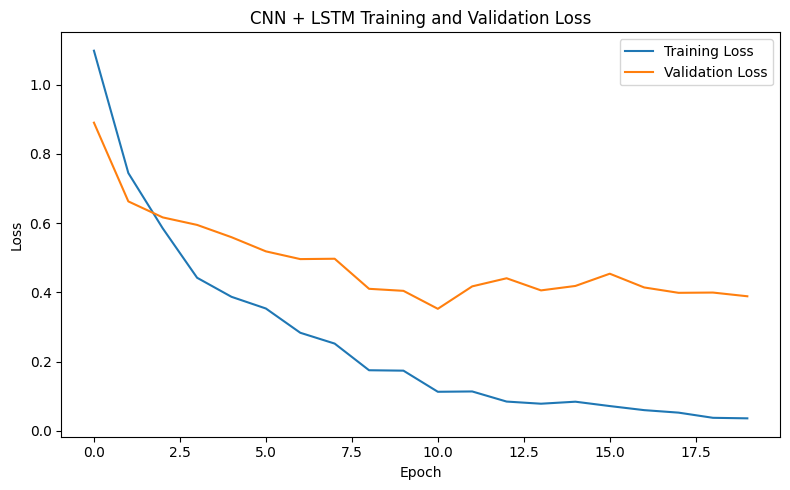

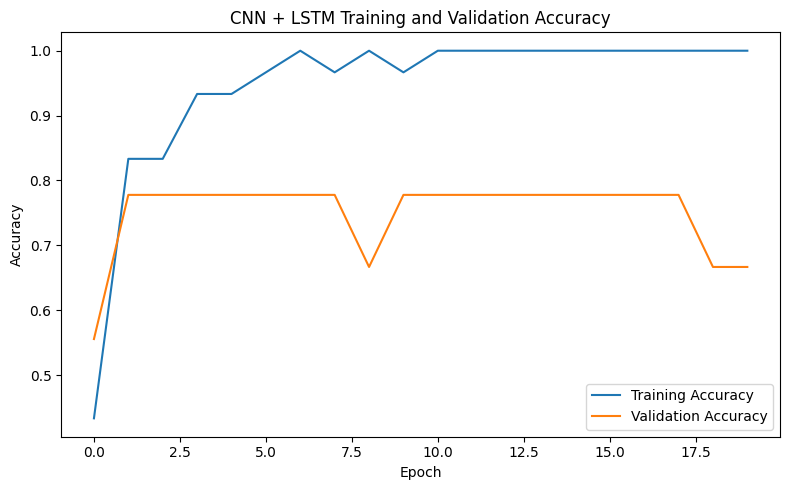

In [143]:
# Loss
plt.figure(figsize=(8, 5))

plt.plot(
    video_lstm_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    video_lstm_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN + LSTM Training and Validation Loss")
plt.legend()
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "20_CNN_LSTM_loss_curve.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# Accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    video_lstm_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    video_lstm_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN + LSTM Training and Validation Accuracy")
plt.legend()
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "21_CNN_LSTM_accuracy_curve.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

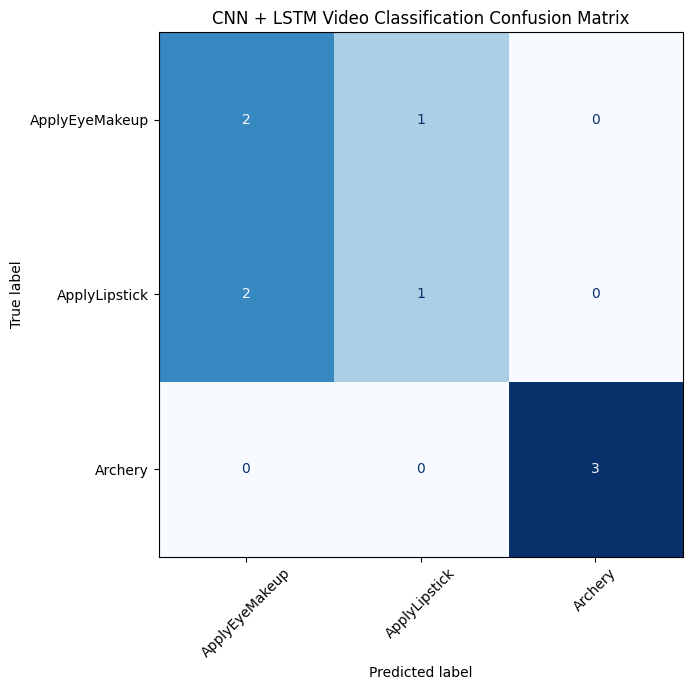

In [144]:
cm_video_lstm = confusion_matrix(
    y_video_test,
    video_lstm_pred
)

fig, ax = plt.subplots(figsize=(8, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_video_lstm,
    display_labels=VIDEO_CLASSES
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

ax.set_title("CNN + LSTM Video Classification Confusion Matrix")

plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "22_CNN_LSTM_confusion_matrix.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [145]:
from tensorflow.keras.layers import GRU

video_gru = Sequential([
    GRU(32, input_shape=(10, 1280)),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(len(VIDEO_CLASSES), activation="softmax")
])

video_gru.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

video_gru.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_2 (GRU)                     │ (None, 32)             │       126,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 126,723 (495.01 KB)

 Trainable params: 126,723 (495.01 KB)

 Non-trainable params: 0 (0.00 B)

In [146]:
start_time = time.time()

video_gru_history = video_gru.fit(
    X_video_train_features,
    y_video_train,
    validation_data=(
        X_video_val_features,
        y_video_val
    ),
    epochs=20,
    batch_size=8,
    verbose=1
)

video_gru_time = time.time() - start_time

print(
    f"\nVideo CNN + GRU Training Time: "
    f"{video_gru_time:.2f} seconds"
)

print(
    f"Parameters: "
    f"{video_gru.count_params():,}"
)

Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 137ms/step - accuracy: 0.3667 - loss: 0.9939 - val_accuracy: 0.4444 - val_loss: 0.8231
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.8667 - loss: 0.5156 - val_accuracy: 0.5556 - val_loss: 0.6440
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9333 - loss: 0.3345 - val_accuracy: 0.7778 - val_loss: 0.5182
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 1.0000 - loss: 0.1942 - val_accuracy: 0.8889 - val_loss: 0.4411
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 1.0000 - loss: 0.1687 - val_accuracy: 0.8889 - val_loss: 0.3798
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 1.0000 - loss: 0.1330 - val_accuracy: 0.8889 - val_loss: 0.3573
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 1.0000 - loss: 0.1083 - val_accuracy: 0.8889 - val_loss: 0.3700
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 1.0000 - loss: 0.0373 - val_accuracy: 0.7778 - val_loss: 0.3783

In [147]:
video_gru_prob = video_gru.predict(
    X_video_test_features,
    verbose=0
)

video_gru_pred = np.argmax(
    video_gru_prob,
    axis=1
)

video_gru_accuracy = accuracy_score(
    y_video_test,
    video_gru_pred
)

video_gru_precision = precision_score(
    y_video_test,
    video_gru_pred,
    average="macro",
    zero_division=0
)

video_gru_recall = recall_score(
    y_video_test,
    video_gru_pred,
    average="macro",
    zero_division=0
)

video_gru_f1 = f1_score(
    y_video_test,
    video_gru_pred,
    average="macro",
    zero_division=0
)

video_gru_results = {
    "Model": "CNN + GRU",
    "Accuracy": video_gru_accuracy,
    "Macro Precision": video_gru_precision,
    "Macro Recall": video_gru_recall,
    "Macro F1": video_gru_f1,
    "Parameters": video_gru.count_params(),
    "Training Time (s)": video_gru_time
}

print("CNN + GRU Results")
print("-" * 45)

for key, value in video_gru_results.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print("\nClassification Report:")
print(
    classification_report(
        y_video_test,
        video_gru_pred,
        target_names=VIDEO_CLASSES,
        zero_division=0
    )
)

CNN + GRU Results
---------------------------------------------
Model: CNN + GRU
Accuracy: 0.6667
Macro Precision: 0.6667
Macro Recall: 0.6667
Macro F1: 0.6571
Parameters: 126723
Training Time (s): 5.0578

Classification Report:
                precision    recall  f1-score   support

ApplyEyeMakeup       0.50      0.67      0.57         3
 ApplyLipstick       0.50      0.33      0.40         3
       Archery       1.00      1.00      1.00         3

      accuracy                           0.67         9
     macro avg       0.67      0.67      0.66         9
  weighted avg       0.67      0.67      0.66         9



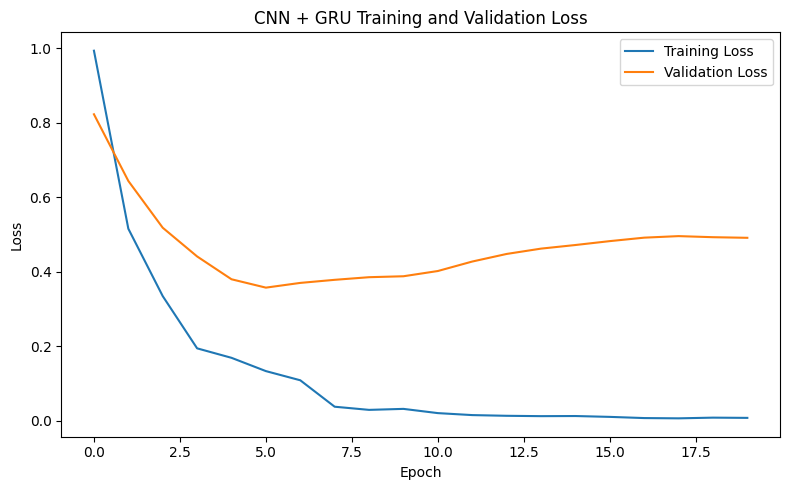

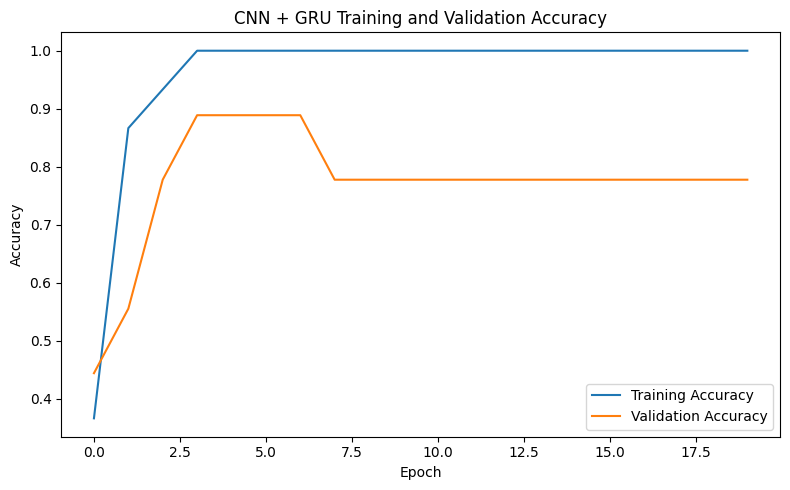

In [148]:
# Loss curve
plt.figure(figsize=(8, 5))

plt.plot(
    video_gru_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    video_gru_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN + GRU Training and Validation Loss")
plt.legend()
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "23_CNN_GRU_loss_curve.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# Accuracy curve
plt.figure(figsize=(8, 5))

plt.plot(
    video_gru_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    video_gru_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN + GRU Training and Validation Accuracy")
plt.legend()
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "24_CNN_GRU_accuracy_curve.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

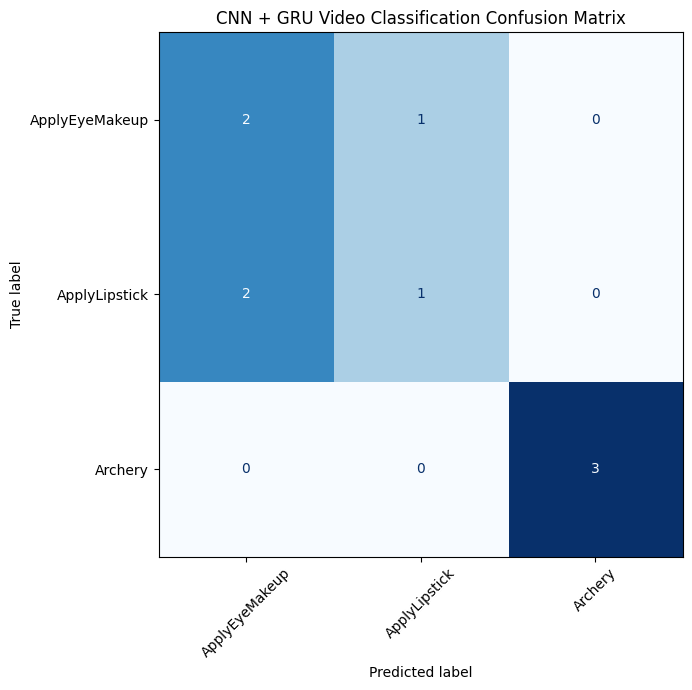

In [149]:
cm_video_gru = confusion_matrix(
    y_video_test,
    video_gru_pred
)

fig, ax = plt.subplots(figsize=(8, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_video_gru,
    display_labels=VIDEO_CLASSES
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

ax.set_title("CNN + GRU Video Classification Confusion Matrix")

plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "25_CNN_GRU_confusion_matrix.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [150]:
video_comparison_df = pd.DataFrame([
    video_lstm_results,
    video_gru_results
])

print("CNN + LSTM vs CNN + GRU")
display(video_comparison_df)

video_comparison_df.to_csv(
    GRAPH_DIR / "video_model_comparison.csv",
    index=False
)

CNN + LSTM vs CNN + GRU


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Parameters,Training Time (s)
0,CNN + LSTM,0.666667,0.666667,0.666667,0.657143,168643,9.103663
1,CNN + GRU,0.666667,0.666667,0.666667,0.657143,126723,5.057828


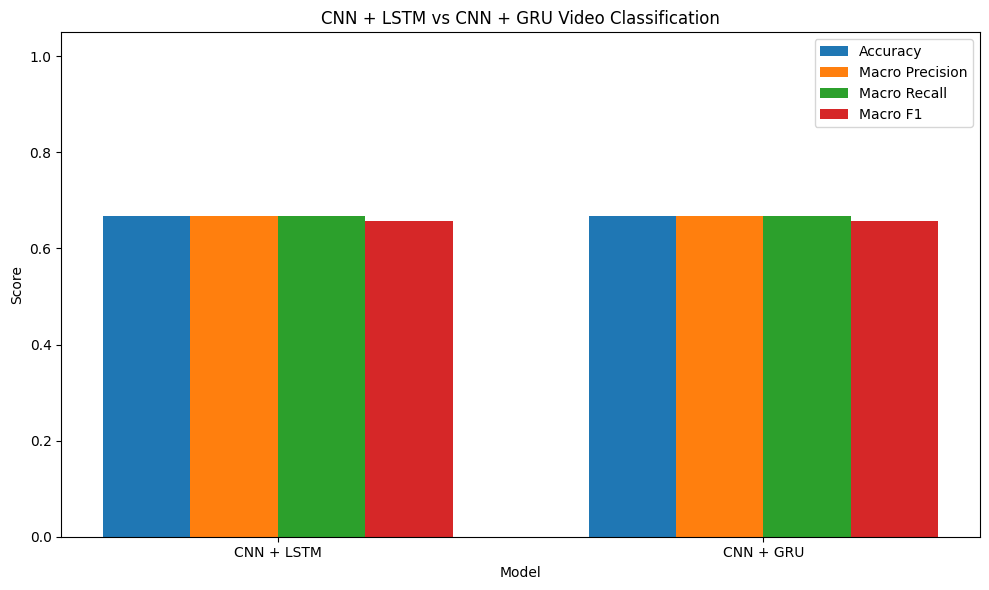

In [151]:
video_metrics = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

models = video_comparison_df["Model"].values
x = np.arange(len(models))
width = 0.18

plt.figure(figsize=(10, 6))

for i, metric in enumerate(video_metrics):

    plt.bar(
        x + (i - 1.5) * width,
        video_comparison_df[metric].values,
        width,
        label=metric
    )

plt.xticks(x, models)
plt.ylabel("Score")
plt.xlabel("Model")
plt.title("CNN + LSTM vs CNN + GRU Video Classification")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "26_video_model_comparison.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [152]:
import numpy as np

np.random.seed(42)

# Keep this small for runtime
N_SEQ2SEQ = 3000
SEQ_LEN = 10
VOCAB_SIZE = 20

# Generate random integer sequences
X_seq2seq = np.random.randint(
    1,
    VOCAB_SIZE + 1,
    size=(N_SEQ2SEQ, SEQ_LEN)
)

# Target is the reversed input
y_seq2seq = np.flip(
    X_seq2seq,
    axis=1
).copy()

print("Input shape :", X_seq2seq.shape)
print("Target shape:", y_seq2seq.shape)

print("\nExample:")
print("Input :", X_seq2seq[0])
print("Target:", y_seq2seq[0])

Input shape : (3000, 10)
Target shape: (3000, 10)

Example:
Input : [ 7 20 15 11  8  7 19 11 11  4]
Target: [ 4 11 11 19  7  8 11 15 20  7]


In [153]:
from sklearn.model_selection import train_test_split

X_s2s_train, X_s2s_temp, y_s2s_train, y_s2s_temp = train_test_split(
    X_seq2seq,
    y_seq2seq,
    test_size=0.30,
    random_state=42
)

X_s2s_val, X_s2s_test, y_s2s_val, y_s2s_test = train_test_split(
    X_s2s_temp,
    y_s2s_temp,
    test_size=0.50,
    random_state=42
)

print("Train:", X_s2s_train.shape)
print("Validation:", X_s2s_val.shape)
print("Test:", X_s2s_test.shape)

Train: (2100, 10)
Validation: (450, 10)
Test: (450, 10)


In [154]:
from tensorflow.keras.layers import (
    Input,
    Embedding,
    LSTM,
    RepeatVector,
    TimeDistributed
)
from tensorflow.keras.models import Model

embedding_dim = 32
hidden_units = 32

# Encoder
encoder_inputs = Input(
    shape=(SEQ_LEN,),
    name="encoder_input"
)

encoder_embedding = Embedding(
    input_dim=VOCAB_SIZE + 1,
    output_dim=embedding_dim
)(encoder_inputs)

encoder_lstm = LSTM(
    hidden_units,
    return_sequences=False
)

encoder_output = encoder_lstm(
    encoder_embedding
)

# Repeat encoder representation for decoder
decoder_input = RepeatVector(
    SEQ_LEN
)(encoder_output)

# Decoder
decoder_lstm = LSTM(
    hidden_units,
    return_sequences=True
)

decoder_output = decoder_lstm(
    decoder_input
)

# Output at every time step
decoder_output = TimeDistributed(
    Dense(VOCAB_SIZE + 1, activation="softmax")
)(decoder_output)

seq2seq_model = Model(
    encoder_inputs,
    decoder_output
)

seq2seq_model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

seq2seq_model.summary()

Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 10, 32)         │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 10, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 10, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 10, 21)         │           693 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,005 (70.33 KB)

 Trainable params: 18,005 (70.33 KB)

 Non-trainable params: 0 (0.00 B)

In [155]:
y_s2s_train_exp = np.expand_dims(
    y_s2s_train,
    axis=-1
)

y_s2s_val_exp = np.expand_dims(
    y_s2s_val,
    axis=-1
)

y_s2s_test_exp = np.expand_dims(
    y_s2s_test,
    axis=-1
)

print("Target shape:")
print(y_s2s_train_exp.shape)

start_time = time.time()

seq2seq_history = seq2seq_model.fit(
    X_s2s_train,
    y_s2s_train_exp,
    validation_data=(
        X_s2s_val,
        y_s2s_val_exp
    ),
    epochs=20,
    batch_size=32,
    verbose=1
)

seq2seq_time = time.time() - start_time

print(f"\nSeq2Seq training time: {seq2seq_time:.2f} seconds")

Target shape:
(2100, 10, 1)
Epoch 1/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.0679 - loss: 3.0125 - val_accuracy: 0.1009 - val_loss: 2.9486
Epoch 2/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.1245 - loss: 2.8448 - val_accuracy: 0.1338 - val_loss: 2.7937
Epoch 3/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.1511 - loss: 2.7465 - val_accuracy: 0.1511 - val_loss: 2.7246
Epoch 4/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.1665 - loss: 2.6797 - val_accuracy: 0.1722 - val_loss: 2.6618
Epoch 5/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.1795 - loss: 2.6226 - val_accuracy: 0.1793 - val_loss: 2.6195
Epoch 6/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.1883 - loss: 2.5800 - val_accuracy: 0.1891 - val_loss: 2.5839
Epoch 7/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.1982 - loss: 2.5384 - val_accuracy: 0.1936 - val_loss: 2.5473
Epoch 8/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.2051 - loss: 2.498

In [156]:
seq2seq_prob = seq2seq_model.predict(
    X_s2s_test,
    verbose=0
)

seq2seq_pred = np.argmax(
    seq2seq_prob,
    axis=-1
)

# Entire sequence must be correct
sequence_correct = np.all(
    seq2seq_pred == y_s2s_test,
    axis=1
)

sequence_accuracy = np.mean(
    sequence_correct
)

# Token-level accuracy
token_accuracy = np.mean(
    seq2seq_pred == y_s2s_test
)

print("Seq2Seq Reversal Results")
print("-" * 40)
print(f"Sequence Accuracy: {sequence_accuracy:.4f}")
print(f"Token Accuracy:    {token_accuracy:.4f}")
print(f"Parameters:        {seq2seq_model.count_params():,}")
print(f"Training Time:     {seq2seq_time:.2f} seconds")

print("\nExample Predictions:")

for i in range(min(5, len(X_s2s_test))):
    print(f"\nInput:      {X_s2s_test[i]}")
    print(f"Expected:   {y_s2s_test[i]}")
    print(f"Predicted:  {seq2seq_pred[i]}")

Seq2Seq Reversal Results
----------------------------------------
Sequence Accuracy: 0.0000
Token Accuracy:    0.2656
Parameters:        18,005
Training Time:     25.10 seconds

Example Predictions:

Input:      [ 4 20 16 10 11  5 11 13 15  6]
Expected:   [ 6 15 13 11  5 11 10 16 20  4]
Predicted:  [13 11 11 11 11 11 20 20 20  5]

Input:      [ 5 16  5 12 20  9  7 19 20 11]
Expected:   [11 20 19  7  9 20 12  5 16  5]
Predicted:  [20 20 20 20 20 20 20  5  5 20]

Input:      [ 8 12 10 14  9  6  5  1  1 20]
Expected:   [20  1  1  5  6  9 14 10 12  8]
Predicted:  [12 12 12 12 12 12 12 12 10 10]

Input:      [13  3  3  5 11  7 10 10 20  2]
Expected:   [ 2 20 10 10  7 11  5  3  3 13]
Predicted:  [20 20 20 20  3  3  3  3  3  3]

Input:      [ 1  7 19  2 14 18 15 14 19 19]
Expected:   [19 19 14 15 18 14  2 19  7  1]
Predicted:  [14 14 14 14 14 14 15  7  7  7]


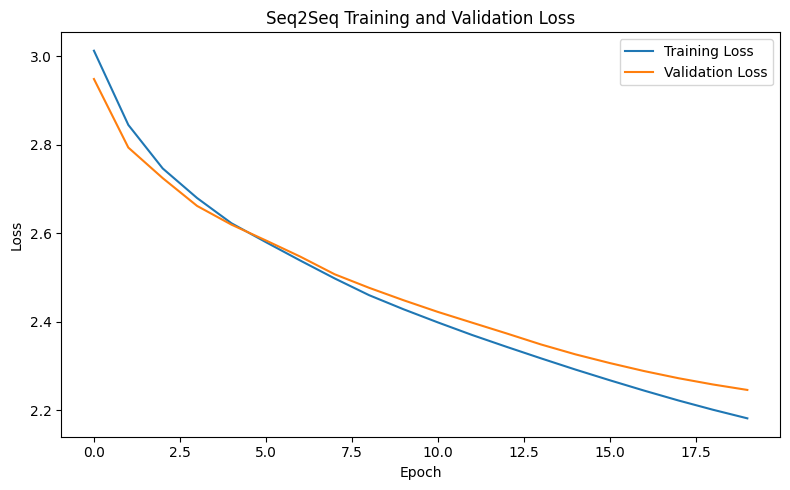

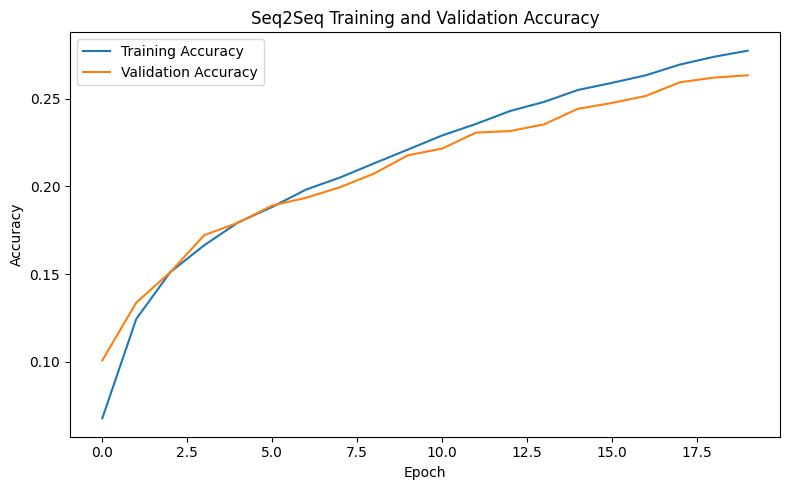

In [157]:
# Seq2Seq loss curve
plt.figure(figsize=(8, 5))

plt.plot(
    seq2seq_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    seq2seq_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Seq2Seq Training and Validation Loss")
plt.legend()
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "27_Seq2Seq_loss_curve.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# Seq2Seq accuracy curve
plt.figure(figsize=(8, 5))

plt.plot(
    seq2seq_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    seq2seq_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Seq2Seq Training and Validation Accuracy")
plt.legend()
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "28_Seq2Seq_accuracy_curve.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

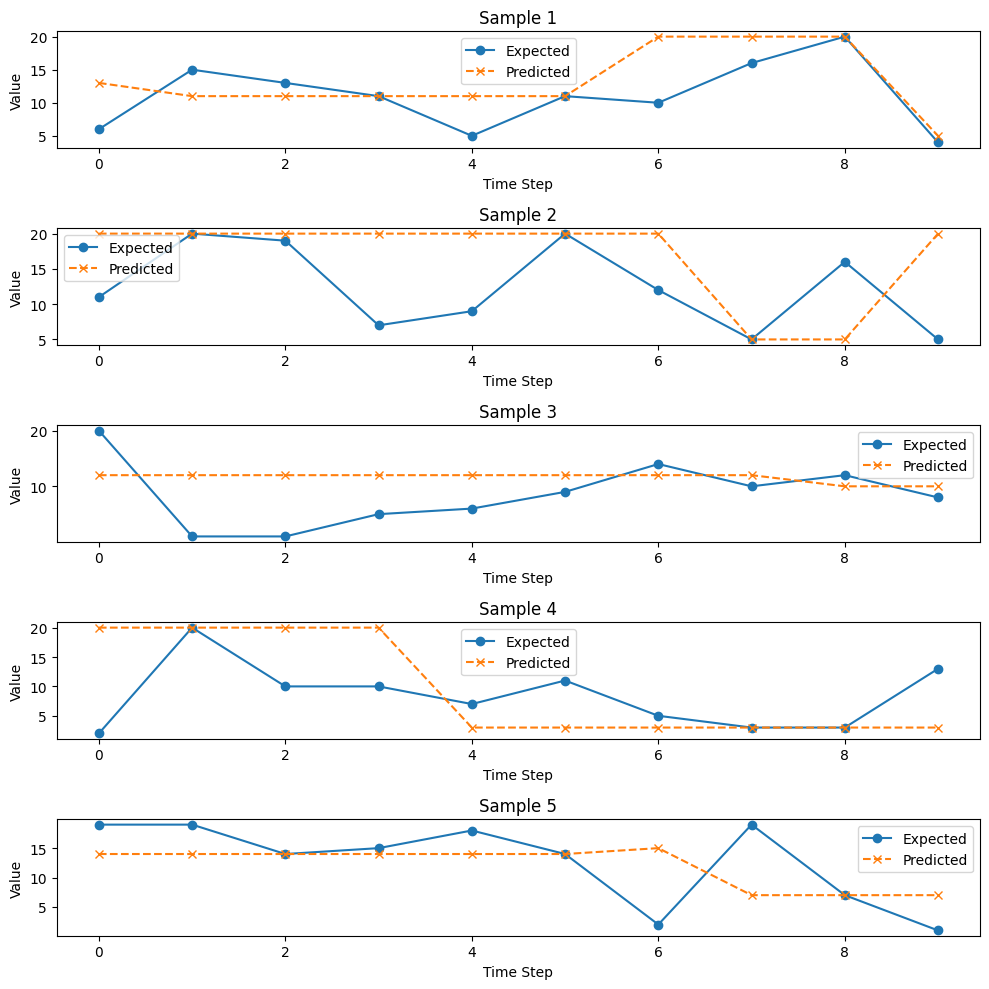

In [158]:
n_show = 5

fig, axes = plt.subplots(
    n_show,
    1,
    figsize=(10, 10)
)

for i in range(n_show):

    axes[i].plot(
        range(SEQ_LEN),
        y_s2s_test[i],
        marker="o",
        label="Expected"
    )

    axes[i].plot(
        range(SEQ_LEN),
        seq2seq_pred[i],
        marker="x",
        linestyle="--",
        label="Predicted"
    )

    axes[i].set_title(
        f"Sample {i+1}"
    )

    axes[i].set_xlabel("Time Step")
    axes[i].set_ylabel("Value")
    axes[i].legend()

plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "29_Seq2Seq_predictions.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [159]:
seq2seq_results = pd.DataFrame([{
    "Experiment": "Seq2Seq Reversal",
    "Sequence Accuracy": sequence_accuracy,
    "Token Accuracy": token_accuracy,
    "Parameters": seq2seq_model.count_params(),
    "Training Time (s)": seq2seq_time
}])

display(seq2seq_results)

seq2seq_results.to_csv(
    GRAPH_DIR / "Seq2Seq_results.csv",
    index=False
)

,Experiment,Sequence Accuracy,Token Accuracy,Parameters,Training Time (s)
0,Seq2Seq Reversal,0.0,0.265556,18005,25.095276


In [160]:
eps_files = sorted(GRAPH_DIR.glob("*.eps"))

print(f"Total EPS graphs generated: {len(eps_files)}\n")

for i, file in enumerate(eps_files, 1):
    print(f"{i:02d}. {file.name}")

Total EPS graphs generated: 31

01. 01_class_distribution.eps
02. 02_sensor_signals.eps
03. 03_RNN_loss_curve.eps
04. 04_RNN_accuracy_curve.eps
05. 05_RNN_confusion_matrix.eps
06. 06_LSTM_loss_curve.eps
07. 07_LSTM_accuracy_curve.eps
08. 08_LSTM_confusion_matrix.eps
09. 09_GRU_loss_curve.eps
10. 10_GRU_accuracy_curve.eps
11. 11_GRU_confusion_matrix.eps
12. 12_model_performance_comparison.eps
13. 13_parameter_comparison.eps
14. 14_training_time_comparison.eps
15. 15_sequence_length_performance.eps
16. 16_sequence_length_training_time.eps
17. 17_sequence_length_loss_curves.eps
18. 18_sequence_length_accuracy_curves.eps
19. 19_confusion_matrix_seq_128.eps
20. 19_confusion_matrix_seq_32.eps
21. 19_confusion_matrix_seq_64.eps
22. 20_CNN_LSTM_loss_curve.eps
23. 21_CNN_LSTM_accuracy_curve.eps
24. 22_CNN_LSTM_confusion_matrix.eps
25. 23_CNN_GRU_loss_curve.eps
26. 24_CNN_GRU_accuracy_curve.eps
27. 25_CNN_GRU_confusion_matrix.eps
28. 26_video_model_comparison.eps
29. 27_Seq2Seq_loss_curve.eps
30

In [161]:
additional_video_df = pd.DataFrame([
    {
        "Model": "CNN + LSTM",
        "Accuracy": video_lstm_accuracy,
        "Macro F1": video_lstm_f1,
        "Parameters": video_lstm.count_params(),
        "Training Time (s)": video_lstm_time
    },
    {
        "Model": "CNN + GRU",
        "Accuracy": video_gru_accuracy,
        "Macro F1": video_gru_f1,
        "Parameters": video_gru.count_params(),
        "Training Time (s)": video_gru_time
    }
])

display(additional_video_df)

additional_video_df.to_csv(
    GRAPH_DIR / "additional_experiment_video_efficiency.csv",
    index=False
)

,Model,Accuracy,Macro F1,Parameters,Training Time (s)
0,CNN + LSTM,0.666667,0.657143,168643,9.103663
1,CNN + GRU,0.666667,0.657143,126723,5.057828


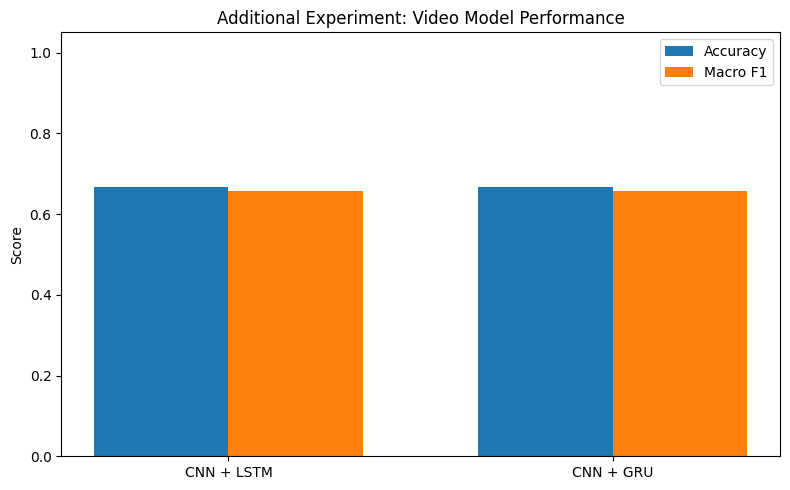

In [162]:
x = np.arange(len(additional_video_df))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width/2,
    additional_video_df["Accuracy"],
    width,
    label="Accuracy"
)

plt.bar(
    x + width/2,
    additional_video_df["Macro F1"],
    width,
    label="Macro F1"
)

plt.xticks(x, additional_video_df["Model"])
plt.ylabel("Score")
plt.title("Additional Experiment: Video Model Performance")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()

plt.savefig(
    GRAPH_DIR / "30_additional_experiment_performance.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

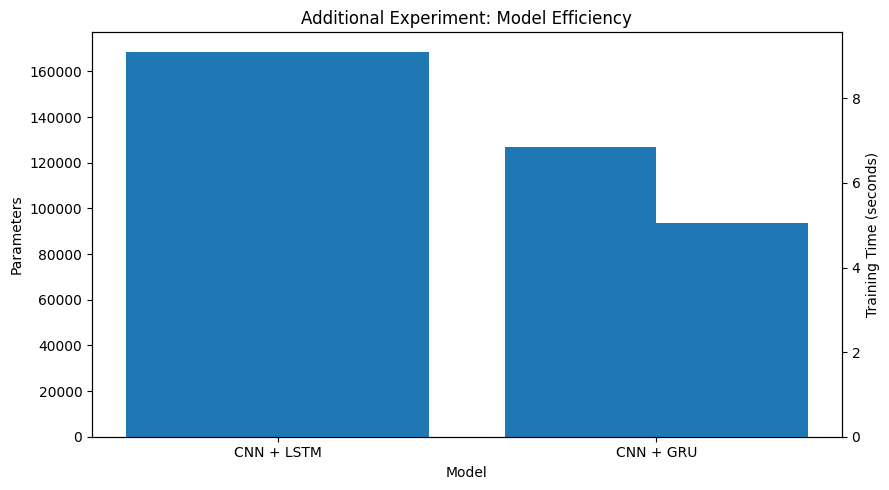

In [163]:
fig, ax1 = plt.subplots(figsize=(9, 5))

x = np.arange(len(additional_video_df))

bars1 = ax1.bar(
    x - 0.2,
    additional_video_df["Parameters"],
    0.4,
    label="Parameters"
)

ax1.set_xlabel("Model")
ax1.set_ylabel("Parameters")
ax1.set_xticks(x)
ax1.set_xticklabels(additional_video_df["Model"])

ax2 = ax1.twinx()

bars2 = ax2.bar(
    x + 0.2,
    additional_video_df["Training Time (s)"],
    0.4,
    label="Training Time"
)

ax2.set_ylabel("Training Time (seconds)")

plt.title("Additional Experiment: Model Efficiency")
fig.tight_layout()

plt.savefig(
    GRAPH_DIR / "31_additional_experiment_efficiency.eps",
    format="eps",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [164]:
final_model_comparison = comparison_df.copy()

# Round only for display
display_df = final_model_comparison.copy()

for col in [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]:
    display_df[col] = display_df[col].round(4)

display_df["Training Time (s)"] = \
    display_df["Training Time (s)"].round(2)

display(display_df)

display_df.to_csv(
    GRAPH_DIR / "FINAL_RNN_LSTM_GRU_RESULTS.csv",
    index=False
)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Parameters,Training Time (s),Training Time (min)
0,RNN,0.7987,0.7889,0.7897,0.7891,1974,69.77,1.162844
1,LSTM,0.9282,0.9320,0.9324,0.9317,6006,133.65,2.227455
2,GRU,0.9417,0.9452,0.9447,0.9449,4758,211.60,NaN


In [165]:
# Save sequence-length results
sequence_df.to_csv(
    GRAPH_DIR / "FINAL_SEQUENCE_LENGTH_RESULTS.csv",
    index=False
)

# Save video results
video_comparison_df.to_csv(
    GRAPH_DIR / "FINAL_VIDEO_RESULTS.csv",
    index=False
)

# Save Seq2Seq results
seq2seq_results.to_csv(
    GRAPH_DIR / "FINAL_SEQ2SEQ_RESULTS.csv",
    index=False
)

# Save additional experiment
additional_video_df.to_csv(
    GRAPH_DIR / "FINAL_ADDITIONAL_EXPERIMENT_RESULTS.csv",
    index=False
)

print("All result tables saved successfully.")

All result tables saved successfully.


In [166]:
eps_files = sorted(GRAPH_DIR.glob("*.eps"))

print("=" * 60)
print("FINAL GRAPH CHECK")
print("=" * 60)

print(f"\nTotal EPS graphs: {len(eps_files)}")

for i, file in enumerate(eps_files, 1):
    size_kb = file.stat().st_size / 1024
    print(f"{i:02d}. {file.name:<55} {size_kb:.1f} KB")

print("\nGraph directory:")
print(GRAPH_DIR)

print("\nAll graphs are saved as EPS at 600 DPI.")

FINAL GRAPH CHECK

Total EPS graphs: 33
01. 01_class_distribution.eps                               29.5 KB
02. 02_sensor_signals.eps                                   36.6 KB
03. 03_RNN_loss_curve.eps                                   24.5 KB
04. 04_RNN_accuracy_curve.eps                               23.9 KB
05. 05_RNN_confusion_matrix.eps                             66535.1 KB
06. 06_LSTM_loss_curve.eps                                  24.0 KB
07. 07_LSTM_accuracy_curve.eps                              24.2 KB
08. 08_LSTM_confusion_matrix.eps                            66535.0 KB
09. 09_GRU_loss_curve.eps                                   22.4 KB
10. 10_GRU_accuracy_curve.eps                               22.8 KB
11. 11_GRU_confusion_matrix.eps                             16519.9 KB
12. 12_model_performance_comparison.eps                     24.1 KB
13. 13_parameter_comparison.eps                             23.0 KB
14. 14_training_time_comparison.eps                         23.2 KB

In [167]:
import shutil
from pathlib import Path

ZIP_PATH = "/content/experiment6_all_graphs_600dpi"

# Create ZIP containing all EPS graphs
zip_file = shutil.make_archive(
    ZIP_PATH,
    "zip",
    GRAPH_DIR
)

print("ZIP created successfully!")
print(zip_file)

# Count EPS files
eps_count = len(list(GRAPH_DIR.glob("*.eps")))

print(f"\nEPS graphs included: {eps_count}")
print(f"ZIP size: {Path(zip_file).stat().st_size / (1024*1024):.2f} MB")

ZIP created successfully!
/content/experiment6_all_graphs_600dpi.zip

EPS graphs included: 33
ZIP size: 2.31 MB


In [168]:
import zipfile

with zipfile.ZipFile(
    "/content/experiment6_all_graphs_600dpi.zip",
    "r"
) as z:

    files_in_zip = z.namelist()

    eps_in_zip = [
        f for f in files_in_zip
        if f.lower().endswith(".eps")
    ]

    print("=" * 60)
    print("ZIP VERIFICATION")
    print("=" * 60)

    print(f"Total files in ZIP : {len(files_in_zip)}")
    print(f"EPS graphs in ZIP  : {len(eps_in_zip)}")

    print("\nFiles:")
    for f in eps_in_zip:
        print("✓", f)

    print("\nZIP is valid:", zipfile.is_zipfile(
        "/content/experiment6_all_graphs_600dpi.zip"
    ))

ZIP VERIFICATION
Total files in ZIP : 43
EPS graphs in ZIP  : 33

Files:
✓ 27_Seq2Seq_loss_curve.eps
✓ 07_LSTM_accuracy_curve.eps
✓ 30_additional_experiment_performance.eps
✓ 01_class_distribution.eps
✓ 02_sensor_signals.eps
✓ 25_CNN_GRU_confusion_matrix.eps
✓ 24_CNN_GRU_accuracy_curve.eps
✓ 09_GRU_loss_curve.eps
✓ 29_Seq2Seq_predictions.eps
✓ 18_sequence_length_accuracy_curves.eps
✓ 03_RNN_loss_curve.eps
✓ 21_CNN_LSTM_accuracy_curve.eps
✓ 10_GRU_accuracy_curve.eps
✓ 26_video_model_comparison.eps
✓ 06_LSTM_loss_curve.eps
✓ 11_GRU_confusion_matrix.eps
✓ 05_RNN_confusion_matrix.eps
✓ 08_LSTM_confusion_matrix.eps
✓ 16_sequence_length_training_time.eps
✓ 15_sequence_length_performance.eps
✓ 23_CNN_GRU_loss_curve.eps
✓ 14_training_time_comparison.eps
✓ 20_CNN_LSTM_loss_curve.eps
✓ 19_confusion_matrix_seq_128.eps
✓ 22_CNN_LSTM_confusion_matrix.eps
✓ 31_additional_experiment_efficiency.eps
✓ 19_confusion_matrix_seq_32.eps
✓ 13_parameter_comparison.eps
✓ 12_model_performance_comparison.eps
✓ 0

In [169]:
# # ============================================================
# # VIDEO DEPENDENCIES
# # ============================================================

# !pip -q install opencv-python-headless

In [ ]:
# ============================================================
# ZIP ALL EPS GRAPHS
# ============================================================

EPS_ZIP = BASE_DIR / "Experiment_6_All_Graphs_600DPI_EPS.zip"

if EPS_ZIP.exists():
    EPS_ZIP.unlink()

with zipfile.ZipFile(
    EPS_ZIP,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zipf:

    for eps_file in eps_files:

        zipf.write(
            eps_file,
            arcname=eps_file.name
        )

print(
    "ZIP created:",
    EPS_ZIP
)

print(
    "Number of graphs:",
    len(eps_files)
)

print(
    "ZIP size:",
    f"{EPS_ZIP.stat().st_size / (1024**2):.2f} MB"
)